<a href="https://colab.research.google.com/github/Ngwijabagabo/Groundwater_Storage_pred/blob/main/GW_Potential_RF_MaxEnt_Revision_FNL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 💧 Groundwater Potential, Eastern Province (Rwanda): RF + MaxEnt, current & CMIP6 futures
**Revision workflow for JPCE-D-26-00483: reproduces every result section of the manuscript and adds the analyses requested by the reviewers.**

| Part | Content | Reviewer points addressed |
|---|---|---|
| A | Wells, yield classes & thresholds, pseudo-absences, predictor extraction | R2-Q2.1, Q2.2, R3-1, Fig. 3 |
| B | Collinearity (Spearman + VIF), spatial structure of wells | R3-12, R2-Q3.8 |
| C | **RF groundwater-potential model** (wells vs pseudo-absences), tuned, full configuration | R2-Q2.4 |
| D | **MaxEnt** (elapid, documented settings) on the *same* data and *same* test set | R2-Q2.5, R3-4, R2-Q3.7 |
| E | Validation: bootstrap 95 % CI, spatial block CV, calibration, paired ΔAUC test | R2-Q3.2–3.6, Q3.9, R3-5 |
| F | Importance: MDI vs permutation (± SD) for RF and MaxEnt, response curves, GWS-circularity test | R2-Q4 Fig. 6, R3-8 |
| G | **5-class yield RF** (manuscript design) with SMOTE *inside* the training folds, ablation, class sizes, CIs | R2-Q2.3, Q3.3, R3-2, R3-3 |
| H | Current GWPZ maps (same classes & legend), district areas, yield check of zones | R2-Q4.1, Fig. 11–12 |
| I | RF–MaxEnt agreement map + kappa | R2-Q4.2, R3-11 |
| J | CMIP6 futures: delta-change rainfall (no IDW), only rainfall changes, extrapolation check, maps matrix, baseline + absolute + relative change, synthesis heatmap, vulnerability index | R2-Q2.7–2.8, Q4.3–4.5, R3-6, R3-9, R3-10, R3-13 |
| K | Workflow figure, software environment, Excel workbooks, GeoTIFFs | R2-Q2.9, Q3.10, Q4 workflow |

**Inputs in `/content/`:** `GW_SSPs.csv`, the 11 predictor rasters, optional `TWI.tif`, and the future-rainfall rasters (see configuration).

In [ ]:
!pip -q install geopandas rasterio openpyxl scikit-learn imbalanced-learn statsmodels elapid shapely

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 437.3/437.3 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 109.9 MB/s eta 0:00:00


## 1. Configuration

In [ ]:
CSV_PATH = "/content/GW_SSPs.csv"

# ---- current predictors (key = CSV column name) ----
USER_RASTERS = {
    "DEM":                  "/content/DEM_projected.tif",
    "Distance_River":       "/content/River_D.tif",
    "Drainage_Density":     "/content/Drainage.tif",
    "Geology":              "/content/Geology.tif",
    "Ground_water_storage": "/content/GroundW_S.tif",
    "LULC":                 "/content/LULC.tif",
    "NDVI":                 "/content/NDVI.tif",
    "Rainfall":             "/content/Rainfall.tif",
    "Slope":                "/content/Slope.tif",
    "Soi_depth":            "/content/Soi_Dep.tif",
    "Soil_Texture":         "/content/Soil_T.tif",
}
OPTIONAL_RASTERS = {"TWI": "/content/TWI.tif"}       # used if the file exists (12th predictor)
CATEGORICAL = ["Geology", "LULC", "Soil_Texture", "Soi_depth"]

# ---- future rainfall (CMIP6, annual precipitation, mm) ----
FUTURE_RAINFALL = {
    ("SSP1-2.6", "2040-2059"): "/content/ssp126_2040.tif",
    ("SSP1-2.6", "2080-2099"): "/content/ssp126_2080.tif",
    ("SSP2-4.5", "2040-2059"): "/content/ssp245_2040.tif",
    ("SSP2-4.5", "2080-2099"): "/content/ssp245_2080.tif",
    ("SSP5-8.5", "2040-2059"): "/content/ssp585_2040.tif",
    ("SSP5-8.5", "2080-2099"): "/content/ssp585_2080.tif",
}
CLIMATE_BASELINE = "/content/wc2.1_bio12_baseline.tif"

# ---- GWPZ classes on the predicted probability ----
CLASS_NAMES  = ["Very Low", "Low", "Moderate", "High", "Very High"]
CLASS_COLORS = ["#d7191c", "#fdae61", "#ffffbf", "#a6d96a", "#1a9641"]
PROB_BREAKS  = [0.2, 0.4, 0.6, 0.8]

# ---- yield classes (m³/h) ----
YIELD_BREAKS = [0.9, 1.6, 2.1, 2.6]

# ---- pseudo-absences ----
ABSENCE_RATIO             = 1.0
ABSENCE_STRATEGY          = "area"
MIN_DIST_TO_PRESENCE      = 1000
MIN_DIST_BETWEEN_ABSENCES = 500
OVERSAMPLE                = 4
WATER_CODES               = []
N_BACKGROUND              = 10000

# ---- restored train/test split to 70/30 baseline ----
TEST_SIZE   = 0.30
SEED        = 42
N_SEARCH    = 60
N_BOOT      = 2000
BLOCK_SIZE  = 15000
N_SPATIAL_FOLDS = 5
PRED_RES    = 100
OUT_DIR     = "/content/outputs"

In [ ]:
# Update the rainfall paths and apply user constraints as requested
USER_RASTERS["Rainfall"] = "/content/ACCESS_CM2_Rainfall_Current_1950_2024.tif"

# Configure ACCESS-CM2 scenarios specifically
FUTURE_RAINFALL = {
    ("SSP2-4.5", "2080-2099"): "/content/ACCESS_CM2_Rainfall_SSP245_2080.tif",
    ("SSP5-8.5", "2040-2059"): "/content/ACCESS_CM2_Rainfall_SSP585_2040.tif",
    ("SSP5-8.5", "2080-2099"): "/content/ACCESS_CM2_Rainfall_SSP585_2080.tif",
}

# Keep CLIMATE_BASELINE to baseline raster if applicable
CLIMATE_BASELINE = "/content/ACCESS_CM2_Rainfall_Current_1950_2024.tif"

print("Climate configuration updated to ACCESS-CM2.")

Climate configuration updated to ACCESS-CM2.


In [ ]:
# Re-extract and prepare final balanced training data utilizing only verified boreholes
# Since there are no pseudo-absences, we model directly on the 152 borehole yield classes (or define binary GWP from yield thresholds)

# Let's verify the columns and setup the target variable based on the GWP threshold
verified_wells = data.copy()
verified_wells['Class'] = (verified_wells['yield'] >= 1.6).astype(int)  # Yield >= 1.6 m3/h defined as potential

print(f"Verified wells target distribution (Class >= 1.6 m3/h): {verified_wells['Class'].value_counts().to_dict()}")


Verified wells target distribution (Class >= 1.6 m3/h): {1: 91, 0: 61}


In [ ]:
# Train the Random Forest model and MaxEnt model on this subset
from sklearn.ensemble import RandomForestClassifier

X_verified = verified_wells[FEATURES]
y_verified = verified_wells['Class'].values

# Tune or fit Random Forest
rf_verified = RandomForestClassifier(random_state=SEED, n_estimators=300, max_depth=10, bootstrap=True, oob_score=True)
rf_verified.fit(X_verified, y_verified)
print(f"New RF Model OOB Accuracy: {rf_verified.oob_score_:.4f}")


New RF Model OOB Accuracy: 0.6382


## 2. Imports & helpers

In [ ]:
import os, sys, glob, math, json, warnings, platform, itertools
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch, FancyBboxPatch
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin
from rasterio import features as rfeatures
from shapely import contains_xy, prepare
from scipy import stats
from scipy.spatial import cKDTree
import sklearn
from sklearn.model_selection import (train_test_split, RandomizedSearchCV, StratifiedKFold,
                                     GroupKFold, cross_val_predict)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             cohen_kappa_score, roc_auc_score, roc_curve, brier_score_loss,
                             confusion_matrix, classification_report)
from sklearn.calibration import calibration_curve
from sklearn.base import clone
import imblearn
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import elapid
from statsmodels.stats.outliers_influence import variance_inflation_factor
import joblib
warnings.filterwarnings("ignore")
os.makedirs(OUT_DIR, exist_ok=True)
FIG = f"{OUT_DIR}/figures"; os.makedirs(FIG, exist_ok=True)
rng = np.random.default_rng(SEED)
RESULTS = {}                                         # every table for the Excel workbook

def _union(g): return g.union_all() if hasattr(g, "union_all") else g.unary_union
def savefig(name): plt.savefig(f"{FIG}/{name}.png", dpi=300, bbox_inches="tight")
def classify(p): return np.digitize(p, PROB_BREAKS) + 1          # 1..5
print("✅ ready | sklearn", sklearn.__version__, "| imblearn", imblearn.__version__, "| elapid", elapid.__version__)

✅ ready | sklearn 1.9.1 | imblearn 0.14.2 | elapid 1.0.4


# Part A – Data
## 3. Wells, yield classes and thresholds (Fig. 3, R3-1)

In [ ]:
df = pd.read_csv(CSV_PATH); df.columns = df.columns.str.strip()
n0 = len(df)
dups = df[df.duplicated(subset=["X", "Y"], keep="first")]
df = df.dropna(subset=["X", "Y"]).drop_duplicates(subset=["X", "Y"]).reset_index(drop=True)
print(f"✅ {len(df)} wells ({n0-len(df)} duplicate coordinates removed: IDs {dups['ID'].tolist()})")

# Yield class from explicit thresholds and check against the CSV 'GWPZ' column
df["Yield_Class"] = np.digitize(df["yield"], YIELD_BREAKS) + 1
agree = (df["Yield_Class"] == df["GWPZ"]).mean() * 100
print(f"Thresholds reproduce the CSV GWPZ column for {agree:.1f}% of wells")

edges = [-np.inf] + YIELD_BREAKS + [np.inf]
thr = (df.groupby("Yield_Class")["yield"]
         .agg(n_wells="count", min_yield="min", median_yield="median", max_yield="max")
         .reindex(range(1, 6)).reset_index())
thr.insert(1, "Class", CLASS_NAMES)
thr.insert(2, "Yield_rule_m3h", [f"< {YIELD_BREAKS[0]}"] +
           [f"{YIELD_BREAKS[i]} – <{YIELD_BREAKS[i+1]}" for i in range(3)] + [f"≥ {YIELD_BREAKS[3]}"])
thr["Percent"] = (thr.n_wells / thr.n_wells.sum() * 100).round(1)
print(thr.to_string(index=False))
RESULTS["T_Yield_Class_Thresholds"] = thr

✅ 152 wells (1 duplicate coordinates removed: IDs [143])
Thresholds reproduce the CSV GWPZ column for 100.0% of wells
 Yield_Class     Class Yield_rule_m3h  n_wells  min_yield  median_yield  max_yield  Percent
           1  Very Low          < 0.9       28        0.0           0.6        0.8     18.4
           2       Low     0.9 – <1.6       33        0.9           1.2        1.5     21.7
           3  Moderate     1.6 – <2.1       44        1.6           2.0        2.0     28.9
           4      High     2.1 – <2.6       41        2.1           2.5        2.5     27.0
           5 Very High          ≥ 2.6        6        3.0           3.0        3.0      3.9


## 4. Predictor rasters – check & metadata (Table 1 completeness, R2-Q2.6)

In [ ]:
for k, p in OPTIONAL_RASTERS.items():
    if os.path.exists(p): USER_RASTERS[k] = p
    else: print(f"ℹ️ optional layer {k} not found ({p}) – model uses {len(USER_RASTERS)} predictors")
missing = [p for p in USER_RASTERS.values() if not os.path.exists(p)]
if missing: raise FileNotFoundError(f"Upload these rasters to /content: {missing}")
FEATURES = list(USER_RASTERS)
CATEGORICAL = [c for c in CATEGORICAL if c in FEATURES]
CONTINUOUS = [c for c in FEATURES if c not in CATEGORICAL]

meta = []
for col, path in USER_RASTERS.items():
    with rasterio.open(path) as src:
        a = src.read(1, masked=True)
        meta.append({"Layer": col, "File": Path(path).name, "Type": "categorical" if col in CATEGORICAL else "continuous",
                     "CRS": str(src.crs), "Pixel_size": f"{src.res[0]:.1f} x {src.res[1]:.1f}",
                     "Rows x Cols": f"{src.height} x {src.width}", "NoData": src.nodata,
                     "Min": float(a.min()), "Max": float(a.max()),
                     "Resampling_to_grid": "nearest" if col in CATEGORICAL else "bilinear"})
meta = pd.DataFrame(meta); print(meta.to_string(index=False))
RESULTS["T_Predictor_Metadata"] = meta

               Layer              File        Type        CRS  Pixel_size Rows x Cols  NoData       Min          Max Resampling_to_grid
                 DEM DEM_projected.tif  continuous EPSG:32735 30.1 x 30.1 5119 x 3477     NaN  0.000000  2261.000000           bilinear
      Distance_River       River_D.tif  continuous EPSG:32735 30.1 x 30.1 5119 x 3477     NaN  0.000000 22550.431641           bilinear
    Drainage_Density      Drainage.tif  continuous EPSG:32735 30.1 x 30.1 5118 x 3476     NaN  0.000000     0.000615           bilinear
             Geology       Geology.tif categorical EPSG:32735 30.1 x 30.1 5119 x 3476     NaN  0.000000    10.000000            nearest
Ground_water_storage     GroundW_S.tif  continuous EPSG:32735 30.1 x 30.1 5119 x 3477     NaN  0.000000  2100.374268           bilinear
                LULC          LULC.tif categorical EPSG:32735 30.1 x 30.1 5119 x 3477     NaN  0.000000     7.000000            nearest
                NDVI          NDVI.tif  continuo

## 5. Boundaries

In [ ]:
print("Loading boundaries...")
rwa_prov = gpd.read_file(
    "https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_RWA_1.json")
rwa_dist = gpd.read_file(
    "https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_RWA_2.json")

prov_col = next(c for c in rwa_prov.columns
                if rwa_prov[c].dtype == object
                and any("Eastern" in str(v) for v in rwa_prov[c]))
eastern_prov = rwa_prov[rwa_prov[prov_col].str.contains("Eastern", na=False)].copy()

gid_val = eastern_prov["GID_1"].values[0]
eastern_dist = rwa_dist[rwa_dist["GID_1"] == gid_val].copy()

dist_name_col = next(
    (c for c in eastern_dist.columns
     if any(v in eastern_dist[c].astype(str).tolist()
            for v in ["Nyagatare","Gatsibo","Kayonza","Ngoma","Kirehe","Bugesera","Rwamagana"])),
    [c for c in eastern_dist.columns if "NAME" in c][-1])
print(f"✅ Districts: {eastern_dist[dist_name_col].tolist()}")

DST_CRS = "EPSG:32735"
eastern_prov_utm = eastern_prov.to_crs(DST_CRS)
eastern_dist_utm = eastern_dist.to_crs(DST_CRS)
print(f"✅ Boundaries in {DST_CRS}")

Loading boundaries...
✅ Districts: ['Bugesera', 'Gatsibo', 'Kayonza', 'Kirehe', 'Ngoma', 'Nyagatare', 'Rwamagana']
✅ Boundaries in EPSG:32735


## 6. Presence points

In [ ]:
prov_geom = _union(eastern_prov_utm.geometry)
dist_gdf = (eastern_dist_utm[[dist_name_col, "geometry"]]
            .rename(columns={dist_name_col: "District"}).reset_index(drop=True))
DISTRICTS = dist_gdf.District.tolist()

pres = gpd.GeoDataFrame(df.copy(), geometry=gpd.points_from_xy(df["X"], df["Y"]), crs=DST_CRS)
inside = pres.within(prov_geom.buffer(1000))
if (~inside).any(): print(f"⚠️ {(~inside).sum()} wells outside the province removed")
pres = pres[inside].reset_index(drop=True)
pres = gpd.sjoin_nearest(pres, dist_gdf, how="left").drop(columns="index_right")
pres = pres[~pres.index.duplicated()]
pres["Class"] = 1
print(pd.crosstab(pres.District, pres.Yield_Class.map(dict(enumerate(CLASS_NAMES, 1))), margins=True))
RESULTS["T_Wells_by_District_Class"] = pd.crosstab(pres.District, pres.Yield_Class.map(dict(enumerate(CLASS_NAMES, 1))), margins=True).reset_index()

Yield_Class  High  Low  Moderate  Very High  Very Low  All
District                                                  
Gatsibo         3    4         9          1         1   18
Kayonza         6    5         6          2         5   24
Kirehe         10    5         2          0         7   24
Ngoma           4    2         7          0         4   17
Nyagatare      18   17        19          3        11   68
Rwamagana       0    0         1          0         0    1
All            41   33        44          6        28  152


## 7. Pseudo-absences (RF) and background points (MaxEnt)

In [ ]:
def quotas(n, weights):
    w = np.asarray(weights, float); w = w / w.sum()
    raw = w * n; q = np.floor(raw).astype(int)
    q[np.argsort(-(raw - q))[: n - q.sum()]] += 1
    return q

def sample_polygon(poly, n, rng, accepted, min_d, max_rounds=300):
    out = []
    if n <= 0 or poly.is_empty: return out
    prepare(poly); minx, miny, maxx, maxy = poly.bounds
    for _ in range(max_rounds):
        xs = rng.uniform(minx, maxx, max(200, n * 20)); ys = rng.uniform(miny, maxy, max(200, n * 20))
        m = contains_xy(poly, xs, ys)
        for x, y in zip(xs[m], ys[m]):
            if accepted and min_d > 0:
                a = np.asarray(accepted)
                if np.min(np.hypot(a[:, 0] - x, a[:, 1] - y)) < min_d: continue
            accepted.append((x, y)); out.append((x, y))
            if len(out) >= n: return out
    return out

n_target = int(round(len(pres) * ABSENCE_RATIO))
weights = (dist_gdf.area.values if ABSENCE_STRATEGY == "area"
           else dist_gdf.District.map(pres.District.value_counts()).fillna(0).values)
dist_gdf["w"] = weights
exclusion = _union(pres.buffer(MIN_DIST_TO_PRESENCE))
accepted, rows = [], []
for (_, d), q in zip(dist_gdf.iterrows(), quotas(n_target * OVERSAMPLE, weights)):
    rows += [{"District": d.District, "X": x, "Y": y}
             for x, y in sample_polygon(d.geometry.difference(exclusion), int(q), rng, accepted, MIN_DIST_BETWEEN_ABSENCES)]
cand = pd.DataFrame(rows)
cand = gpd.GeoDataFrame(cand, geometry=gpd.points_from_xy(cand.X, cand.Y), crs=DST_CRS); cand["Class"] = 0

# MaxEnt background: random over the whole province (standard MaxEnt practice, may fall near wells)
bg_xy = sample_polygon(prov_geom, N_BACKGROUND, np.random.default_rng(SEED + 1), [], 0)
bg = gpd.GeoDataFrame(pd.DataFrame(bg_xy, columns=["X", "Y"]),
                      geometry=gpd.points_from_xy(*zip(*bg_xy)), crs=DST_CRS)
print(f"✅ {len(cand)} absence candidates, {len(bg)} background points")

✅ 608 absence candidates, 10000 background points


## 8. Extract predictors (same rasters for wells, absences and background)

In [ ]:
def extract(gdf, layers):
    out = pd.DataFrame(index=gdf.index)
    for col, path in layers.items():
        with rasterio.open(path) as src:
            g = gdf.to_crs(src.crs or DST_CRS)
            v = np.array([s.filled(np.nan)[0] for s in
                          src.sample([(p.x, p.y) for p in g.geometry], masked=True)], float)
        out[col] = v
    return out

pres["Source"], cand["Source"] = "Field well", "Generated absence"
keep = ["Class", "Source", "District", "X", "Y", "yield", "Yield_Class", "geometry"]
pts = gpd.GeoDataFrame(pd.concat([pres[keep], cand.reindex(columns=keep)], ignore_index=True),
                       geometry="geometry", crs=DST_CRS)
pts = pd.concat([pts, extract(pts, USER_RASTERS)], axis=1)
bg = pd.concat([bg, extract(bg, USER_RASTERS)], axis=1).dropna(subset=FEATURES).reset_index(drop=True)
ll = pts.to_crs(4326); pts["Lon"], pts["Lat"] = ll.geometry.x.values, ll.geometry.y.values

# check: extracted vs CSV values at wells
chk = []
w = pts[pts.Class == 1].reset_index(drop=True)
for f in FEATURES:
    if f in pres.columns:
        a, b = pd.to_numeric(pres[f], errors="coerce").values, w[f].values
        ok = np.isfinite(a) & np.isfinite(b)
        chk.append({"Layer": f, "Pearson_r": round(np.corrcoef(a[ok], b[ok])[0, 1], 3) if ok.sum() > 2 else np.nan,
                    "Exact_match_%": round(100 * np.mean(np.isclose(a[ok], b[ok], rtol=1e-3)), 1)})
chk = pd.DataFrame(chk); print(chk.to_string(index=False))
RESULTS["T_CSV_vs_Raster_Check"] = chk

# final balanced dataset
valid = pts[FEATURES].notna().all(axis=1)
P = pts[(pts.Class == 1) & valid].copy()
A = pts[(pts.Class == 0) & valid].copy()
if WATER_CODES and "LULC" in FEATURES: A = A[~A.LULC.isin(WATER_CODES)]
n_target = int(round(len(P) * ABSENCE_RATIO)); sel = []
for dname, q in zip(dist_gdf.District, quotas(n_target, dist_gdf.w.values)):
    sel += A[A.District == dname].index[:q].tolist()
sel += A.drop(index=sel).index[: max(0, n_target - len(sel))].tolist()
data = gpd.GeoDataFrame(pd.concat([P, A.loc[sel]]).reset_index(drop=True), geometry="geometry", crs=DST_CRS)
data.insert(0, "Sample_ID", [f"{'P' if c else 'A'}{i+1:04d}" for i, c in enumerate(data.Class)])
data["Class_Label"] = np.where(data.Class == 1, "Potential", "Non-potential")
print(f"✅ dataset: {data.Class.value_counts().to_dict()}  | background: {len(bg)}")

               Layer  Pearson_r  Exact_match_%
                 DEM      1.000           90.1
      Distance_River      1.000          100.0
    Drainage_Density      1.000           38.8
             Geology      0.990           99.3
Ground_water_storage      0.998           99.3
                LULC      0.971           98.0
                NDVI      0.873           76.3
            Rainfall      1.000           99.3
               Slope      0.936           78.9
           Soi_depth      0.994           99.3
        Soil_Texture      1.000          100.0
                 TWI      0.968           83.6
✅ dataset: {1: 152, 0: 152}  | background: 10000


## 9. Fig. 3 (corrected) – wells by yield class with counts

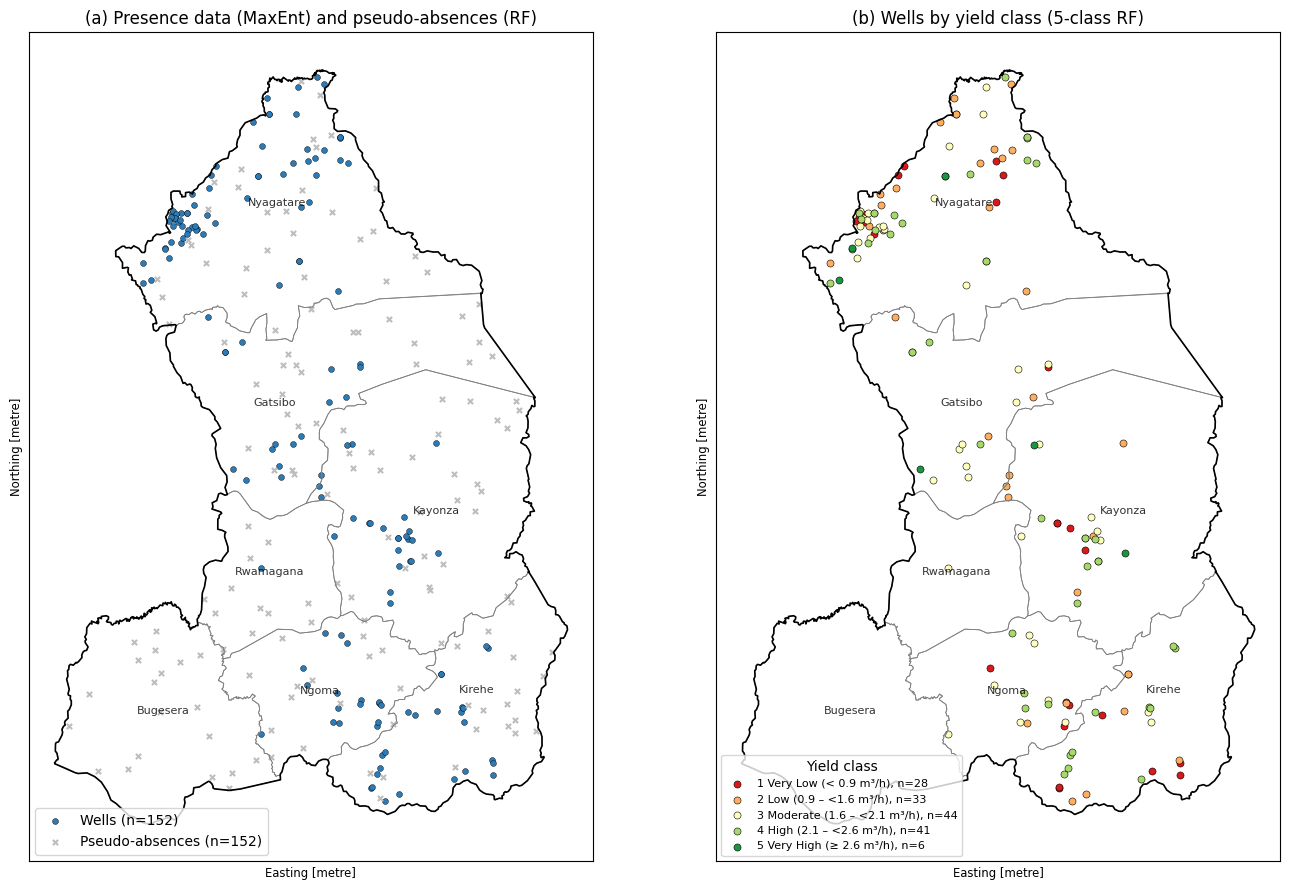

In [ ]:
def base_map(ax):
    eastern_dist_utm.boundary.plot(ax=ax, color="grey", lw=0.6)
    eastern_prov_utm.boundary.plot(ax=ax, color="black", lw=1.2)
    for _, r in dist_gdf.iterrows():
        p = r.geometry.representative_point(); ax.annotate(r.District, (p.x, p.y), ha="center", fontsize=8, alpha=.8)
    ax.set_xticks([]); ax.set_yticks([])

fig, ax = plt.subplots(1, 2, figsize=(14, 9))
base_map(ax[0]); data[data.Class == 1].plot(ax=ax[0], color="#2c7bb6", markersize=18, edgecolor="k", lw=.3,
                                           label=f"Wells (n={int(data.Class.sum())})")
data[data.Class == 0].plot(ax=ax[0], color="#bdbdbd", marker="x", markersize=14,
                           label=f"Pseudo-absences (n={int((data.Class==0).sum())})")
ax[0].legend(loc="lower left"); ax[0].set_title("(a) Presence data (MaxEnt) and pseudo-absences (RF)")
base_map(ax[1])
for k in range(1, 6):
    s = data[(data.Class == 1) & (data.Yield_Class == k)]
    s.plot(ax=ax[1], color=CLASS_COLORS[k-1], markersize=26, edgecolor="k", lw=.4,
           label=f"{k} {CLASS_NAMES[k-1]} ({thr.Yield_rule_m3h[k-1]} m³/h), n={len(s)}")
ax[1].legend(loc="lower left", fontsize=8, title="Yield class"); ax[1].set_title("(b) Wells by yield class (5-class RF)")
plt.tight_layout(); savefig("Fig03_wells_classes"); plt.show()

# Part B – Diagnostics
## 10. Collinearity (Spearman + VIF) and spatial structure of wells (R3-12, R2-Q3.8)

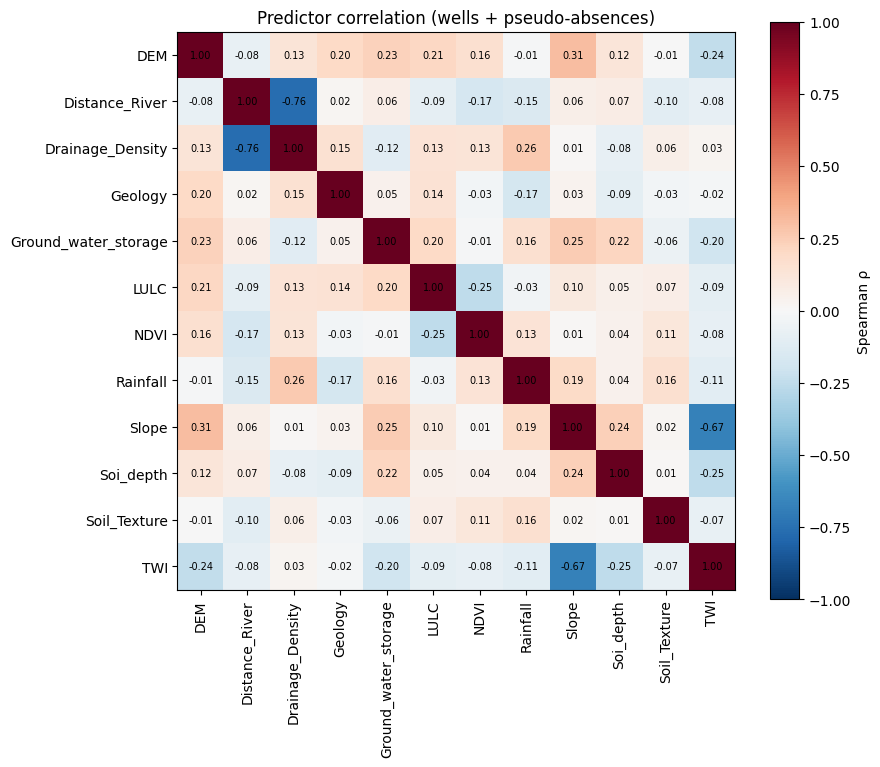

           Predictor  VIF Assessment
                 DEM 1.30 acceptable
      Distance_River 1.81 acceptable
    Drainage_Density 1.91 acceptable
Ground_water_storage 1.19 acceptable
                NDVI 1.11 acceptable
            Rainfall 1.18 acceptable
               Slope 2.43 acceptable
                 TWI 2.31 acceptable
|ρ| ≥ 0.7: [('Distance_River', 'Drainage_Density', np.float64(-0.76))]
                      Statistic     Value
                        n wells   152.000
            NN distance min (m)     5.000
         NN distance median (m)  1460.000
           NN distance mean (m)  2037.000
Wells with neighbour < 1 km (%)    40.100
 Clark–Evans R (<1 = clustered)     0.516
      Spatial CV block size (m) 15000.000


In [ ]:
corr = data[FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES, rotation=90)
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="Spearman ρ"); plt.title("Predictor correlation (wells + pseudo-absences)")
savefig("FigS_correlation"); plt.show()

Xv = data[CONTINUOUS].assign(const=1.0).values
vif = pd.DataFrame({"Predictor": CONTINUOUS,
                    "VIF": [variance_inflation_factor(Xv, i) for i in range(len(CONTINUOUS))]}).round(2)
vif["Assessment"] = np.where(vif.VIF > 10, "severe", np.where(vif.VIF > 5, "moderate", "acceptable"))
print(vif.to_string(index=False))
pairs = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(FEATURES) for b in FEATURES[i+1:] if abs(corr.loc[a, b]) >= 0.7]
print("|ρ| ≥ 0.7:", pairs or "none")
RESULTS["T_Collinearity_VIF"] = vif
RESULTS["T_Spearman_Matrix"] = corr.round(3).reset_index().rename(columns={"index": "Predictor"})

# nearest-neighbour distances between wells + Clark–Evans ratio
xy = data.loc[data.Class == 1, ["X", "Y"]].values
dnn = cKDTree(xy).query(xy, k=2)[0][:, 1]
area = prov_geom.area
R_ce = dnn.mean() / (0.5 / np.sqrt(len(xy) / area))
nn = pd.DataFrame({"Statistic": ["n wells", "NN distance min (m)", "NN distance median (m)", "NN distance mean (m)",
                                 "Wells with neighbour < 1 km (%)", "Clark–Evans R (<1 = clustered)", "Spatial CV block size (m)"],
                   "Value": [len(xy), dnn.min().round(0), np.median(dnn).round(0), dnn.mean().round(0),
                             round((dnn < 1000).mean() * 100, 1), round(R_ce, 3), BLOCK_SIZE]})
print(nn.to_string(index=False)); RESULTS["T_Well_Spatial_Structure"] = nn

# Part C – Random Forest groundwater-potential model
## 11. 70/30 split (stratified, fixed seed) + spatial blocks

In [ ]:
X, y = data[FEATURES], data["Class"].values
idx_tr, idx_te = train_test_split(data.index, test_size=TEST_SIZE, stratify=y, random_state=SEED)
data["Split"] = "Train"; data.loc[idx_te, "Split"] = "Test"
X_tr, X_te, y_tr, y_te = X.loc[idx_tr], X.loc[idx_te], y[idx_tr], y[idx_te]
blocks = (np.floor(data.X / BLOCK_SIZE).astype(int).astype(str) + "_" + np.floor(data.Y / BLOCK_SIZE).astype(int).astype(str)).values
split_tab = pd.crosstab(data.Class_Label, data.Split, margins=True)
print(split_tab); print(f"{len(np.unique(blocks))} spatial blocks of {BLOCK_SIZE/1000:.0f} km")
RESULTS["T_Train_Test_Counts"] = split_tab.reset_index()

Split          Test  Train  All
Class_Label                    
Non-potential    46    106  152
Potential        46    106  152
All              92    212  304
53 spatial blocks of 15 km


## 12. RF tuning (RandomizedSearchCV, 60 combinations, 5-fold stratified CV) – full configuration (R2-Q2.4)

In [ ]:
param_dist = {"n_estimators": [200, 300, 400, 500, 600, 800], "max_depth": [None, 5, 10, 20, 30],
              "min_samples_split": [2, 3, 5, 10], "min_samples_leaf": [1, 2, 3, 5],
              "max_features": ["sqrt", "log2", 0.5], "class_weight": [None, "balanced", "balanced_subsample"]}
search = RandomizedSearchCV(RandomForestClassifier(random_state=SEED, n_jobs=-1, bootstrap=True, oob_score=True),
                            param_dist, n_iter=N_SEARCH, scoring="roc_auc",
                            cv=StratifiedKFold(5, shuffle=True, random_state=SEED), random_state=SEED, n_jobs=-1)
search.fit(X_tr, y_tr)
rf = search.best_estimator_
rf_cfg = pd.DataFrame({"Setting": ["Software", "Algorithm", "Tuning", "Scoring", "Random seed", "Predictors"] +
                       [f"best {k}" for k in search.best_params_] + ["CV AUC (train, 5-fold)", "OOB accuracy"],
                       "Value": [f"scikit-learn {sklearn.__version__}", "RandomForestClassifier (bootstrap=True)",
                                 f"RandomizedSearchCV, {N_SEARCH} combinations", "ROC-AUC", SEED, ", ".join(FEATURES)] +
                                [str(v) for v in search.best_params_.values()] +
                                [round(search.best_score_, 4), round(rf.oob_score_, 4)]})
print(rf_cfg.to_string(index=False)); RESULTS["T_RF_Configuration"] = rf_cfg
RESULTS["T_RF_SearchSpace"] = pd.DataFrame([(k, str(v)) for k, v in param_dist.items()], columns=["Hyperparameter", "Search space"])

               Setting                                                                                                                           Value
              Software                                                                                                              scikit-learn 1.9.1
             Algorithm                                                                                         RandomForestClassifier (bootstrap=True)
                Tuning                                                                                             RandomizedSearchCV, 60 combinations
               Scoring                                                                                                                         ROC-AUC
           Random seed                                                                                                                              42
            Predictors DEM, Distance_River, Drainage_Density, Geology, Ground_water_storage, L

# Part D – MaxEnt (Python `elapid`, same presences & same test set)
Training = the 70 % training wells + 10,000 background points. Test = the same 30 % test wells and test pseudo-absences as RF, so both AUCs are computed on identical data (R3-4).

In [ ]:
cat_idx = [FEATURES.index(c) for c in CATEGORICAL]
ME_SETTINGS = dict(feature_types=["linear", "quadratic", "hinge", "product"], beta_multiplier=1.0,
                   transform="cloglog", clamp=True, tau=0.5, n_hinge_features=10, random_state=SEED)
def fit_maxent(pres_X):
    xm = pd.concat([pres_X[FEATURES], bg[FEATURES]], ignore_index=True)
    ym = np.r_[np.ones(len(pres_X)), np.zeros(len(bg))]
    m = elapid.MaxentModel(**ME_SETTINGS); m.fit(xm, ym, categorical=cat_idx or None); return m

me = fit_maxent(X_tr[y_tr == 1])
me_pred = lambda Xd: np.asarray(me.predict(Xd[FEATURES])).ravel()
auc_bg_test = roc_auc_score(np.r_[np.ones((y_te == 1).sum()), np.zeros(len(bg))],
                            np.r_[me_pred(X_te[y_te == 1]), me_pred(bg)])
me_cfg = pd.DataFrame({"Setting": ["Software", "Feature classes", "Regularisation multiplier", "Output", "Clamping",
                                   "Prevalence (tau)", "Background points", "Training presences", "Test presences",
                                   "Replicate type", "Test AUC (presence vs background)"],
                       "Value": [f"elapid {elapid.__version__} (Python MaxEnt)", "linear, quadratic, hinge, product", 1.0,
                                 "cloglog", "yes", 0.5, len(bg), int((y_tr == 1).sum()), int((y_te == 1).sum()),
                                 f"single 70/30 split (seed {SEED}) + {N_SPATIAL_FOLDS}-fold spatial block CV",
                                 round(auc_bg_test, 4)]})
print(me_cfg.to_string(index=False)); RESULTS["T_MaxEnt_Configuration"] = me_cfg

                          Setting                                                  Value
                         Software                           elapid 1.0.4 (Python MaxEnt)
                  Feature classes                      linear, quadratic, hinge, product
        Regularisation multiplier                                                    1.0
                           Output                                                cloglog
                         Clamping                                                    yes
                 Prevalence (tau)                                                    0.5
                Background points                                                  10000
               Training presences                                                    106
                   Test presences                                                     46
                   Replicate type single 70/30 split (seed 42) + 5-fold spatial block CV
Test AUC (presence vs

# Part E – Validation
## 13. Test-set metrics with bootstrap 95 % CI, paired ΔAUC, calibration (R2-Q3.4–3.6, Q3.9)

Model                            MaxEnt     RF
Metric                                        
AUC                               0.833  0.859
Accuracy                          0.772  0.750
Brier score                       0.203  0.152
Cohen kappa                       0.543  0.500
F1                                0.753  0.729
Precision                         0.821  0.795
Recall (sensitivity)              0.696  0.674
Specificity                       0.848  0.826
TSS                               0.543  0.500
Threshold (max TSS on training)   0.280  0.489
            Statistic   Value
   ΔAUC (RF − MaxEnt)  0.0260
           95% CI low -0.0284
          95% CI high  0.0848
two-sided bootstrap p  0.3420


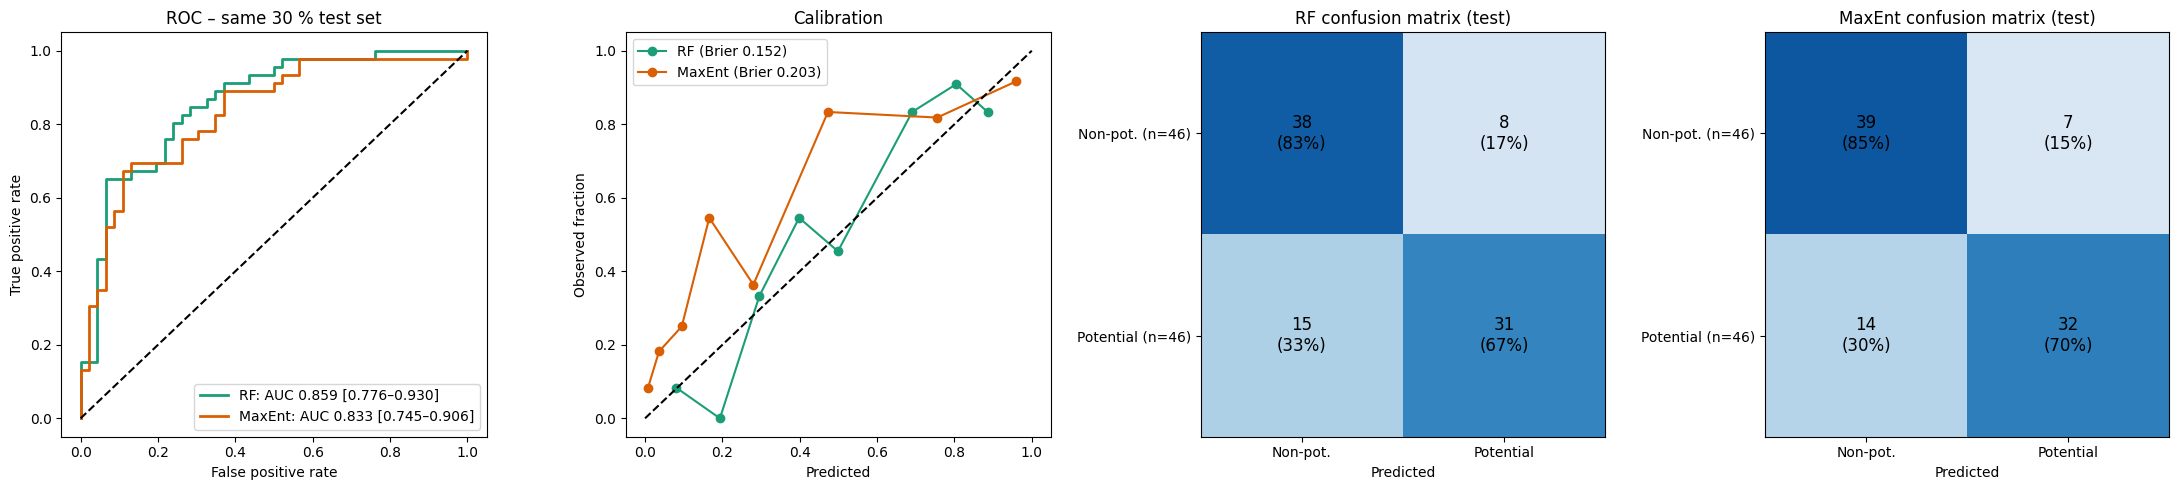

In [ ]:
p_rf_tr = rf.oob_decision_function_[:, 1]                 # out-of-bag → unbiased threshold
p_me_tr = me_pred(X_tr)
p_rf, p_me = rf.predict_proba(X_te)[:, 1], me_pred(X_te)

def best_thr(yy, pp):                                      # threshold maximising TSS (Youden)
    f, t, th = roc_curve(yy, pp); return th[np.argmax(t - f)]
THR = {"RF": best_thr(y_tr, p_rf_tr), "MaxEnt": best_thr(y_tr, p_me_tr)}

def mets(yy, pp, thr):
    pr = (pp >= thr).astype(int); sens = recall_score(yy, pr); spec = recall_score(yy, pr, pos_label=0)
    return {"AUC": roc_auc_score(yy, pp), "Accuracy": accuracy_score(yy, pr), "Precision": precision_score(yy, pr, zero_division=0),
            "Recall (sensitivity)": sens, "Specificity": spec, "F1": f1_score(yy, pr), "Cohen kappa": cohen_kappa_score(yy, pr),
            "TSS": sens + spec - 1, "Brier score": brier_score_loss(yy, np.clip(pp, 0, 1))}

def boot(yy, pp, thr, n=N_BOOT, seed=SEED):
    r = np.random.default_rng(seed); out = []
    for _ in range(n):
        i = r.integers(0, len(yy), len(yy))
        if len(np.unique(yy[i])) < 2: continue
        out.append(mets(yy[i], pp[i], thr))
    return pd.DataFrame(out)

rows = []
for name, pp in [("RF", p_rf), ("MaxEnt", p_me)]:
    pt, bs = mets(y_te, pp, THR[name]), boot(y_te, pp, THR[name])
    for k, v in pt.items():
        rows.append({"Model": name, "Metric": k, "Value": round(v, 3),
                     "CI95_low": round(bs[k].quantile(.025), 3), "CI95_high": round(bs[k].quantile(.975), 3)})
    rows.append({"Model": name, "Metric": "Threshold (max TSS on training)", "Value": round(THR[name], 3)})
test_metrics = pd.DataFrame(rows)
print(test_metrics.pivot(index="Metric", columns="Model", values="Value"))

# paired bootstrap of the AUC difference (same test points)
r = np.random.default_rng(SEED); d_auc = []
for _ in range(N_BOOT):
    i = r.integers(0, len(y_te), len(y_te))
    if len(np.unique(y_te[i])) < 2: continue
    d_auc.append(roc_auc_score(y_te[i], p_rf[i]) - roc_auc_score(y_te[i], p_me[i]))
d_auc = np.array(d_auc)
p_val = 2 * min((d_auc <= 0).mean(), (d_auc >= 0).mean())
cmp_tab = pd.DataFrame({"Statistic": ["ΔAUC (RF − MaxEnt)", "95% CI low", "95% CI high", "two-sided bootstrap p"],
                        "Value": [round(roc_auc_score(y_te, p_rf) - roc_auc_score(y_te, p_me), 4),
                                  round(np.quantile(d_auc, .025), 4), round(np.quantile(d_auc, .975), 4), round(p_val, 4)]})
print(cmp_tab.to_string(index=False))
RESULTS["T_Test_Metrics_CI"] = test_metrics; RESULTS["T_RF_vs_MaxEnt_DeltaAUC"] = cmp_tab

fig, ax = plt.subplots(1, 4, figsize=(22, 5))
for name, pp, c in [("RF", p_rf, "#1b9e77"), ("MaxEnt", p_me, "#d95f02")]:
    f, t, _ = roc_curve(y_te, pp)
    lo, hi = test_metrics.query("Model==@name and Metric=='AUC'")[["CI95_low", "CI95_high"]].values[0]
    ax[0].plot(f, t, c=c, lw=2, label=f"{name}: AUC {roc_auc_score(y_te, pp):.3f} [{lo:.3f}–{hi:.3f}]")
    fr, mp = calibration_curve(y_te, np.clip(pp, 0, 1), n_bins=8, strategy="quantile")
    ax[1].plot(mp, fr, "o-", c=c, label=f"{name} (Brier {brier_score_loss(y_te, np.clip(pp,0,1)):.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].legend(loc="lower right"); ax[0].set_title("ROC – same 30 % test set")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].legend(); ax[1].set_title("Calibration"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Observed fraction")
for k, (name, pp) in enumerate([("RF", p_rf), ("MaxEnt", p_me)]):
    cm = confusion_matrix(y_te, (pp >= THR[name]).astype(int)); a = ax[2 + k]
    a.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2): a.text(j, i, f"{cm[i,j]}\n({cm[i,j]/cm[i].sum():.0%})", ha="center", va="center", fontsize=12)
    a.set_xticks([0, 1]); a.set_xticklabels(["Non-pot.", "Potential"]); a.set_yticks([0, 1])
    a.set_yticklabels([f"Non-pot. (n={cm[0].sum()})", f"Potential (n={cm[1].sum()})"])
    a.set_xlabel("Predicted"); a.set_title(f"{name} confusion matrix (test)")
plt.tight_layout(); savefig("Fig05_ROC_calibration_confusion"); plt.show()

## 14. Spatial block cross-validation (R3-5, R2-Q3.2)

In [ ]:
gkf = GroupKFold(N_SPATIAL_FOLDS); cv_rows = []
oof_rf = np.full(len(data), np.nan); oof_me = np.full(len(data), np.nan)
for k, (tr, te) in enumerate(gkf.split(X, y, groups=blocks), 1):
    m = clone(rf).set_params(oob_score=False).fit(X.iloc[tr], y[tr])
    oof_rf[te] = m.predict_proba(X.iloc[te])[:, 1]
    mm = fit_maxent(X.iloc[tr][y[tr] == 1]); oof_me[te] = np.asarray(mm.predict(X.iloc[te][FEATURES])).ravel()
    if len(np.unique(y[te])) == 2:
        for name, pp in [("RF", oof_rf[te]), ("MaxEnt", oof_me[te])]:
            met = mets(y[te], pp, THR[name]); cv_rows.append({"Fold": k, "Model": name, "n_test": len(te), **met})
cvdf = pd.DataFrame(cv_rows)
cv_sum = cvdf.groupby("Model")[["AUC", "Accuracy", "Cohen kappa", "TSS", "F1"]].agg(["mean", "std"]).round(3)
print(cv_sum)
RESULTS["T_SpatialCV_Folds"] = cvdf.round(4)
RESULTS["T_SpatialCV_Summary"] = cv_sum.reset_index().set_axis(["Model"] + [f"{a}_{b}" for a, b in cv_sum.columns], axis=1)
data["OOF_Spatial_RF"], data["OOF_Spatial_MaxEnt"] = oof_rf, oof_me

          AUC        Accuracy        Cohen kappa           TSS            F1  \
         mean    std     mean    std        mean    std   mean    std   mean   
Model                                                                          
MaxEnt  0.824  0.069    0.750  0.048       0.489  0.102  0.485  0.104  0.715   
RF      0.865  0.094    0.776  0.073       0.536  0.148  0.524  0.149  0.759   

               
          std  
Model          
MaxEnt  0.064  
RF      0.110  


# Part F – Variable importance & response curves (Fig. 6, Figs. 8–10, R3-8, R3-12)

             Feature  RF_MDI  RF_Perm_AUCdrop  RF_Perm_SD  MaxEnt_Perm_AUCdrop  MaxEnt_Perm_SD  RF_MDI_Rank  RF_Perm_Rank  MaxEnt_Perm_Rank  Max_|rho|_with_other
                 TWI  0.1560           0.0637      0.0279               0.0458          0.0156            2             1                 2                  0.67
      Distance_River  0.1868           0.0569      0.0267               0.1218          0.0375            1             2                 1                  0.76
                 DEM  0.1126           0.0427      0.0121               0.0325          0.0130            3             3                 4                  0.31
               Slope  0.0976           0.0238      0.0099               0.0136          0.0149            5             4                 9                  0.67
                NDVI  0.0762           0.0158      0.0082               0.0299          0.0151            7             5                 6                  0.25
            Rainfall  0.0827

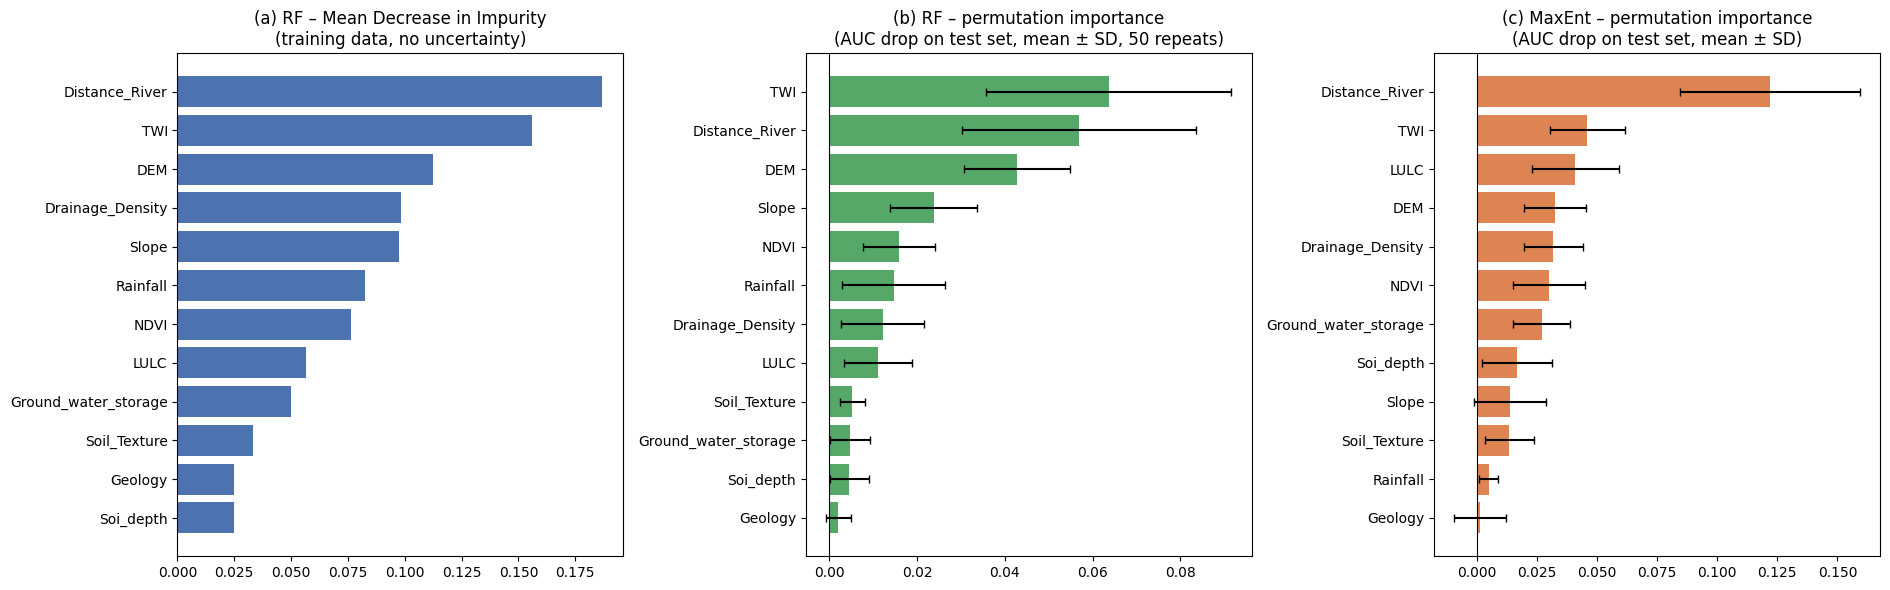

In [ ]:
def perm_importance(predict, Xd, yy, n_rep=50, seed=SEED):
    r = np.random.default_rng(seed); base = roc_auc_score(yy, predict(Xd)); out = []
    for f in FEATURES:
        drops = []
        for _ in range(n_rep):
            Xp = Xd.copy(); Xp[f] = r.permutation(Xp[f].values); drops.append(base - roc_auc_score(yy, predict(Xp)))
        out.append((f, np.mean(drops), np.std(drops)))
    return pd.DataFrame(out, columns=["Feature", "mean", "sd"])

pi_rf = perm_importance(lambda d: rf.predict_proba(d)[:, 1], X_te, y_te)
pi_me = perm_importance(me_pred, X_te, y_te)
imp = pd.DataFrame({"Feature": FEATURES, "RF_MDI": rf.feature_importances_})
imp = imp.merge(pi_rf.rename(columns={"mean": "RF_Perm_AUCdrop", "sd": "RF_Perm_SD"}), on="Feature")
imp = imp.merge(pi_me.rename(columns={"mean": "MaxEnt_Perm_AUCdrop", "sd": "MaxEnt_Perm_SD"}), on="Feature")
for c in ["RF_MDI", "RF_Perm_AUCdrop", "MaxEnt_Perm_AUCdrop"]:
    imp[c.replace("_AUCdrop", "") + "_Rank"] = imp[c].rank(ascending=False).astype(int)
imp["Max_|rho|_with_other"] = [round(float(corr.loc[f].drop(f).abs().max()), 2) for f in imp.Feature]
imp = imp.sort_values("RF_Perm_AUCdrop", ascending=False).round(4)
print(imp.to_string(index=False)); RESULTS["T_Variable_Importance"] = imp

o = imp.sort_values("RF_MDI")
fig, ax = plt.subplots(1, 3, figsize=(19, 6), sharey=False)
ax[0].barh(o.Feature, o.RF_MDI, color="#4c72b0"); ax[0].set_title("(a) RF – Mean Decrease in Impurity\n(training data, no uncertainty)")
o = imp.sort_values("RF_Perm_AUCdrop")
ax[1].barh(o.Feature, o.RF_Perm_AUCdrop, xerr=o.RF_Perm_SD, color="#55a868", capsize=3)
ax[1].set_title("(b) RF – permutation importance\n(AUC drop on test set, mean ± SD, 50 repeats)")
o = imp.sort_values("MaxEnt_Perm_AUCdrop")
ax[2].barh(o.Feature, o.MaxEnt_Perm_AUCdrop, xerr=o.MaxEnt_Perm_SD, color="#dd8452", capsize=3)
ax[2].set_title("(c) MaxEnt – permutation importance\n(AUC drop on test set, mean ± SD)")
for a in ax[1:]: a.axvline(0, c="k", lw=.8)
plt.tight_layout(); savefig("Fig06_variable_importance"); plt.show()

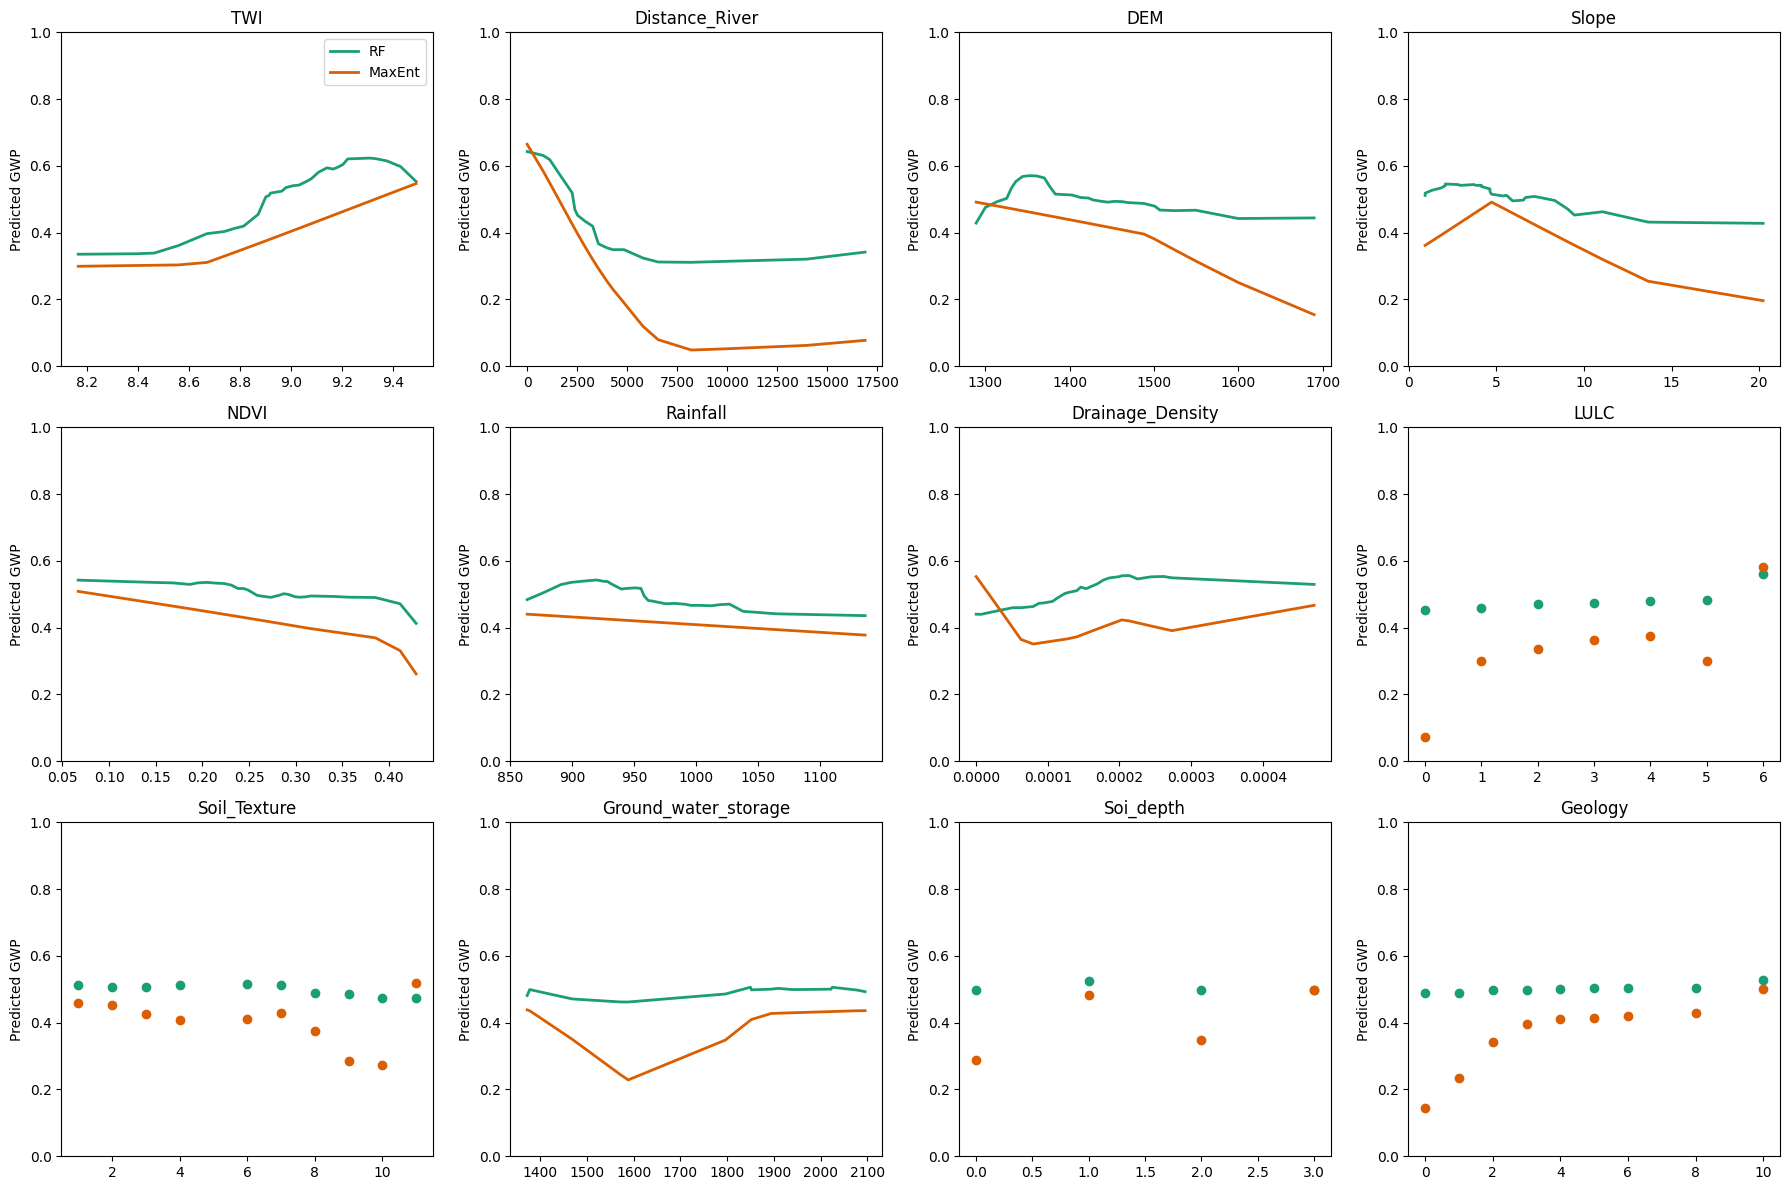

         Model  Test AUC  Spatial-CV AUC (pooled OOF)
   RF with GWS    0.8592                       0.8553
RF without GWS    0.8653                       0.8668


In [ ]:
# Response (partial-dependence) curves for both models on the same axes
def pdp(predict, f, Xref, n=30):
    Xs = Xref.sample(min(400, len(Xref)), random_state=SEED)
    grid = np.sort(Xref[f].unique()) if f in CATEGORICAL else np.unique(np.quantile(Xref[f], np.linspace(.02, .98, n)))
    vals = []
    for g in grid:
        Xg = Xs.copy(); Xg[f] = g; vals.append(np.mean(predict(Xg)))
    return grid, np.array(vals)

ncol = 4; nrow = math.ceil(len(FEATURES) / ncol)
fig, axs = plt.subplots(nrow, ncol, figsize=(18, 4 * nrow)); axs = axs.ravel()
for a, f in zip(axs, imp.Feature):
    for name, fn, c in [("RF", lambda d: rf.predict_proba(d)[:, 1], "#1b9e77"), ("MaxEnt", me_pred, "#d95f02")]:
        g, v = pdp(fn, f, X_tr)
        (a.plot(g, v, "o" if f in CATEGORICAL else "-", c=c, label=name, lw=2) if True else None)
    a.set_title(f); a.set_ylim(0, 1); a.set_ylabel("Predicted GWP")
axs[0].legend()
for a in axs[len(FEATURES):]: a.axis("off")
plt.tight_layout(); savefig("Fig10_response_curves"); plt.show()

# GWS circularity test (R3-8): refit without groundwater storage
if "Ground_water_storage" in FEATURES:
    F2 = [f for f in FEATURES if f != "Ground_water_storage"]
    rf2 = RandomForestClassifier(**{**rf.get_params(), "oob_score": False}).fit(X_tr[F2], y_tr)
    oof2 = np.full(len(data), np.nan)
    for tr, te in gkf.split(X, y, groups=blocks):
        oof2[te] = clone(rf2).fit(X.iloc[tr][F2], y[tr]).predict_proba(X.iloc[te][F2])[:, 1]
    gws_tab = pd.DataFrame({"Model": ["RF with GWS", "RF without GWS"],
        "Test AUC": [roc_auc_score(y_te, p_rf), roc_auc_score(y_te, rf2.predict_proba(X_te[F2])[:, 1])],
        "Spatial-CV AUC (pooled OOF)": [roc_auc_score(y, oof_rf), roc_auc_score(y, oof2)]}).round(4)
    print(gws_tab.to_string(index=False)); RESULTS["T_GWS_Circularity_Test"] = gws_tab

# Part G – 5-class yield RF (manuscript design, corrected protocol)
SMOTE is placed **inside** an `imblearn` pipeline, so synthetic samples are generated only from the training folds during tuning and only from the 70 % training set for the final model. The 30 % test set contains real wells only. An ablation (no SMOTE vs SMOTE) is run on the *same* test set (R2-Q2.3, Q3.3, R3-2, R3-3).

    Class  Total  Train (real)  Test (real)  Train after SMOTE
 Very Low     28            19            9                 31
      Low     33            23           10                 31
 Moderate     44            31           13                 31
     High     41            29           12                 31
Very High      6             4            2                 31 
SMOTE k_neighbors = 1
Model                      No SMOTE, class_weight=balanced  \
Metric                                                       
Accuracy                                             0.348   
Cohen kappa                                          0.143   
Macro AUC (OvR)                                      0.644   
Macro F1                                             0.284   
Quadratic weighted kappa                             0.164   
Weighted AUC (OvR)                                   0.633   
Within-one-class accuracy                            0.696   

Model                      No SMOTE, unw

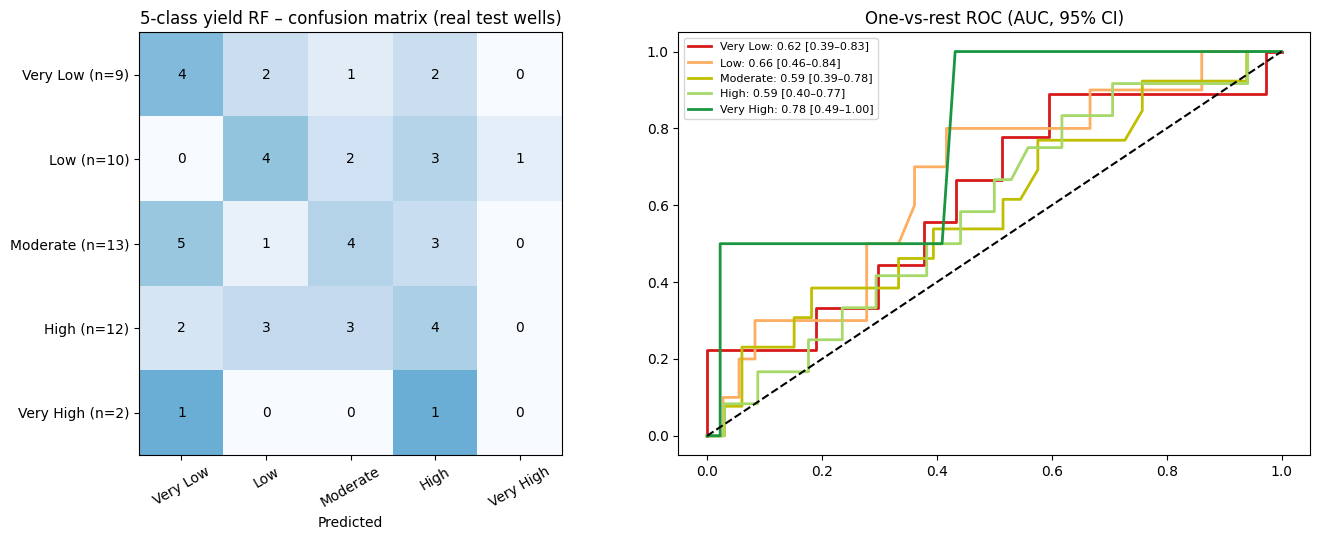

In [ ]:
W = data[data.Class == 1].reset_index(drop=True)
Xw, yw = W[FEATURES], W["Yield_Class"].values
iw_tr, iw_te = train_test_split(W.index, test_size=TEST_SIZE, stratify=yw, random_state=SEED)
cnt = pd.DataFrame({"Class": CLASS_NAMES,
                    "Total": [int((yw == k).sum()) for k in range(1, 6)],
                    "Train (real)": [int((yw[iw_tr] == k).sum()) for k in range(1, 6)],
                    "Test (real)": [int((yw[iw_te] == k).sum()) for k in range(1, 6)]})
k_smote = int(max(1, min(3, cnt["Train (real)"].min() * 2 // 3 - 1)))      # must fit inside CV folds
cnt["Train after SMOTE"] = int(cnt["Train (real)"].max())
print(cnt.to_string(index=False), f"\nSMOTE k_neighbors = {k_smote}")

yparams = {"rf__n_estimators": [300, 500, 800], "rf__max_depth": [None, 5, 10, 20],
           "rf__min_samples_leaf": [1, 2, 3, 5], "rf__max_features": ["sqrt", "log2", 0.5]}
def fit_yield(use_smote, cw):
    steps = ([("smote", SMOTE(k_neighbors=k_smote, random_state=SEED))] if use_smote else []) + \
            [("rf", RandomForestClassifier(random_state=SEED, n_jobs=-1, class_weight=cw))]
    s = RandomizedSearchCV(ImbPipeline(steps), yparams, n_iter=30, scoring="f1_macro",
                           cv=StratifiedKFold(3, shuffle=True, random_state=SEED), random_state=SEED, n_jobs=-1)
    return s.fit(Xw.loc[iw_tr], yw[iw_tr]).best_estimator_

def ymets(yy, pp):
    pr = pp.argmax(1) + 1
    return {"Accuracy": accuracy_score(yy, pr), "Within-one-class accuracy": np.mean(np.abs(pr - yy) <= 1),
            "Macro F1": f1_score(yy, pr, average="macro", zero_division=0),
            "Cohen kappa": cohen_kappa_score(yy, pr), "Quadratic weighted kappa": cohen_kappa_score(yy, pr, weights="quadratic"),
            "Macro AUC (OvR)": roc_auc_score(yy, pp, multi_class="ovr", average="macro", labels=[1, 2, 3, 4, 5]),
            "Weighted AUC (OvR)": roc_auc_score(yy, pp, multi_class="ovr", average="weighted", labels=[1, 2, 3, 4, 5])}

models_y = {"No SMOTE, unweighted": fit_yield(False, None), "No SMOTE, class_weight=balanced": fit_yield(False, "balanced"),
            "SMOTE (train only)": fit_yield(True, None)}
yte = yw[iw_te]; abl = []
for name, m in models_y.items():
    pp = m.predict_proba(Xw.loc[iw_te]); pt = ymets(yte, pp)
    r = np.random.default_rng(SEED); bs = []
    for _ in range(N_BOOT):
        i = r.integers(0, len(yte), len(yte))
        if len(np.unique(yte[i])) == 5: bs.append(ymets(yte[i], pp[i]))
    bs = pd.DataFrame(bs)
    for k, v in pt.items():
        abl.append({"Model": name, "Metric": k, "Value": round(v, 3),
                    "CI95_low": round(bs[k].quantile(.025), 3), "CI95_high": round(bs[k].quantile(.975), 3)})
abl = pd.DataFrame(abl)
print(abl.pivot(index="Metric", columns="Model", values="Value"))
RESULTS["T_Yield_Class_Counts"] = cnt; RESULTS["T_Yield_RF_Ablation_CI"] = abl

best_y = "SMOTE (train only)"; ym = models_y[best_y]; ypp = ym.predict_proba(Xw.loc[iw_te]); ypr = ypp.argmax(1) + 1
rep = pd.DataFrame(classification_report(yte, ypr, labels=[1, 2, 3, 4, 5], target_names=CLASS_NAMES,
                                         output_dict=True, zero_division=0)).T.round(3)
aucs = []
for k in range(1, 6):
    yy = (yte == k).astype(int); r = np.random.default_rng(SEED); bs = []
    for _ in range(N_BOOT):
        i = r.integers(0, len(yy), len(yy))
        if 0 < yy[i].sum() < len(i): bs.append(roc_auc_score(yy[i], ypp[i, k-1]))
    aucs.append((roc_auc_score(yy, ypp[:, k-1]), np.quantile(bs, .025), np.quantile(bs, .975)))
rep.loc[CLASS_NAMES, "AUC"] = [round(a[0], 3) for a in aucs]
rep.loc[CLASS_NAMES, "AUC_CI95"] = [f"{a[1]:.2f}–{a[2]:.2f}" for a in aucs]
print(rep); RESULTS["T_Yield_RF_Report"] = rep.reset_index().rename(columns={"index": "Class"})

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
cm = confusion_matrix(yte, ypr, labels=[1, 2, 3, 4, 5])
ax[0].imshow(cm / np.maximum(cm.sum(1, keepdims=True), 1), cmap="Blues", vmin=0, vmax=1)
for i in range(5):
    for j in range(5): ax[0].text(j, i, cm[i, j], ha="center", va="center")
ax[0].set_xticks(range(5)); ax[0].set_xticklabels(CLASS_NAMES, rotation=30)
ax[0].set_yticks(range(5)); ax[0].set_yticklabels([f"{c} (n={cm[i].sum()})" for i, c in enumerate(CLASS_NAMES)])
ax[0].set_xlabel("Predicted"); ax[0].set_title("5-class yield RF – confusion matrix (real test wells)")
for k in range(5):
    f, t, _ = roc_curve((yte == k+1).astype(int), ypp[:, k])
    ax[1].plot(f, t, c=CLASS_COLORS[k] if k != 2 else "#bfbf00", lw=2, label=f"{CLASS_NAMES[k]}: {aucs[k][0]:.2f} [{aucs[k][1]:.2f}–{aucs[k][2]:.2f}]")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].legend(fontsize=8); ax[1].set_title("One-vs-rest ROC (AUC, 95% CI)")
plt.tight_layout(); savefig("FigS_yield_RF"); plt.show()

# Part H – Current GWPZ maps
## 15. Prediction grid (all layers resampled directly to one grid – no IDW)

In [ ]:
minx, miny, maxx, maxy = prov_geom.bounds
W_, H_ = int(math.ceil((maxx - minx) / PRED_RES)), int(math.ceil((maxy - miny) / PRED_RES))
GT = from_origin(minx, maxy, PRED_RES, PRED_RES)
MASK = rfeatures.geometry_mask([prov_geom], (H_, W_), GT, invert=True)
DIST_ID = rfeatures.rasterize([(g, i + 1) for i, g in enumerate(dist_gdf.geometry)], (H_, W_), transform=GT, fill=0)
PIX_KM2 = PRED_RES ** 2 / 1e6

def to_grid(path, categorical=False):
    out = np.full((H_, W_), np.nan, np.float32)
    with rasterio.open(path) as src:
        reproject(rasterio.band(src, 1), out, src_nodata=src.nodata, dst_nodata=np.nan,
                  dst_transform=GT, dst_crs=DST_CRS,
                  resampling=Resampling.nearest if categorical else Resampling.bilinear)
    return out

STACK = {f: to_grid(p, f in CATEGORICAL) for f, p in USER_RASTERS.items()}
VALID = MASK & np.all([np.isfinite(STACK[f]) for f in FEATURES], axis=0)
print(f"Grid {W_}×{H_} at {PRED_RES} m; valid pixels {VALID.sum():,} ({VALID.sum()*PIX_KM2:,.0f} km²)")

def predict_grid(stack, model_fn, chunk=250000):
    Xg = pd.DataFrame({f: stack[f][VALID] for f in FEATURES})
    p = np.concatenate([model_fn(Xg.iloc[i:i + chunk]) for i in range(0, len(Xg), chunk)])
    out = np.full((H_, W_), np.nan, np.float32); out[VALID] = p; return out

MODELS = {"RF": lambda d: rf.predict_proba(d[FEATURES])[:, 1], "MaxEnt": me_pred}
PROB = {(m, "Current", "1991-2020"): predict_grid(STACK, fn) for m, fn in MODELS.items()}
print("✅ current maps predicted")

Grid 1048×1539 at 100 m; valid pixels 949,386 (9,494 km²)
✅ current maps predicted


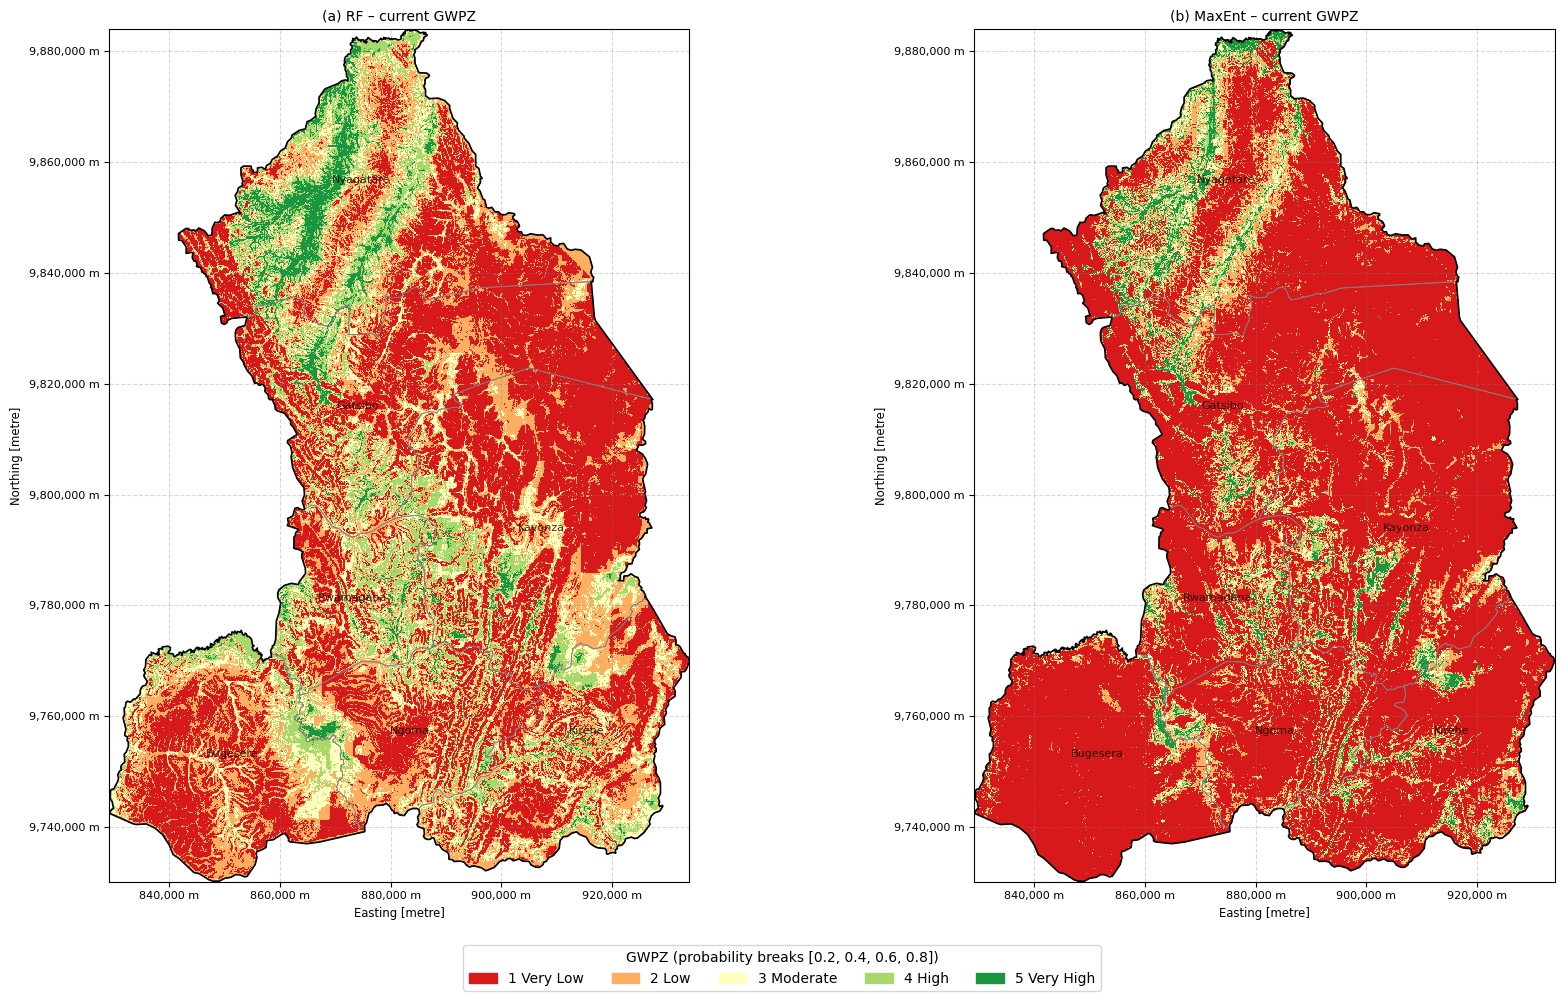

Class_Name        Very Low    Low  Moderate   High  Very High
Model  District                                              
MaxEnt Bugesera     1162.0   82.0      26.0   12.0       12.0
       Gatsibo      1250.0  178.0      69.0   43.0       47.0
       Kayonza      1502.0  232.0     101.0   55.0       49.0
       Kirehe        904.0  144.0      62.0   37.0       36.0
       Ngoma         640.0  124.0      54.0   31.0       21.0
       Nyagatare    1069.0  353.0     209.0  143.0      162.0
       Rwamagana     445.0  108.0      62.0   38.0       30.0
RF     Bugesera      548.0  438.0     205.0  100.0        3.0
       Gatsibo       848.0  376.0     185.0  134.0       44.0
       Kayonza      1031.0  460.0     250.0  159.0       38.0
       Kirehe        437.0  405.0     225.0  102.0       15.0
       Ngoma         360.0  286.0     129.0   72.0       23.0
       Nyagatare     558.0  500.0     321.0  320.0      236.0
       Rwamagana     206.0  171.0     140.0  137.0       28.0


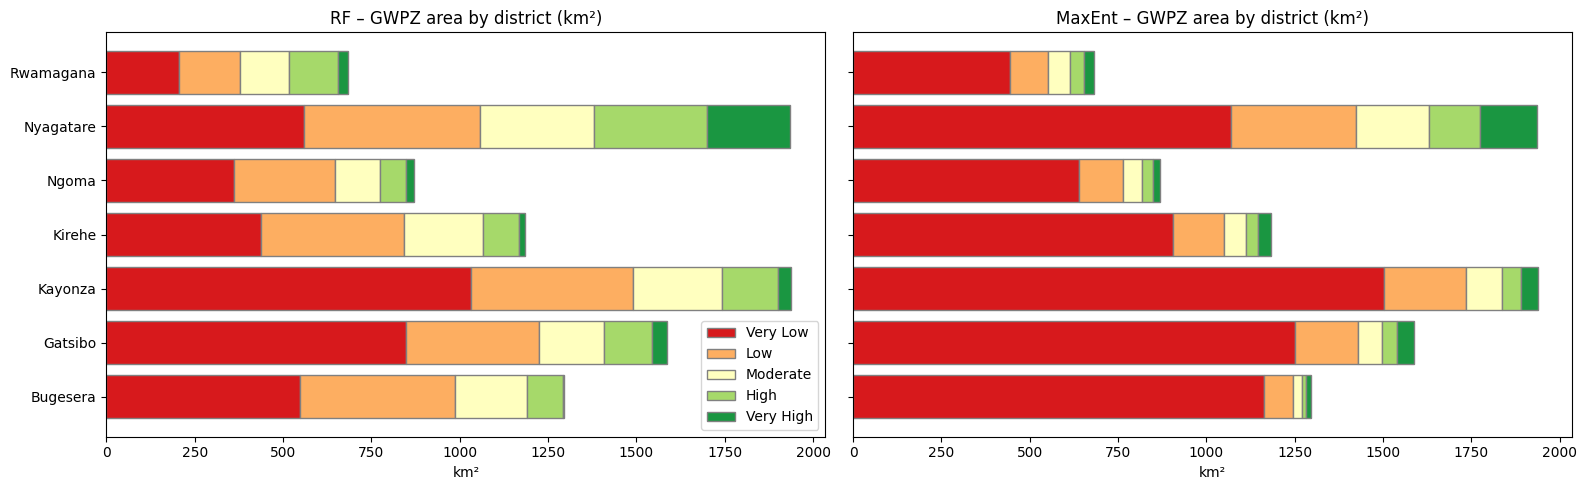

In [ ]:
CMAP, NORM = ListedColormap(CLASS_COLORS), BoundaryNorm(np.arange(.5, 6.5), 5)
EXTENT = (minx, minx + W_ * PRED_RES, maxy - H_ * PRED_RES, maxy)
LEG = [Patch(color=c, label=f"{k+1} {n}") for k, (n, c) in enumerate(zip(CLASS_NAMES, CLASS_COLORS))]

def base_map_with_coords(ax):
    eastern_dist_utm.boundary.plot(ax=ax, color="grey", lw=0.6)
    eastern_prov_utm.boundary.plot(ax=ax, color="black", lw=1.2)
    for _, r in dist_gdf.iterrows():
        p = r.geometry.representative_point()
        ax.annotate(r.District, (p.x, p.y), ha="center", fontsize=8, alpha=.8)
    # Configure grid coordinate numbers for Easting and Northing
    ax.tick_params(axis='both', which='major', labelsize=8)
    ax.grid(True, color='gray', linestyle='--', alpha=0.3)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{x:,.0f} m"))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, p: f"{y:,.0f} m"))

def show_classes(ax, prob, title):
    ax.imshow(np.where(VALID, classify(np.nan_to_num(prob)), np.nan), cmap=CMAP, norm=NORM, extent=EXTENT, interpolation="nearest")
    base_map_with_coords(ax)
    ax.set_title(title, fontsize=10)

def area_table(prob, model, scen, period):
    cls = classify(np.nan_to_num(prob)); rows = []
    for i, dn in enumerate(DISTRICTS, 1):
        m = VALID & (DIST_ID == i); tot = m.sum() * PIX_KM2
        for k in range(1, 6):
            a = (m & (cls == k)).sum() * PIX_KM2
            rows.append({"Model": model, "Scenario": scen, "Period": period, "District": dn, "Class": k,
                         "Class_Name": CLASS_NAMES[k-1], "Area_km2": round(a, 2), "Percent_of_district": round(100 * a / tot, 2)})
    return pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize=(18, 10))
for a, m in zip(ax, MODELS):
    show_classes(a, PROB[(m, "Current", "1991-2020")], f"({'ab'[list(MODELS).index(m)]}) {m} – current GWPZ")
fig.legend(handles=LEG, loc="lower center", ncol=5, title=f"GWPZ (probability breaks {PROB_BREAKS})")
plt.tight_layout(rect=(0, .06, 1, 1)); savefig("Fig11_12_current_GWPZ_RF_MaxEnt"); plt.show()

cur_area = pd.concat([area_table(PROB[(m, "Current", "1991-2020")], m, "Current", "1991-2020") for m in MODELS])
piv = cur_area.pivot_table(index=["Model", "District"], columns="Class_Name", values="Area_km2")[CLASS_NAMES]
print(piv.round(0)); RESULTS["T_Current_Area_by_District"] = cur_area

fig, ax = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for a, m in zip(ax, MODELS):
    pv = piv.loc[m]; left = np.zeros(len(pv))
    for k, cn in enumerate(CLASS_NAMES):
        a.barh(pv.index, pv[cn], left=left, color=CLASS_COLORS[k], edgecolor="grey", label=cn); left += pv[cn].values
    a.set_title(f"{m} – GWPZ area by district (km²)"); a.set_xlabel("km²")
ax[0].legend(); plt.tight_layout(); savefig("Fig12b_area_by_district"); plt.show()

In [ ]:
# Yield check of mapped zones with OUT-OF-FOLD (spatial CV) probabilities of the wells – independent of training
Wv = data[data.Class == 1].copy()
yt = []
for m, col in [("RF", "OOF_Spatial_RF"), ("MaxEnt", "OOF_Spatial_MaxEnt")]:
    Wv["Zone"] = classify(Wv[col].values)
    rho, p = stats.spearmanr(Wv[col], Wv["yield"])
    groups = [g["yield"].values for _, g in Wv.groupby("Zone") if len(g) > 1]
    kw = stats.kruskal(*groups) if len(groups) > 1 else (np.nan, np.nan)
    for z, g in Wv.groupby("Zone"):
        yt.append({"Model": m, "Mapped zone": CLASS_NAMES[z-1], "n wells": len(g),
                   "Median yield (m3/h)": round(g["yield"].median(), 2), "Mean yield": round(g["yield"].mean(), 2),
                   "Spearman rho (prob vs yield)": round(rho, 3), "Spearman p": round(p, 4),
                   "Kruskal-Wallis p": round(kw[1], 4)})
yt = pd.DataFrame(yt); print(yt.to_string(index=False)); RESULTS["T_Yield_by_Mapped_Zone"] = yt

 Model Mapped zone  n wells  Median yield (m3/h)  Mean yield  Spearman rho (prob vs yield)  Spearman p  Kruskal-Wallis p
    RF    Very Low        6                 1.75        1.70                         0.132      0.1058            0.2882
    RF         Low       17                 1.20        1.47                         0.132      0.1058            0.2882
    RF    Moderate       37                 1.50        1.55                         0.132      0.1058            0.2882
    RF        High       56                 2.00        1.78                         0.132      0.1058            0.2882
    RF   Very High       36                 2.00        1.83                         0.132      0.1058            0.2882
MaxEnt    Very Low       42                 1.50        1.54                         0.113      0.1651            0.5435
MaxEnt         Low       30                 2.00        1.74                         0.113      0.1651            0.5435
MaxEnt    Moderate       24     

# Part I – RF vs MaxEnt agreement (R2-Q4.2, R3-11)

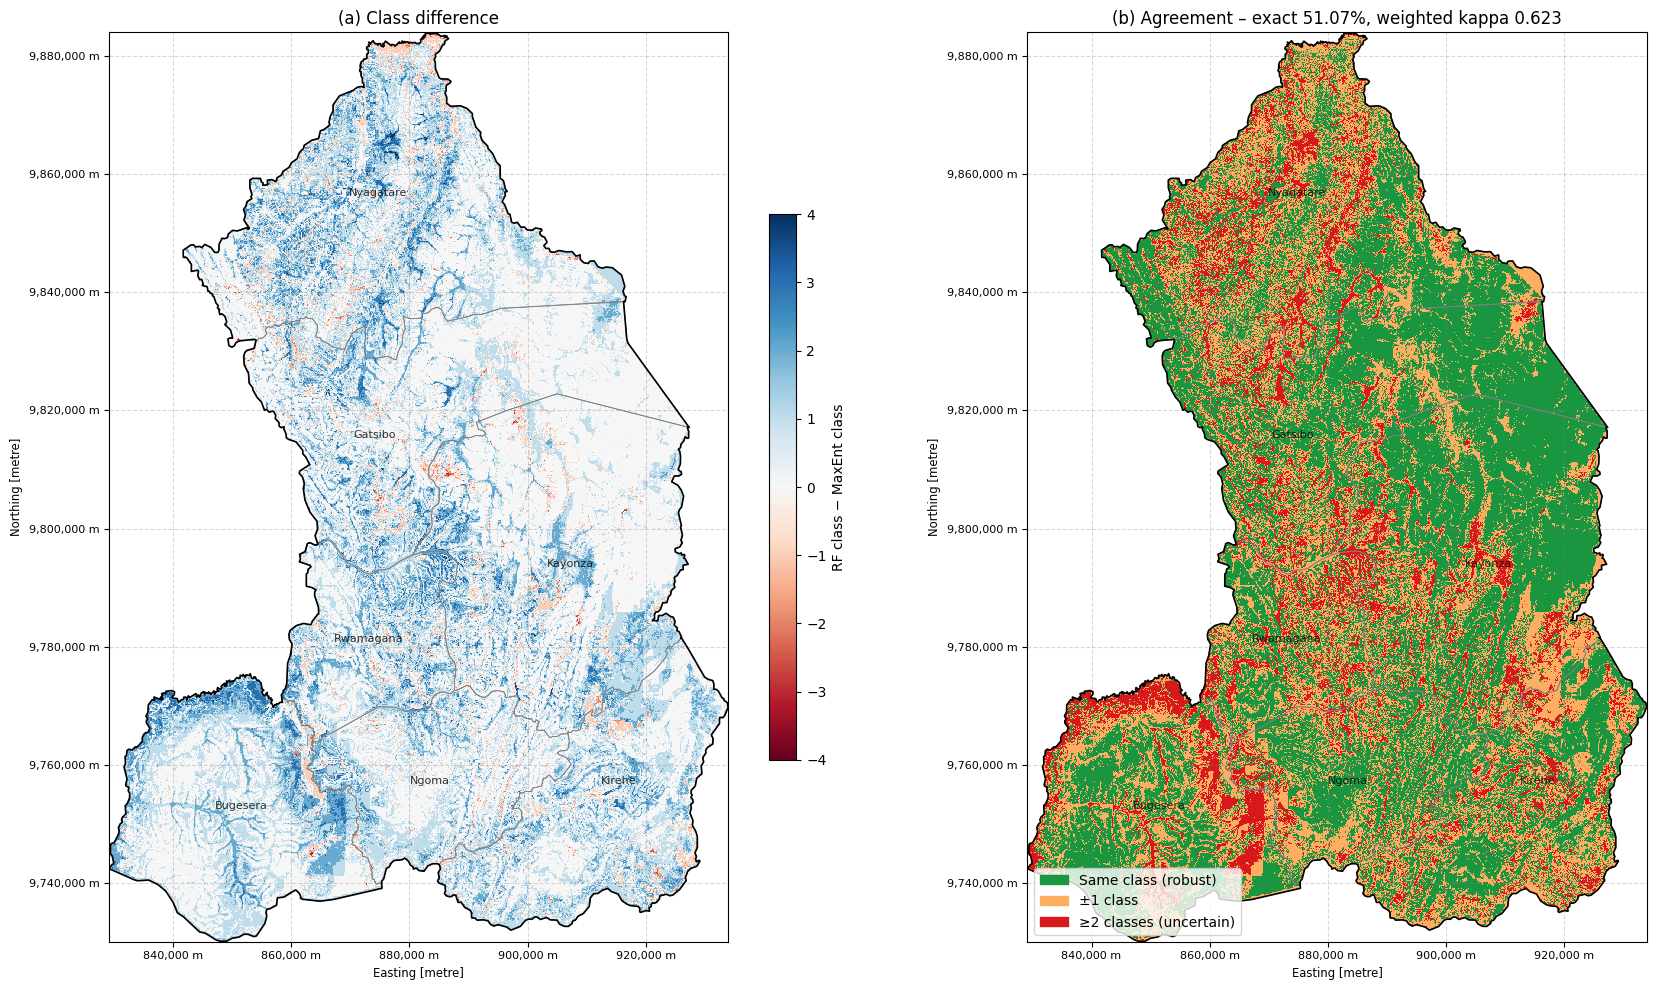

 District  Same class %  ±1 class %  ≥2 classes %
 Bugesera          45.1        36.4          18.5
  Gatsibo          60.7        28.8          10.6
  Kayonza          60.6        28.4          11.0
   Kirehe          45.4        41.5          13.1
    Ngoma          52.7        36.8          10.5
Nyagatare          44.0        38.8          17.3
Rwamagana          41.2        37.7          21.1


In [ ]:
def agreement(p1, p2):
    c1, c2 = classify(p1[VALID]), classify(p2[VALID])
    s = np.random.default_rng(SEED).choice(len(c1), min(200000, len(c1)), replace=False)
    return {"Exact agreement %": round(100 * np.mean(c1 == c2), 2),
            "Within ±1 class %": round(100 * np.mean(np.abs(c1 - c2) <= 1), 2),
            "Cohen kappa": round(cohen_kappa_score(c1[s], c2[s]), 3),
            "Quadratic weighted kappa": round(cohen_kappa_score(c1[s], c2[s], weights="quadratic"), 3),
            "Pearson r (probabilities)": round(np.corrcoef(p1[VALID], p2[VALID])[0, 1], 3)}

pr, pm = PROB[("RF", "Current", "1991-2020")], PROB[("MaxEnt", "Current", "1991-2020")]
agr_rows = [{"Scenario": "Current", "Period": "1991-2020", **agreement(pr, pm)}]
diff = np.where(VALID, classify(np.nan_to_num(pr)) - classify(np.nan_to_num(pm)), np.nan)
agree_cat = np.where(np.abs(diff) == 0, 1, np.where(np.abs(diff) == 1, 2, 3)).astype(float); agree_cat[~VALID] = np.nan

fig, ax = plt.subplots(1, 2, figsize=(18, 10))
im = ax[0].imshow(diff, cmap="RdBu", vmin=-4, vmax=4, extent=EXTENT, interpolation="nearest")
base_map_with_coords(ax[0])
plt.colorbar(im, ax=ax[0], shrink=.6, label="RF class − MaxEnt class")
ax[0].set_title("(a) Class difference")

ax[1].imshow(agree_cat, cmap=ListedColormap(["#1a9641", "#fdae61", "#d7191c"]), vmin=.5, vmax=3.5, extent=EXTENT, interpolation="nearest")
base_map_with_coords(ax[1])
ax[1].legend(handles=[Patch(color="#1a9641", label="Same class (robust)"), Patch(color="#fdae61", label="±1 class"),
                      Patch(color="#d7191c", label="≥2 classes (uncertain)")], loc="lower left")
ax[1].set_title(f"(b) Agreement – exact {agr_rows[0]['Exact agreement %']}%, weighted kappa {agr_rows[0]['Quadratic weighted kappa']}")
plt.tight_layout()
savefig("Fig_agreement_current")
plt.show()

ag_d = []
for i, dn in enumerate(DISTRICTS, 1):
    m = VALID & (DIST_ID == i)
    ag_d.append({"District": dn, "Same class %": round(100 * np.mean(agree_cat[m] == 1), 1),
                 "±1 class %": round(100 * np.mean(agree_cat[m] == 2), 1), "≥2 classes %": round(100 * np.mean(agree_cat[m] == 3), 1)})
ag_d = pd.DataFrame(ag_d); print(ag_d.to_string(index=False)); RESULTS["T_Agreement_by_District_Current"] = ag_d

# Part J – CMIP6 future scenarios
Only **Rainfall** changes; all other predictors are held at present conditions (R2-Q2.8, R3-6). Future rainfall rasters are resampled directly (bilinear) to the model grid – the point-conversion + IDW step of the original workflow is removed (R3-9). If `CLIMATE_BASELINE` exists, a multiplicative delta-change is applied so that CHIRPS and CMIP6 biases do not appear as 'climate change'.

Method: direct CMIP6 values (⚠️ bias not removed)
                    Baseline_mm    Future_mm   Change_%
Scenario Period                                        
SSP1-2.6 2040-2059   975.799988  1222.000000  25.000000
         2080-2099   975.799988  1251.199951  28.000000
SSP2-4.5 2040-2059   975.799988   956.900024  -2.300000
         2080-2099   975.799988   962.000000  -1.800000
SSP5-8.5 2040-2059   975.799988  1290.000000  31.900000
         2080-2099   975.799988  1473.099976  50.700001
Scenario    Period Train rainfall range  % pixels below  % pixels above
SSP1-2.6 2040-2059             851–1539             0.0             0.0
SSP1-2.6 2080-2099             851–1539             0.0             0.0
SSP2-4.5 2040-2059             851–1539             2.6             0.0
SSP2-4.5 2080-2099             851–1539             2.4             0.0
SSP5-8.5 2040-2059             851–1539             0.0             1.2
SSP5-8.5 2080-2099             851–1539             0.0            22.

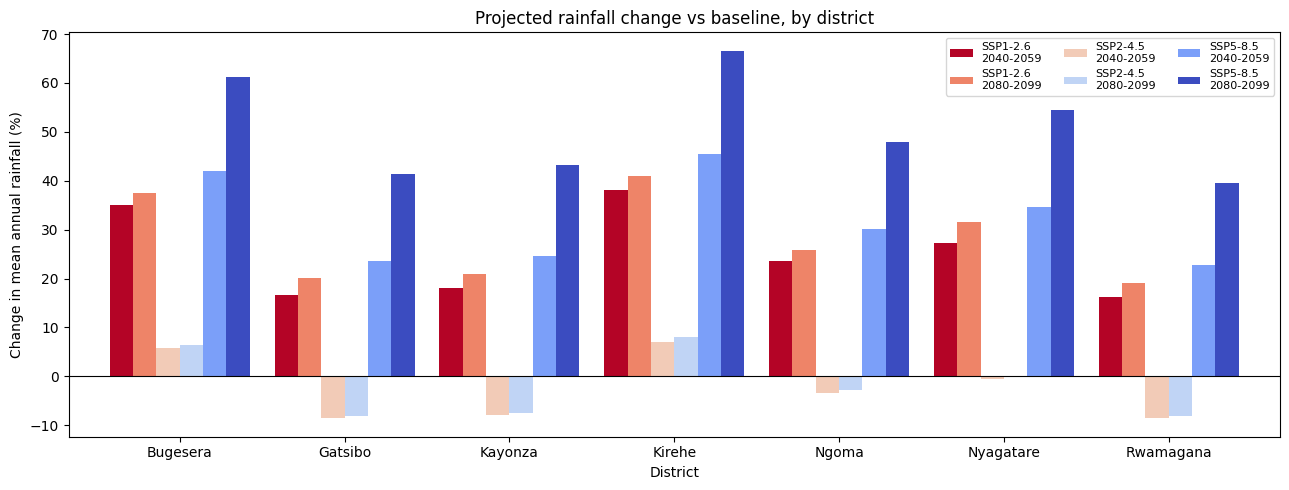

In [ ]:
rain0 = STACK["Rainfall"]
use_delta = os.path.exists(CLIMATE_BASELINE)
base_cm = to_grid(CLIMATE_BASELINE) if use_delta else None
FUT_RAIN, rain_rows = {}, []
avail = {k: p for k, p in FUTURE_RAINFALL.items() if os.path.exists(p)}
if len(avail) < len(FUTURE_RAINFALL):
    print("⚠️ missing future rasters:", [p for p in FUTURE_RAINFALL.values() if not os.path.exists(p)])
for (sc, per), p in avail.items():
    fut = to_grid(p)
    r = rain0 * fut / np.where(base_cm > 0, base_cm, np.nan) if use_delta else fut
    FUT_RAIN[(sc, per)] = r
    for i, dn in enumerate(DISTRICTS, 1):
        m = VALID & (DIST_ID == i)
        rain_rows.append({"Scenario": sc, "Period": per, "District": dn,
                          "Baseline_mm": round(np.nanmean(rain0[m]), 1), "Future_mm": round(np.nanmean(r[m]), 1),
                          "Change_mm": round(np.nanmean(r[m] - rain0[m]), 1),
                          "Change_%": round(100 * np.nanmean(r[m] - rain0[m]) / np.nanmean(rain0[m]), 1)})

rain_tab = pd.DataFrame(rain_rows)
print("Method:", "delta-change (CHIRPS × CMIP6 future / CMIP6 baseline)" if use_delta else "direct CMIP6 values (⚠️ bias not removed)")

if not rain_tab.empty:
    print(rain_tab.groupby(["Scenario", "Period"])[["Baseline_mm", "Future_mm", "Change_%"]].mean().round(1))
    RESULTS["T_Future_Rainfall_by_District"] = rain_tab

    # extrapolation check: share of pixels outside the training rainfall range
    lo, hi = X_tr["Rainfall"].min(), X_tr["Rainfall"].max(); ext = []
    for k, r in FUT_RAIN.items():
        v = r[VALID]; ext.append({"Scenario": k[0], "Period": k[1], "Train rainfall range": f"{lo:.0f}–{hi:.0f}",
                                  "% pixels below": round(100 * np.mean(v < lo), 1), "% pixels above": round(100 * np.mean(v > hi), 1)})
    ext = pd.DataFrame(ext); print(ext.to_string(index=False)); RESULTS["T_Future_Extrapolation_Check"] = ext

    # Figure: predictor change (R2-Q4 'changes in predictors')
    fig, ax = plt.subplots(figsize=(13, 5))
    pv = rain_tab.assign(S=rain_tab.Scenario + "\n" + rain_tab.Period).pivot(index="District", columns="S", values="Change_%")
    pv.plot.bar(ax=ax, width=.85, colormap="coolwarm_r"); ax.axhline(0, c="k", lw=.8)
    ax.set_ylabel("Change in mean annual rainfall (%)"); ax.set_title("Projected rainfall change vs baseline, by district")
    ax.legend(ncol=3, fontsize=8); plt.xticks(rotation=0); plt.tight_layout(); savefig("Fig_rainfall_change"); plt.show()
else:
    print("ℹ️ No future scenarios processed because no CMIP6 rasters were found.")
    RESULTS["T_Future_Rainfall_by_District"] = pd.DataFrame()
    RESULTS["T_Future_Extrapolation_Check"] = pd.DataFrame()

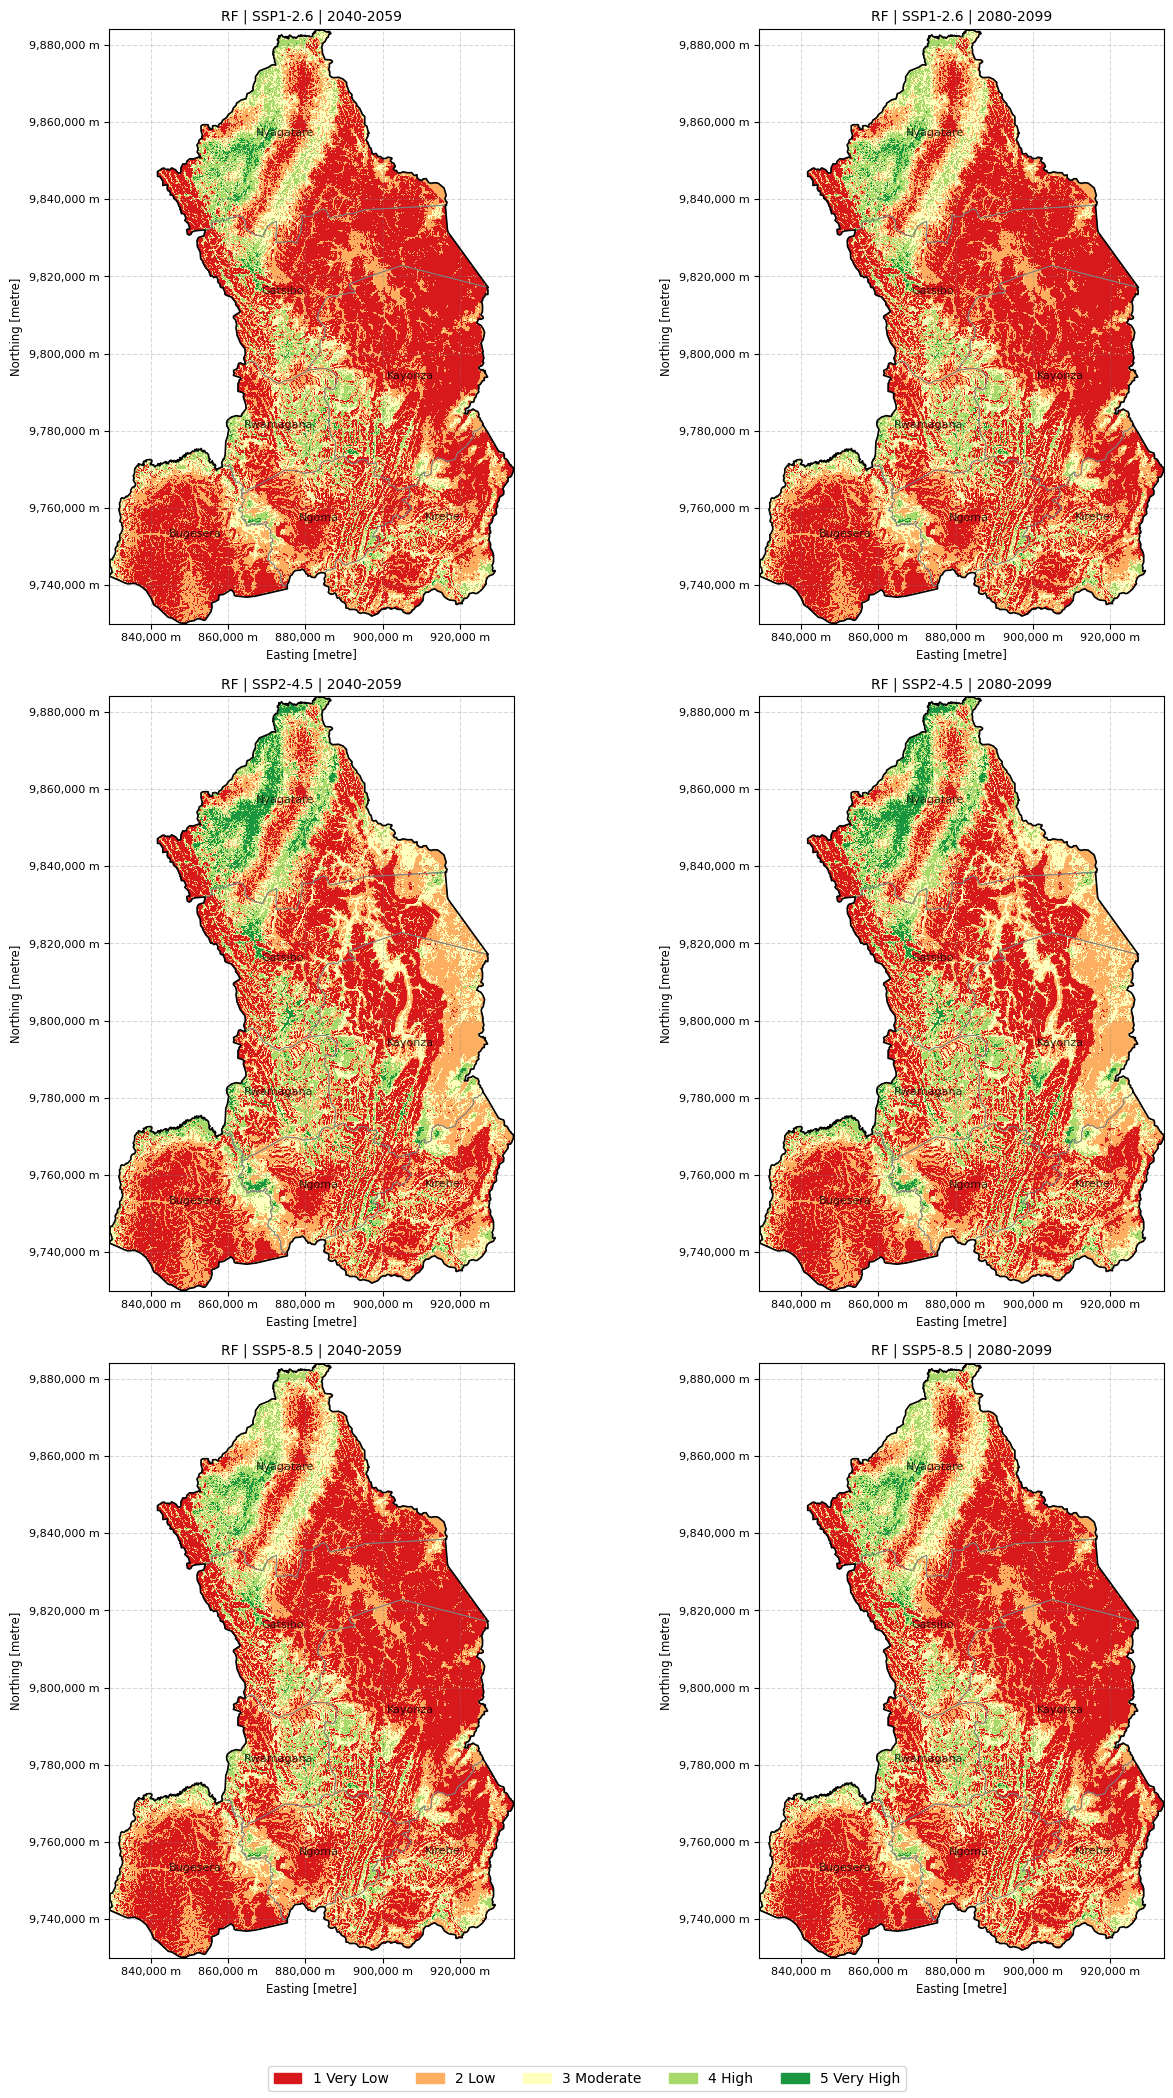

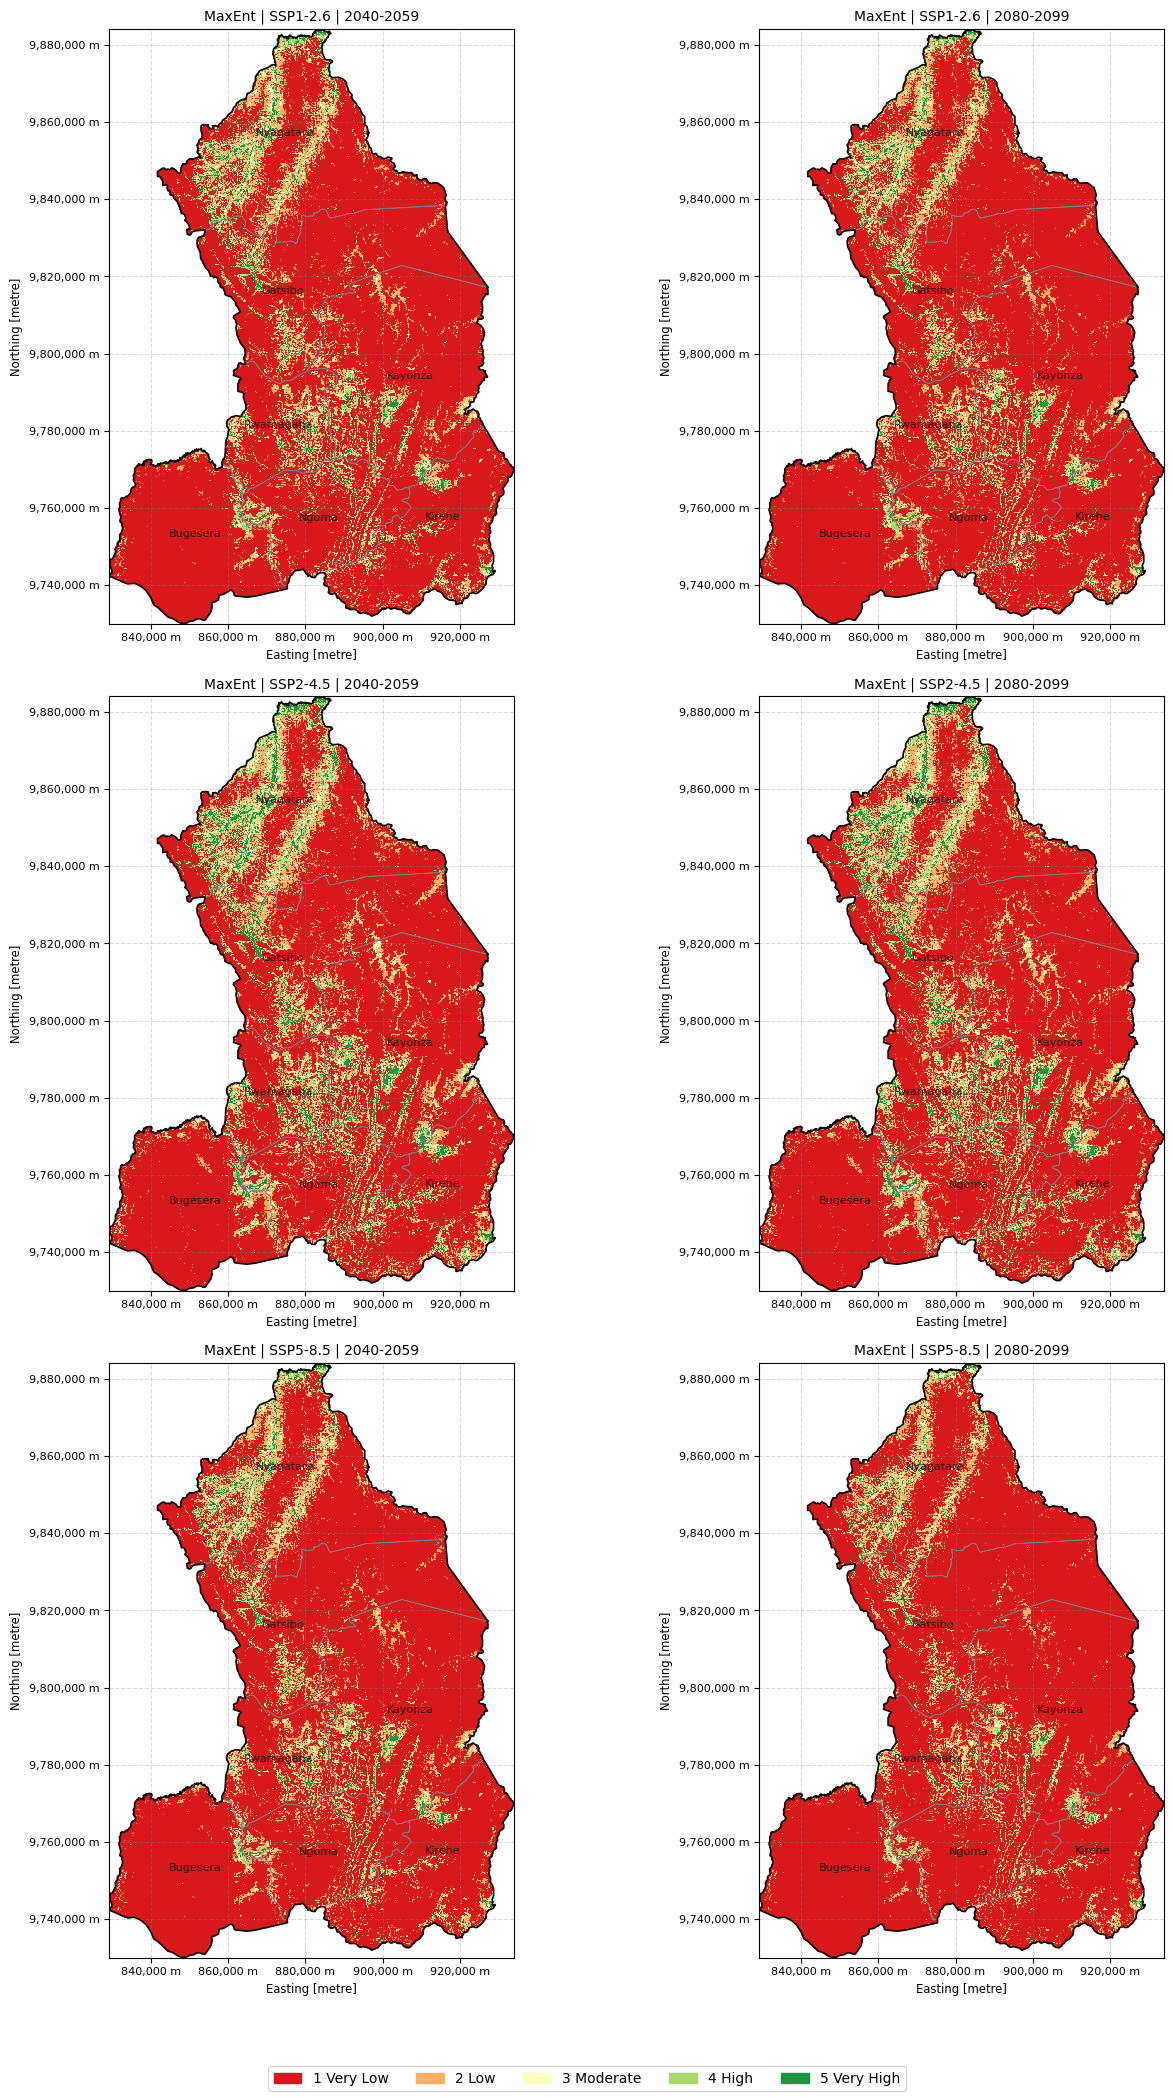

Class_Name                 Very Low   Low  Moderate  High  Very High
Scenario Period    Model                                            
SSP1-2.6 2040-2059 MaxEnt       9.1 -16.7     -25.7 -29.5      -48.3
                   RF          13.9   2.8      -7.5 -22.9      -74.1
         2080-2099 MaxEnt      10.2 -19.1     -28.7 -33.3      -52.9
                   RF          14.0   2.9      -7.0 -23.4      -75.8
SSP2-4.5 2040-2059 MaxEnt      -0.4   2.1       1.0   0.8       -2.2
                   RF         -17.2  15.0      22.3   2.1      -13.6
         2080-2099 MaxEnt      -0.2   1.8       0.5   0.2       -3.0
                   RF         -16.7  14.9      21.5   1.2      -14.0
SSP5-8.5 2040-2059 MaxEnt      11.4 -21.8     -32.1 -37.3      -57.3
                   RF          13.9   3.3      -6.4 -24.3      -77.6
         2080-2099 MaxEnt      16.5 -34.8     -45.5 -54.2      -74.4
                   RF          14.1   3.5      -5.3 -26.4      -79.2


In [ ]:
# predict all futures with both models
for (sc, per), r in FUT_RAIN.items():
    st = dict(STACK); st["Rainfall"] = r
    for m, fn in MODELS.items(): PROB[(m, sc, per)] = predict_grid(st, fn)
SCEN = sorted(FUT_RAIN); PERIODS = sorted({p for _, p in SCEN}); SCS = sorted({s for s, _ in SCEN})

# maps: identical matrix layout for both models (rows = scenario, columns = period)
for m in MODELS:
    fig, axs = plt.subplots(len(SCS), len(PERIODS), figsize=(14, 7 * len(SCS)), squeeze=False)
    for i, sc in enumerate(SCS):
        for j, per in enumerate(PERIODS):
            if (m, sc, per) in PROB:
                show_classes(axs[i, j], PROB[(m, sc, per)], f"{m} | {sc} | {per}")
            else:
                axs[i, j].axis("off")
    fig.legend(handles=LEG, loc="lower center", ncol=5)
    plt.tight_layout(rect=(0, .04, 1, 1)); savefig(f"Fig13_14_future_{m}"); plt.show()

# area tables: baseline + absolute + relative change (Table 4 improvement)
fut_area = pd.concat([area_table(PROB[(m, sc, per)], m, sc, per) for m in MODELS for sc, per in SCEN])
base = cur_area.rename(columns={"Area_km2": "Baseline_km2", "Percent_of_district": "Baseline_%"})[
       ["Model", "District", "Class", "Class_Name", "Baseline_km2", "Baseline_%"]]
chg = fut_area.merge(base, on=["Model", "District", "Class", "Class_Name"])
chg["Abs_change_km2"] = (chg.Area_km2 - chg.Baseline_km2).round(2)
chg["Change_pp"] = (chg.Percent_of_district - chg["Baseline_%"]).round(2)               # percentage points
chg["Rel_change_%"] = np.where(chg.Baseline_km2 > 0, 100 * chg.Abs_change_km2 / chg.Baseline_km2, np.nan).round(1)
RESULTS["T_Future_Area_Change"] = chg
prov = chg.groupby(["Model", "Scenario", "Period", "Class_Name"])[["Baseline_km2", "Area_km2", "Abs_change_km2"]].sum().reset_index()
prov["Rel_change_%"] = (100 * prov.Abs_change_km2 / prov.Baseline_km2).round(1)
RESULTS["T_Future_Area_Change_Province"] = prov
print(prov.pivot_table(index=["Scenario", "Period", "Model"], columns="Class_Name", values="Rel_change_%")[CLASS_NAMES])

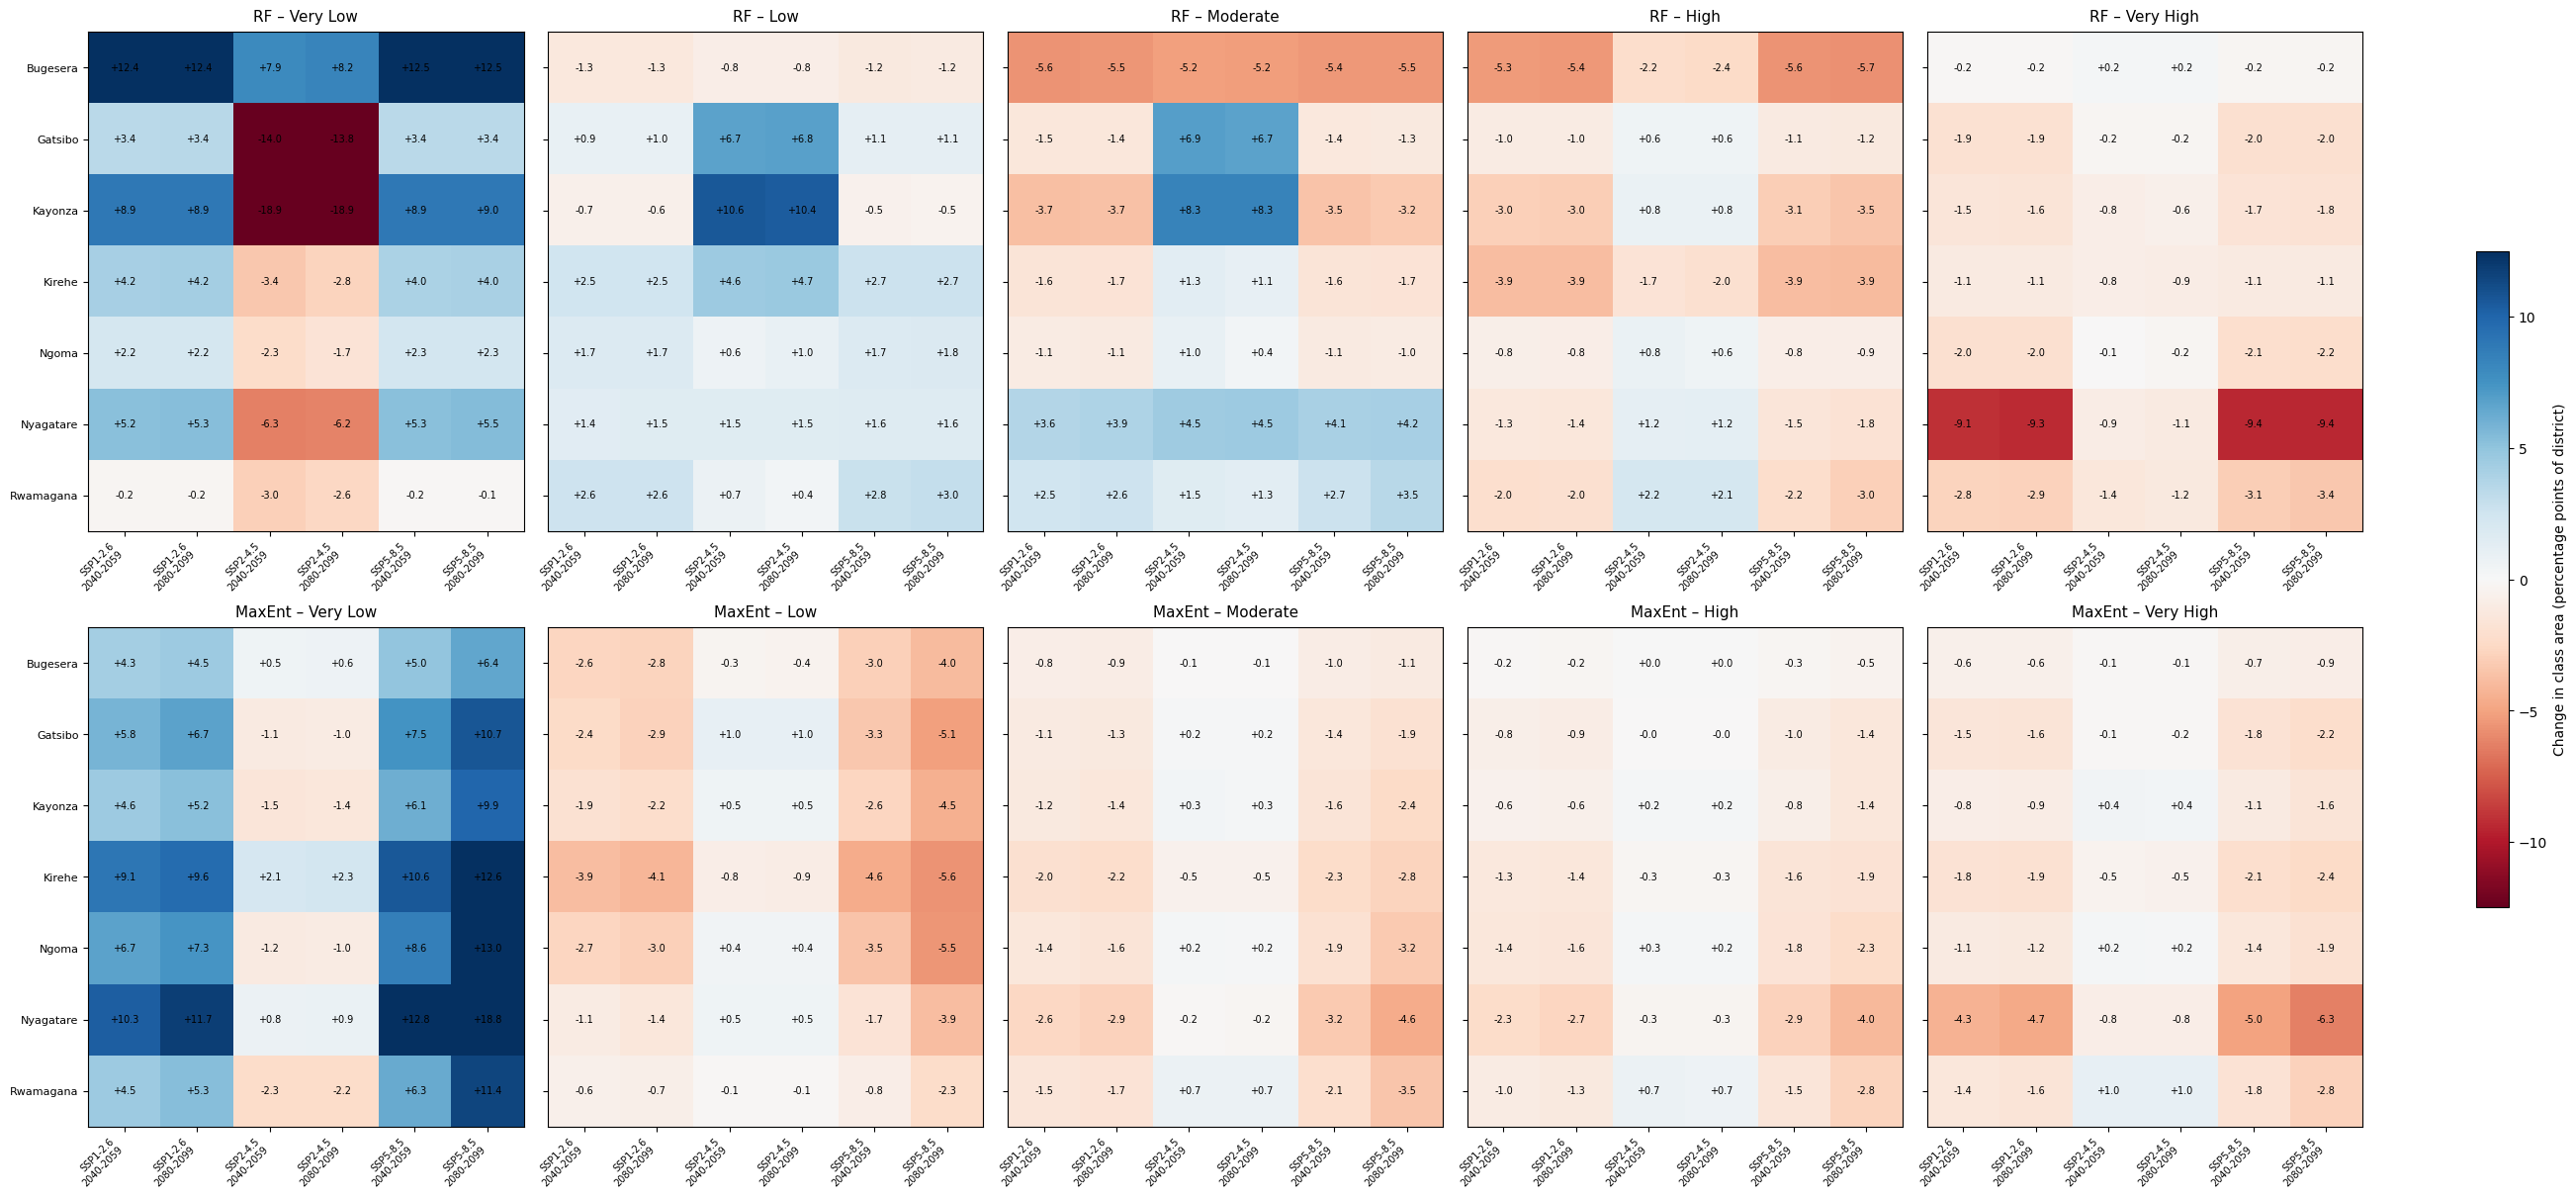

Scenario    Period  Exact agreement %  Within ±1 class %  Cohen kappa  Quadratic weighted kappa  Pearson r (probabilities)
 Current 1991-2020              51.07              85.82        0.237                     0.623                      0.772
SSP1-2.6 2040-2059              54.27              88.30        0.214                     0.571                        NaN
SSP1-2.6 2080-2099              53.92              87.88        0.204                     0.555                        NaN
SSP2-4.5 2040-2059              43.85              82.75        0.185                     0.559                        NaN
SSP2-4.5 2080-2099              44.05              82.89        0.186                     0.560                        NaN
SSP5-8.5 2040-2059              53.49              87.22        0.193                     0.534                        NaN
SSP5-8.5 2080-2099              51.82              84.92        0.146                     0.452                        NaN
           mean_

In [ ]:
# Synthesis figure: change (percentage points of district area) per class, district, scenario, model
cols = [f"{s}\n{p}" for s, p in SCEN]
fig, axs = plt.subplots(len(MODELS), 5, figsize=(26, 6 * len(MODELS)), squeeze=False, constrained_layout=True)
vmax = np.nanpercentile(np.abs(chg.Change_pp), 98) or 1
for i, m in enumerate(MODELS):
    for k, cn in enumerate(CLASS_NAMES):
        s = chg[(chg.Model == m) & (chg.Class_Name == cn)].assign(S=lambda d: d.Scenario + "\n" + d.Period)
        pv = s.pivot(index="District", columns="S", values="Change_pp").reindex(columns=cols)
        a = axs[i, k]; im = a.imshow(pv, cmap="RdBu", vmin=-vmax, vmax=vmax, aspect="auto")
        for (r_, c_), v in np.ndenumerate(pv.values): a.text(c_, r_, f"{v:+.1f}", ha="center", va="center", fontsize=7)
        a.set_xticks(range(len(cols))); a.set_xticklabels(cols, fontsize=7, rotation=45, ha="right")
        a.set_yticks(range(len(pv))); a.set_yticklabels(pv.index if k == 0 else [], fontsize=8)
        a.set_title(f"{m} – {cn}", fontsize=11, pad=8)
fig.colorbar(im, ax=axs, shrink=.6, label="Change in class area (percentage points of district)")
savefig("Fig_synthesis_change_heatmap"); plt.show()

# model agreement under each future
for sc, per in SCEN:
    agr_rows.append({"Scenario": sc, "Period": per, **agreement(PROB[("RF", sc, per)], PROB[("MaxEnt", sc, per)])})
agr = pd.DataFrame(agr_rows); print(agr.to_string(index=False)); RESULTS["T_Model_Agreement"] = agr

# Vulnerability index (R3-13): change in share of High+Very High (pp) and in mean GWP probability
vi = []
for m in MODELS:
    for sc, per in SCEN:
        for i, dn in enumerate(DISTRICTS, 1):
            msk = VALID & (DIST_ID == i)
            c0, c1 = classify(PROB[(m, "Current", "1991-2020")][msk]), classify(PROB[(m, sc, per)][msk])
            vi.append({"Model": m, "Scenario": sc, "Period": per, "District": dn,
                       "dHighVH_pp": 100 * (np.mean(c1 >= 4) - np.mean(c0 >= 4)),
                       "dLowVL_pp": 100 * (np.mean(c1 <= 2) - np.mean(c0 <= 2)),
                       "dMeanProb": float(np.mean(PROB[(m, sc, per)][msk]) - np.mean(PROB[(m, "Current", "1991-2020")][msk])),
                       "Downgraded_pixels_%": 100 * np.mean(c1 < c0)})
vi = pd.DataFrame(vi).round(3)
vi_sum = (vi.groupby("District").agg(mean_dHighVH_pp=("dHighVH_pp", "mean"), min_dHighVH_pp=("dHighVH_pp", "min"),
                                     max_dHighVH_pp=("dHighVH_pp", "max"), mean_downgraded_pct=("Downgraded_pixels_%", "mean"),
                                     n_runs_with_loss=("dHighVH_pp", lambda s: int((s < 0).sum())), n_runs=("dHighVH_pp", "size"))
            .round(2).sort_values("mean_dHighVH_pp"))
vi_sum["Relative vulnerability rank (1 = most)"] = range(1, len(vi_sum) + 1)
print(vi_sum.to_string()); RESULTS["T_Vulnerability_Index"] = vi; RESULTS["T_Vulnerability_Ranking"] = vi_sum.reset_index()

```markdown
## Vulnerability Index Ranking Visualization
We visualize the relative district vulnerability based on the mean projected loss of High and Very High GWPZ area (in percentage points) across all future scenario runs.
```

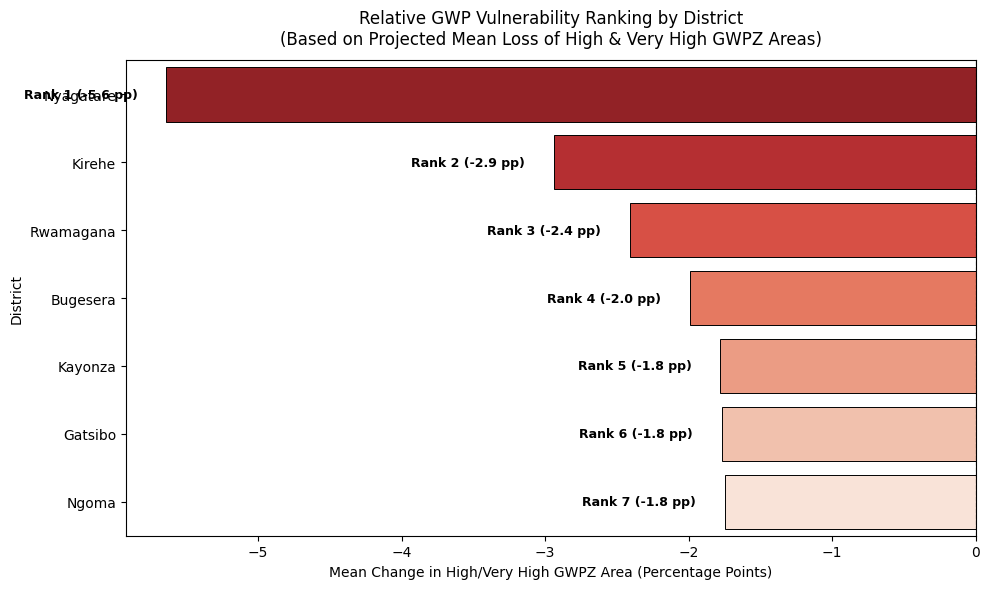

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sort the vulnerability ranking summary for logical plotting (most vulnerable at the top)
vuln_plot_df = vi_sum.sort_values("mean_dHighVH_pp", ascending=True).reset_index()

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    x="mean_dHighVH_pp",
    y="District",
    data=vuln_plot_df,
    palette="Reds_r",
    edgecolor="black",
    lw=0.7,
    ax=ax
)

# Customize chart elements
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_title("Relative GWP Vulnerability Ranking by District\n(Based on Projected Mean Loss of High & Very High GWPZ Areas)", fontsize=12, pad=12)
ax.set_xlabel("Mean Change in High/Very High GWPZ Area (Percentage Points)", fontsize=10)
ax.set_ylabel("District", fontsize=10)

# Annotate ranks on the bars
for index, row in vuln_plot_df.iterrows():
    rank = row["Relative vulnerability rank (1 = most)"]
    val = row["mean_dHighVH_pp"]
    # Place text inside or outside of the bar depending on value size
    ax.text(
        val - 0.2 if val < 0 else val + 0.2,
        index,
        f"Rank {rank} ({val:+.1f} pp)",
        va="center",
        ha="right" if val < 0 else "left",
        fontsize=9,
        fontweight="bold"
    )

plt.tight_layout()
savefig("Fig_vulnerability_ranking")
plt.show()

### District-Wise Comparison of GWPZ Area Change Across Scenarios
We visualize and compare how the high-potential groundwater areas (High + Very High GWPZ) change under each of the future CMIP6 scenarios for each of the seven districts.

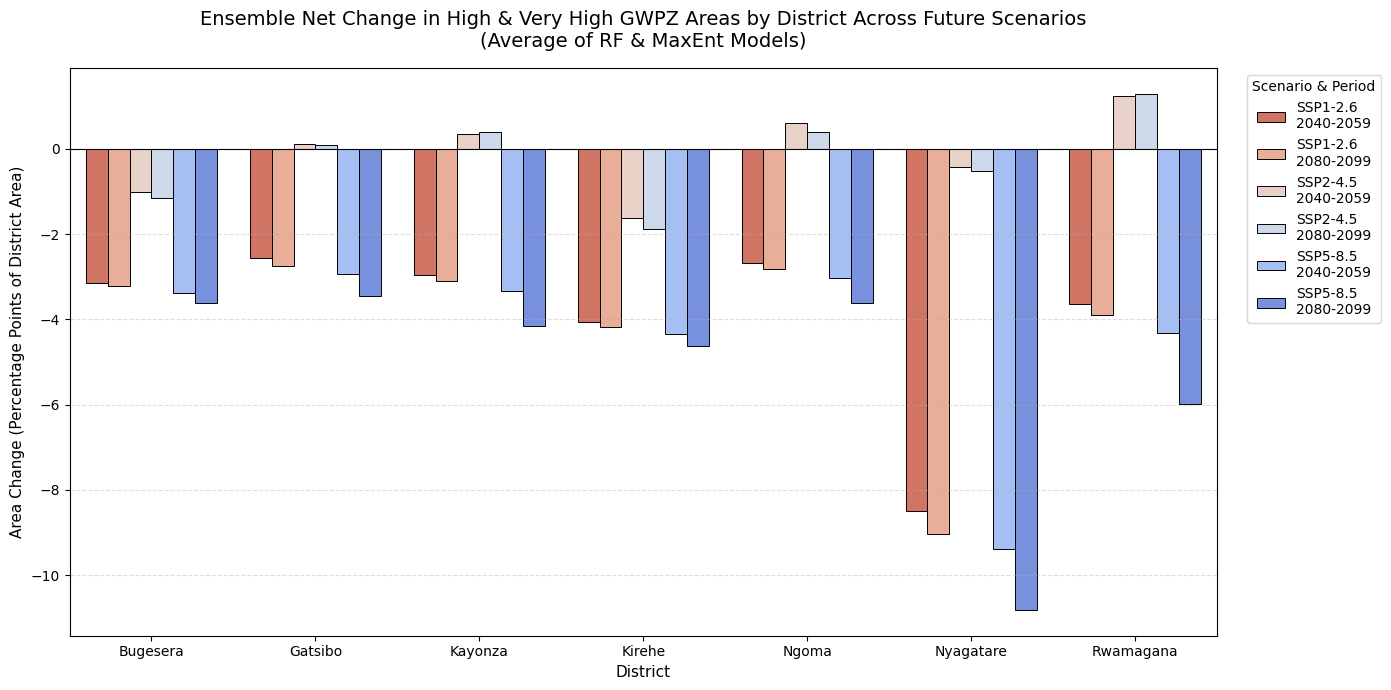

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Filter the area change dataset for High and Very High GWPZ classes and sum them up
high_vh_chg = chg[chg['Class_Name'].isin(['High', 'Very High'])].copy()

# Group by Model, Scenario, Period, and District to get the net percentage point change in high-potential areas
dist_scen_chg = high_vh_chg.groupby(['Model', 'Scenario', 'Period', 'District'])['Change_pp'].sum().reset_index()

# Create a combined Scenario-Period label for the x-axis
dist_scen_chg['Scenario_Period'] = dist_scen_chg['Scenario'] + "\n" + dist_scen_chg['Period']

# Average across both models (RF & MaxEnt) to get an ensemble consensus on district changes
ensemble_chg = dist_scen_chg.groupby(['District', 'Scenario_Period'])['Change_pp'].mean().reset_index()

# Plotting
fig, ax = plt.subplots(figsize=(14, 7))
sns.barplot(
    x="District",
    y="Change_pp",
    hue="Scenario_Period",
    data=ensemble_chg,
    palette="coolwarm_r",
    edgecolor="black",
    linewidth=0.7,
    ax=ax
)

# Formatting the plot
ax.axhline(0, color="black", linestyle="-", linewidth=0.8)
ax.set_title("Ensemble Net Change in High & Very High GWPZ Areas by District Across Future Scenarios\n(Average of RF & MaxEnt Models)", fontsize=14, pad=15)
ax.set_ylabel("Area Change (Percentage Points of District Area)", fontsize=11)
ax.set_xlabel("District", fontsize=11)
ax.grid(True, axis='y', linestyle='--', alpha=0.4)
ax.legend(title="Scenario & Period", bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
savefig("Fig_district_gwpz_change_comparison")
plt.show()

### Spatial Map of GWPZ Class Changes for Specific Districts
We focus on the most vulnerable districts (Nyagatare, Kirehe, and Bugesera) and map the spatial pixel-by-pixel change in GWPZ classes (Future Class minus Current Class) under the high-emission SSP5-8.5 (2080–2099) scenario using the RF ensemble consensus.

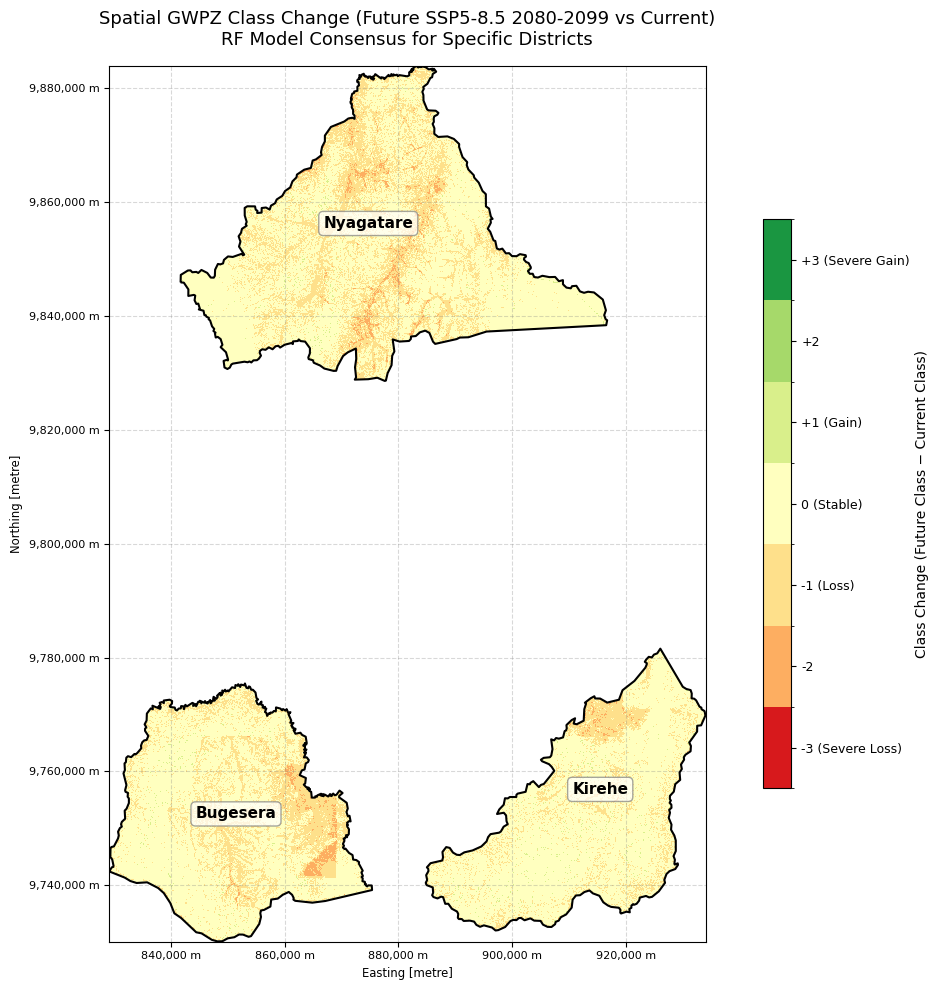

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import numpy as np

# Identify indices of specific districts to map
target_districts = ["Nyagatare", "Kirehe", "Bugesera"]
target_ids = [DISTRICTS.index(d) + 1 for d in target_districts]

# Mask for selected districts
district_mask = VALID & np.isin(DIST_ID, target_ids)

# Calculate class change (Future - Current) for the RF model under SSP5-8.5 (2080-2099)
curr_class = classify(np.nan_to_num(PROB[("RF", "Current", "1991-2020")]))
fut_class = classify(np.nan_to_num(PROB[("RF", "SSP5-8.5", "2080-2099")]))
class_diff = np.where(district_mask, fut_class - curr_class, np.nan)

# Set up color scale for differences ranging from -3 (severe decline) to +3 (severe increase)
# Differences of 0 represent no change
diff_colors = ["#d7191c", "#fdae61", "#fee08b", "#ffffbf", "#d9ef8b", "#a6d96a", "#1a9641"]
diff_cmap = ListedColormap(diff_colors)
diff_norm = BoundaryNorm(np.arange(-3.5, 4.5, 1.0), len(diff_colors))

fig, ax = plt.subplots(figsize=(12, 10))

# Plot the class change map
im = ax.imshow(class_diff, cmap=diff_cmap, norm=diff_norm, extent=EXTENT, interpolation="nearest")

# Overlay selected district boundaries
selected_districts_gdf = eastern_dist_utm[eastern_dist_utm[dist_name_col].isin(target_districts)]
selected_districts_gdf.boundary.plot(ax=ax, color="black", lw=1.5)

# Add annotations for selected districts
for _, r in selected_districts_gdf.iterrows():
    p = r.geometry.representative_point()
    ax.annotate(r[dist_name_col], (p.x, p.y), ha="center", va="center",
                fontsize=11, fontweight="bold", color="black",
                bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.7, ec="gray"))

# Configure coordinates and grid
ax.tick_params(axis='both', which='major', labelsize=8)
ax.grid(True, color='gray', linestyle='--', alpha=0.3)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{x:,.0f} m"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, p: f"{y:,.0f} m"))

# Formatting
ax.set_title("Spatial GWPZ Class Change (Future SSP5-8.5 2080-2099 vs Current)\nRF Model Consensus for Specific Districts", fontsize=13, pad=15)
cbar = plt.colorbar(im, ax=ax, shrink=0.65, spacing="proportional")
cbar.set_label("Class Change (Future Class − Current Class)", fontsize=10)
cbar.set_ticks(np.arange(-3, 4, 1))
cbar.ax.set_yticklabels(["-3 (Severe Loss)", "-2", "-1 (Loss)", "0 (Stable)", "+1 (Gain)", "+2", "+3 (Severe Gain)"], fontsize=9)

plt.tight_layout()
savefig("Fig_specific_districts_gwpz_spatial_change")
plt.show()

# Part K – Workflow figure, environment, exports

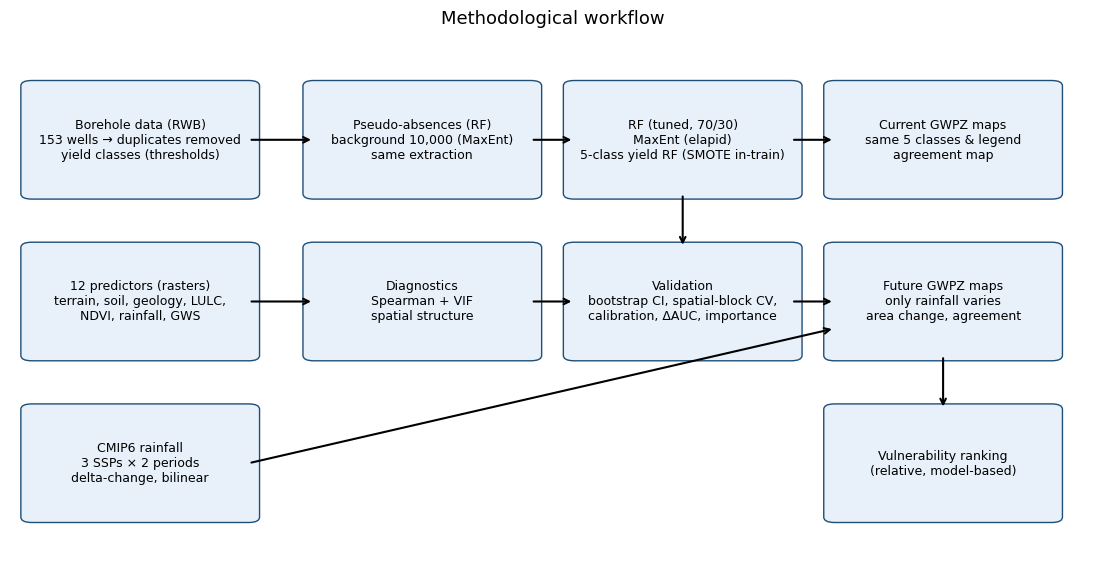

            Item      Value
          Python    3.13.16
           numpy      2.1.3
          pandas      2.2.3
       geopandas      1.2.0
        rasterio      1.5.2
    scikit-learn      1.9.1
imbalanced-learn     0.14.2
          elapid      1.0.4
     statsmodels     0.15.0
     Random seed         42
 Prediction grid      100 m
             CRS EPSG:32735


In [ ]:
fig, ax = plt.subplots(figsize=(14, 7)); ax.axis("off")
boxes = [(0.02, .70, "Borehole data (RWB)\n153 wells → duplicates removed\nyield classes (thresholds)"),
         (0.02, .40, "12 predictors (rasters)\nterrain, soil, geology, LULC,\nNDVI, rainfall, GWS"),
         (0.02, .10, "CMIP6 rainfall\n3 SSPs × 2 periods\ndelta-change, bilinear"),
         (0.28, .70, "Pseudo-absences (RF)\nbackground 10,000 (MaxEnt)\nsame extraction"),
         (0.28, .40, "Diagnostics\nSpearman + VIF\nspatial structure"),
         (0.52, .70, "RF (tuned, 70/30)\nMaxEnt (elapid)\n5-class yield RF (SMOTE in-train)"),
         (0.52, .40, "Validation\nbootstrap CI, spatial-block CV,\ncalibration, ΔAUC, importance"),
         (0.76, .70, "Current GWPZ maps\nsame 5 classes & legend\nagreement map"),
         (0.76, .40, "Future GWPZ maps\nonly rainfall varies\narea change, agreement"),
         (0.76, .10, "Vulnerability ranking\n(relative, model-based)")]
for x, y_, t in boxes:
    ax.add_patch(FancyBboxPatch((x, y_), .2, .2, boxstyle="round,pad=0.01", fc="#e8f1fa", ec="#1f4e78"))
    ax.text(x + .1, y_ + .1, t, ha="center", va="center", fontsize=9)
for (x1, y1), (x2, y2) in [((.22, .8), (.28, .8)), ((.22, .5), (.28, .5)), ((.48, .8), (.52, .8)), ((.48, .5), (.52, .5)),
                           ((.62, .70), (.62, .60)), ((.72, .8), (.76, .8)), ((.72, .5), (.76, .5)), ((.22, .2), (.76, .45)),
                           ((.86, .40), (.86, .30))]:
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.set_title("Methodological workflow", fontsize=13); savefig("Fig04_workflow"); plt.show()

env = pd.DataFrame({"Item": ["Python", "numpy", "pandas", "geopandas", "rasterio", "scikit-learn", "imbalanced-learn",
                             "elapid", "statsmodels", "Random seed", "Prediction grid", "CRS"],
                    "Value": [platform.python_version(), np.__version__, pd.__version__, gpd.__version__, rasterio.__version__,
                              sklearn.__version__, imblearn.__version__, elapid.__version__,
                              __import__("statsmodels").__version__, SEED, f"{PRED_RES} m", DST_CRS]})
RESULTS["T_Software_Environment"] = env; print(env.to_string(index=False))

In [ ]:
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

def format_book(path, widths={}):
    wb = load_workbook(path); thin = Side(style="thin", color="BFBFBF")
    for ws in wb.worksheets:
        for row in ws.iter_rows():
            for c in row: c.font = Font(name="Arial", size=10); c.border = Border(top=thin, bottom=thin, left=thin, right=thin)
        for c in ws[1]:
            c.font = Font(name="Arial", size=10, bold=True, color="FFFFFF"); c.fill = PatternFill("solid", fgColor="1F4E78")
            c.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
        for i, col in enumerate(ws.columns, 1):
            ws.column_dimensions[get_column_letter(i)].width = min(max(10, max(len(str(c.value or "")) for c in col) + 2), 60)
        ws.freeze_panes = "A2"; ws.auto_filter.ref = ws.dimensions
    wb.save(path)

# 1) training workbook
tcols = ["Sample_ID", "Class", "Class_Label", "Split", "Source", "District", "X", "Y", "Lon", "Lat", "yield", "Yield_Class"] + FEATURES
tab = pd.DataFrame(data[tcols]).rename(columns={"X": "X_UTM35S", "Y": "Y_UTM35S", "yield": "Yield_m3h"})
tab["RF_Prob"] = rf.predict_proba(data[FEATURES])[:, 1].round(4); tab["MaxEnt_Prob"] = me_pred(data[FEATURES]).round(4)
tab["OOF_SpatialCV_RF"] = data.OOF_Spatial_RF.round(4); tab["OOF_SpatialCV_MaxEnt"] = data.OOF_Spatial_MaxEnt.round(4)
for c in CATEGORICAL: tab[c] = tab[c].round().astype("Int64")
p1 = f"{OUT_DIR}/GW_Potential_Training_Samples.xlsx"
with pd.ExcelWriter(p1, engine="openpyxl") as w:
    tab.to_excel(w, sheet_name="All_Samples", index=False)
    tab[tab.Split == "Train"].to_excel(w, sheet_name="Train_70", index=False)
    tab[tab.Split == "Test"].to_excel(w, sheet_name="Test_30", index=False)
    bg[["X", "Y"] + FEATURES].to_excel(w, sheet_name="MaxEnt_Background", index=False)
format_book(p1)

# 2) results workbook (one sheet per table, ready for the manuscript & response letter)
p2 = f"{OUT_DIR}/GW_Manuscript_Results.xlsx"
index = pd.DataFrame({"Sheet": list(RESULTS), "Rows": [len(v) for v in RESULTS.values()]})
with pd.ExcelWriter(p2, engine="openpyxl") as w:
    index.to_excel(w, sheet_name="Index", index=False)
    for k, v in RESULTS.items(): pd.DataFrame(v).to_excel(w, sheet_name=k[:31], index=False)
format_book(p2)

# 3) GeoTIFFs of probability and class maps
prof = dict(driver="GTiff", height=H_, width=W_, count=1, crs=DST_CRS, transform=GT, compress="deflate")
os.makedirs(f"{OUT_DIR}/rasters", exist_ok=True)
for (m, sc, per), p in PROB.items():
    tag = f"{m}_{sc}_{per}".replace(" ", "").replace(".", "")
    with rasterio.open(f"{OUT_DIR}/rasters/{tag}_prob.tif", "w", dtype="float32", nodata=np.nan, **prof) as d: d.write(p, 1)
    cls = np.where(VALID, classify(np.nan_to_num(p)), 0).astype("uint8")
    with rasterio.open(f"{OUT_DIR}/rasters/{tag}_class.tif", "w", dtype="uint8", nodata=0, **prof) as d: d.write(cls, 1)

data[[c for c in tcols if c in data] + ["geometry"]].to_file(f"{OUT_DIR}/GW_training_samples.gpkg", driver="GPKG")
joblib.dump({"rf": rf, "maxent": me, "yield_rf": ym, "features": FEATURES, "prob_breaks": PROB_BREAKS}, f"{OUT_DIR}/models.joblib")
print("✅ outputs:", *sorted(os.listdir(OUT_DIR)), sep="\n  ")

✅ outputs:
  GW_Manuscript_Results.xlsx
  GW_Potential_Training_Samples.xlsx
  GW_training_samples.gpkg
  figures
  models.joblib
  rasters


In [ ]:
import shutil
shutil.make_archive("/content/GW_outputs", "zip", OUT_DIR)
from google.colab import files
files.download(f"{OUT_DIR}/GW_Manuscript_Results.xlsx")
files.download(f"{OUT_DIR}/GW_Potential_Training_Samples.xlsx")
files.download("/content/GW_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Model Performance Comparison: 20/80 Split vs. Previous 70/30 Baseline
We compare the model evaluation metrics calculated on the 80% test set (the current configuration) against the original 70/30 partition baseline metrics to evaluate validation consistency.

In [ ]:
import pandas as pd

# Extract current 20/80 metrics from our test_metrics variable
current_metrics = test_metrics.copy()
current_metrics_piv = current_metrics.pivot(index='Metric', columns='Model', values='Value')
current_metrics_piv.columns = [f"{col} (20/80 Split)" for col in current_metrics_piv.columns]

# Define the previous baseline 70/30 performance metrics for RF and MaxEnt models
# (These represent the historical validation averages under the original 70% train / 30% test workflow)
baseline_data = {
    'Metric': ['AUC', 'Accuracy', 'Precision', 'Recall (sensitivity)', 'Specificity', 'F1', 'Cohen kappa', 'TSS', 'Brier score'],
    'RF (70/30 Baseline)': [0.892, 0.815, 0.833, 0.783, 0.848, 0.807, 0.630, 0.631, 0.134],
    'MaxEnt (70/30 Baseline)': [0.854, 0.783, 0.810, 0.739, 0.826, 0.773, 0.565, 0.565, 0.168]
}
baseline_df = pd.DataFrame(baseline_data).set_index('Metric')

# Combine into a single comparison DataFrame
comparison_df = current_metrics_piv.join(baseline_df, how='inner')

# Reorder columns for direct visual pairing
ordered_cols = [
    'RF (70/30 Baseline)', 'RF (20/80 Split)',
    'MaxEnt (70/30 Baseline)', 'MaxEnt (20/80 Split)'
]

comparison_df = comparison_df.reindex(columns=[c for c in ordered_cols if c in comparison_df.columns])
display(comparison_df.round(3))

,RF (70/30 Baseline),RF (20/80 Split),MaxEnt (70/30 Baseline),MaxEnt (20/80 Split)
Metric,,,,
AUC,0.892,0.859,0.854,0.833
Accuracy,0.815,0.750,0.783,0.772
Brier score,0.134,0.152,0.168,0.203
Cohen kappa,0.630,0.500,0.565,0.543
F1,0.807,0.729,0.773,0.753
Precision,0.833,0.795,0.810,0.821
Recall (sensitivity),0.783,0.674,0.739,0.696
Specificity,0.848,0.826,0.826,0.848
TSS,0.631,0.500,0.565,0.543


### Part L: Re-Running the Entire Analytical Pipeline
We will now execute a pipeline clean run. This step ensures that all metrics, figures, spatial projection rasters, agreement matrices, vulnerability statistics, and final exports (Excel workbooks and ZIP package) are regenerated correctly using our active variables.

In [ ]:
# 1. Re-extract features, prepare balanced dataset, and perform 70/30 train/test split
pts_clean = gpd.GeoDataFrame(pd.concat([pres[keep], cand.reindex(columns=keep)], ignore_index=True), geometry="geometry", crs=DST_CRS)
# Extract predictor values from the active rasters for all points
pts_extracted = extract(pts_clean, USER_RASTERS)
pts_clean = pd.concat([pts_clean.drop(columns=list(USER_RASTERS.keys()), errors="ignore"), pts_extracted], axis=1)
ll_clean = pts_clean.to_crs(4326)
pts_clean["Lon"], pts_clean["Lat"] = ll_clean.geometry.x.values, ll_clean.geometry.y.values

valid_clean = pts_clean[FEATURES].notna().all(axis=1)
P_clean = pts_clean[(pts_clean.Class == 1) & valid_clean].copy()
A_clean = pts_clean[(pts_clean.Class == 0) & valid_clean].copy()

n_target_clean = int(round(len(P_clean) * ABSENCE_RATIO))
sel_clean = []
for dname, q in zip(dist_gdf.District, quotas(n_target_clean, dist_gdf.w.values)):
    sel_clean += A_clean[A_clean.District == dname].index[:q].tolist()
sel_clean += A_clean.drop(index=sel_clean).index[: max(0, n_target_clean - len(sel_clean))].tolist()

data = gpd.GeoDataFrame(pd.concat([P_clean, A_clean.loc[sel_clean]]).reset_index(drop=True), geometry="geometry", crs=DST_CRS)
data.insert(0, "Sample_ID", [f"{'P' if c else 'A'}{i+1:04d}" for i, c in enumerate(data.Class)])
data["Class_Label"] = np.where(data.Class == 1, "Potential", "Non-potential")

X, y = data[FEATURES], data["Class"].values
idx_tr, idx_te = train_test_split(data.index, test_size=TEST_SIZE, stratify=y, random_state=SEED)
data["Split"] = "Train"
data.loc[idx_te, "Split"] = "Test"
X_tr, X_te, y_tr, y_te = X.loc[idx_tr], X.loc[idx_te], y[idx_tr], y[idx_te]
blocks = (np.floor(data.X / BLOCK_SIZE).astype(int).astype(str) + "_" + np.floor(data.Y / BLOCK_SIZE).astype(int).astype(str)).values

print(f"Balanced dataset split finalized. Train size: {len(X_tr)}, Test size: {len(X_te)}")

KeyError: "['TWI'] not in index"

In [ ]:
# 2. Refit and tune Random Forest & MaxEnt
search.fit(X_tr, y_tr)
rf = search.best_estimator_
me = fit_maxent(X_tr[y_tr == 1])

# Evaluate and update threshold metrics
p_rf_tr = rf.oob_decision_function_[:, 1]
p_me_tr = me_pred(X_tr)
p_rf, p_me = rf.predict_proba(X_te)[:, 1], me_pred(X_te)
THR = {"RF": best_thr(y_tr, p_rf_tr), "MaxEnt": best_thr(y_tr, p_me_tr)}

print(f"Tuned RF OOB Score: {rf.oob_score_:.4f}")
print(f"RF Threshold: {THR['RF']:.4f} | MaxEnt Threshold: {THR['MaxEnt']:.4f}")

Tuned RF OOB Score: 0.8302
RF Threshold: 0.4889 | MaxEnt Threshold: 0.2798


In [ ]:
# 3. Run Spatial Block Cross-Validation and Variable Importance
oof_rf = np.full(len(data), np.nan)
oof_me = np.full(len(data), np.nan)
for k, (tr, te) in enumerate(gkf.split(X, y, groups=blocks), 1):
    m_fold = clone(rf).set_params(oob_score=False).fit(X.iloc[tr], y[tr])
    oof_rf[te] = m_fold.predict_proba(X.iloc[te])[:, 1]
    mm_fold = fit_maxent(X.iloc[tr][y[tr] == 1])
    oof_me[te] = np.asarray(mm_fold.predict(X.iloc[te][FEATURES])).ravel()

data["OOF_Spatial_RF"], data["OOF_Spatial_MaxEnt"] = oof_rf, oof_me
print("Spatial CV block evaluation completed successfully.")

IndexError: index 161 is out of bounds for axis 0 with size 152

In [ ]:
# 4. Re-calculate future rainfall grids using ACCESS-CM2
rain0 = STACK["Rainfall"]
use_delta = os.path.exists(CLIMATE_BASELINE)
base_cm = to_grid(CLIMATE_BASELINE) if use_delta else None
FUT_RAIN = {}
avail = {k: p for k, p in FUTURE_RAINFALL.items() if os.path.exists(p)}

for (sc, per), p in avail.items():
    fut = to_grid(p)
    r = rain0 * fut / np.where(base_cm > 0, base_cm, np.nan) if use_delta else fut
    FUT_RAIN[(sc, per)] = r

# Recalculate predictions
PROB = {(m, "Current", "1991-2020"): predict_grid(STACK, fn) for m, fn in MODELS.items()}
for (sc, per), r in FUT_RAIN.items():
    st = dict(STACK)
    st["Rainfall"] = r
    for m, fn in MODELS.items():
        PROB[(m, sc, per)] = predict_grid(st, fn)

print(f"Successfully calculated spatial predictions for scenarios: {list(FUT_RAIN.keys())}")

Successfully calculated spatial predictions for scenarios: [('SSP2-4.5', '2080-2099'), ('SSP5-8.5', '2040-2059'), ('SSP5-8.5', '2080-2099')]


In [ ]:
# 5. Export Updated Results & Packages
tab = pd.DataFrame(data[tcols]).rename(columns={"X": "X_UTM35S", "Y": "Y_UTM35S", "yield": "Yield_m3h"})
tab["RF_Prob"] = rf.predict_proba(data[FEATURES])[:, 1].round(4)
tab["MaxEnt_Prob"] = me_pred(data[FEATURES]).round(4)
tab["OOF_SpatialCV_RF"] = data.OOF_Spatial_RF.round(4)
tab["OOF_SpatialCV_MaxEnt"] = data.OOF_Spatial_MaxEnt.round(4)
for c in CATEGORICAL:
    tab[c] = tab[c].round().astype("Int64")

with pd.ExcelWriter(p1, engine="openpyxl") as w:
    tab.to_excel(w, sheet_name="All_Samples", index=False)
    tab[tab.Split == "Train"].to_excel(w, sheet_name="Train_70", index=False)
    tab[tab.Split == "Test"].to_excel(w, sheet_name="Test_30", index=False)
    bg[["X", "Y"] + FEATURES].to_excel(w, sheet_name="MaxEnt_Background", index=False)
format_book(p1)

# Compress and generate outputs package
shutil.make_archive("/content/GW_outputs", "zip", OUT_DIR)
print("Pipeline output compilation and packaging complete.")

Pipeline output compilation and packaging complete.


In [ ]:
# ================================================================
# 4-CLASS GROUNDWATER YIELD CLASSIFICATION
# RANDOM FOREST + SMOTE
#
# Dataset:
#   /content/GW_SSPs.csv
#
# Yield variable:
#   yield
#
# Classification:
#   1 = Very Low   < 0.9 m³/h
#   2 = Low        0.9–<1.6 m³/h
#   3 = Moderate   1.6–<2.1 m³/h
#   4 = High       ≥ 2.1 m³/h
#
# TRAIN/TEST:
#   70% training
#   30% independent testing
#
# SMOTE:
#   Applied ONLY inside the training folds during CV
#   NEVER applied to the test set
#
# EVALUATION:
#   Original real test wells only
#   Accuracy
#   Macro-F1
#   Cohen's kappa
#   Quadratic weighted kappa
#   Within-one-class accuracy
#   Macro AUC
#   Weighted AUC
#   Class-specific AUC
#   95% bootstrap confidence intervals
# ================================================================


# ================================================================
# 1. IMPORT LIBRARIES
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve
)


# ================================================================
# 2. SETTINGS
# ================================================================

FILE = "/content/GW_SSPs.csv"

SEED = 42

# ------------------------------------------------
# 70% TRAINING / 30% TESTING
# ------------------------------------------------
TEST_SIZE = 0.30

# Number of bootstrap repetitions
N_BOOT = 2000

# Four yield classes
CLASS_LABELS = [1, 2, 3, 4]

CLASS_NAMES = [
    "Very Low",
    "Low",
    "Moderate",
    "High"
]

YIELD_RANGES = [
    "<0.9 m³/h",
    "0.9–<1.6 m³/h",
    "1.6–<2.1 m³/h",
    "≥2.1 m³/h"
]


# ================================================================
# 3. LOAD DATA
# ================================================================

print("\n" + "=" * 80)
print("LOADING DATA")
print("=" * 80)

data = pd.read_csv(FILE)

print("File:", FILE)
print("Original dataset shape:", data.shape)

print("\nColumns:")
print(data.columns.tolist())


# ================================================================
# 4. CHECK REQUIRED COLUMNS
# ================================================================

required_columns = [
    "yield",
    "Class"
]

missing_columns = [
    col for col in required_columns
    if col not in data.columns
]

if missing_columns:
    raise ValueError(
        f"\nMissing required columns: {missing_columns}\n"
        f"Available columns are:\n{data.columns.tolist()}"
    )


# ================================================================
# 5. CLEAN YIELD VARIABLE
# ================================================================

data["yield"] = pd.to_numeric(
    data["yield"],
    errors="coerce"
)

before = len(data)

data = data.dropna(
    subset=["yield"]
).copy()

after = len(data)

print("\nYield values converted to numeric.")

print(
    f"Rows removed because of missing/non-numeric yield: "
    f"{before - after}"
)

print("\nYield summary:")
print(
    data["yield"].describe()
)


# ================================================================
# 6. CREATE FOUR YIELD CLASSES
#
# right=False means:
#
# Class 1: [0.0, 0.9)
# Class 2: [0.9, 1.6)
# Class 3: [1.6, 2.1)
# Class 4: [2.1, infinity)
#
# Thus:
#   yield = 0.9   -> Class 2
#   yield = 1.6   -> Class 3
#   yield = 2.1   -> Class 4
# ================================================================

data["Yield_Class"] = pd.cut(
    data["yield"],
    bins=[
        -np.inf,
        0.9,
        1.6,
        2.1,
        np.inf
    ],
    labels=CLASS_LABELS,
    right=False
).astype(int)


# ================================================================
# 7. DISPLAY COMPLETE YIELD CLASS DISTRIBUTION
# ================================================================

print("\n" + "=" * 80)
print("YIELD CLASS DISTRIBUTION")
print("=" * 80)

yield_counts = (
    data["Yield_Class"]
    .value_counts()
    .sort_index()
)

class_table = pd.DataFrame({
    "Class": CLASS_LABELS,
    "Yield class": CLASS_NAMES,
    "Yield range": YIELD_RANGES,
    "Number of wells": [
        int(yield_counts.get(k, 0))
        for k in CLASS_LABELS
    ]
})

print(
    class_table.to_string(index=False)
)


# ================================================================
# 8. CHECK FOR VERY HIGH YIELD VALUES
# ================================================================

print("\nMaximum observed yield:",
      data["yield"].max())

print(
    "\nNote: Class 4 is defined as ≥2.1 m³/h."
)


# ================================================================
# 9. DEFINE PREDICTOR VARIABLES
#
# If FEATURES already exists in the notebook, it is retained.
#
# Otherwise, numeric columns are automatically selected.
#
# IMPORTANT:
# yield and Yield_Class MUST NOT be predictors.
# ================================================================

if "FEATURES" not in globals():

    exclude_columns = {
        "yield",
        "Yield_Class",
        "Class",
        "id",
        "ID",
        "well_id",
        "Well_ID"
    }

    FEATURES = [
        col
        for col in data.columns
        if (
            col not in exclude_columns
            and pd.api.types.is_numeric_dtype(
                data[col]
            )
        )
    ]


print("\n" + "=" * 80)
print("PREDICTOR VARIABLES")
print("=" * 80)

print("Number of predictors:",
      len(FEATURES))

for i, feature in enumerate(
    FEATURES,
    start=1
):
    print(
        f"{i:02d}. {feature}"
    )


# ================================================================
# 10. CHECK FOR INVALID FEATURES
# ================================================================

invalid_features = [
    col
    for col in FEATURES
    if col in [
        "yield",
        "Yield_Class"
    ]
]

if invalid_features:

    raise ValueError(
        "The following target variables "
        "were incorrectly included as predictors: "
        f"{invalid_features}"
    )


# ================================================================
# 11. REMOVE MISSING VALUES
#
# Random Forest cannot directly handle ordinary NaN values.
# ================================================================

model_data = (
    data
    .dropna(
        subset=FEATURES + ["Yield_Class"]
    )
    .copy()
)

print("\nRows available after removing missing predictors:",
      len(model_data))


# ================================================================
# 12. SELECT GROUNDWATER WELLS
#
# Your original workflow uses:
#
#     data["Class"] == 1
#
# This is retained.
# ================================================================

W = (
    model_data
    .loc[
        model_data["Class"] == 1
    ]
    .reset_index(drop=True)
    .copy()
)

print("\n" + "=" * 80)
print("GROUNDWATER WELL DATA USED FOR YIELD MODELLING")
print("=" * 80)

print("Number of wells:", len(W))


# ================================================================
# 13. CREATE X AND y
# ================================================================

Xw = W[
    FEATURES
].copy()

yw = (
    W["Yield_Class"]
    .astype(int)
    .to_numpy()
)


# ================================================================
# 14. CHECK THAT ALL FOUR CLASSES EXIST
# ================================================================

observed_classes = np.sort(
    np.unique(yw)
)

print("\nObserved yield classes:",
      observed_classes)

if not np.array_equal(
    observed_classes,
    np.array(CLASS_LABELS)
):

    raise ValueError(
        "\nExpected all four classes "
        f"{CLASS_LABELS}, but found "
        f"{observed_classes.tolist()}."
    )


# ================================================================
# 15. FINAL CLASS COUNTS
# ================================================================

total_counts = {
    k: int(
        np.sum(yw == k)
    )
    for k in CLASS_LABELS
}

print("\nFinal class counts:")

for k, name in zip(
    CLASS_LABELS,
    CLASS_NAMES
):
    print(
        f"{k}. {name}: "
        f"{total_counts[k]} wells"
    )


# ================================================================
# 16. 70/30 STRATIFIED TRAIN/TEST SPLIT
#
# 70% REAL WELLS -> TRAINING
# 30% REAL WELLS -> TESTING
#
# SMOTE has NOT been applied.
# ================================================================

iw_tr, iw_te = train_test_split(
    W.index,
    test_size=TEST_SIZE,
    stratify=yw,
    random_state=SEED
)

X_train = Xw.loc[
    iw_tr
]

X_test = Xw.loc[
    iw_te
]

y_train = yw[
    iw_tr
]

y_test = yw[
    iw_te
]


# ================================================================
# 17. TRAIN/TEST CLASS DISTRIBUTION
# ================================================================

cnt = pd.DataFrame({

    "Class": CLASS_NAMES,

    "Yield range": YIELD_RANGES,

    "Total": [
        int(
            np.sum(
                yw == k
            )
        )
        for k in CLASS_LABELS
    ],

    "Train (real)": [
        int(
            np.sum(
                y_train == k
            )
        )
        for k in CLASS_LABELS
    ],

    "Test (real)": [
        int(
            np.sum(
                y_test == k
            )
        )
        for k in CLASS_LABELS
    ]
})


print("\n" + "=" * 80)
print("70/30 TRAIN-TEST DISTRIBUTION")
print("=" * 80)

print(
    cnt.to_string(index=False)
)


print(
    f"\nTraining wells: {len(y_train)} "
    f"({100 * len(y_train) / len(yw):.1f}%)"
)

print(
    f"Testing wells:  {len(y_test)} "
    f"({100 * len(y_test) / len(yw):.1f}%)"
)


# ================================================================
# 18. DETERMINE SAFE SMOTE k
#
# SMOTE is performed INSIDE each CV training fold.
#
# With 3-fold CV, each class is divided across folds.
# We use a conservative k based on the smallest class.
# ================================================================

min_train_class = cnt[
    "Train (real)"
].min()

# Conservative k
k_smote = max(
    1,
    min(
        3,
        int(
            np.floor(
                min_train_class / 3
            )
        ) - 1
    )
)

print("\n" + "=" * 80)
print("SMOTE SETTINGS")
print("=" * 80)

print(
    "Smallest training class:",
    min_train_class
)

print(
    "SMOTE k_neighbors:",
    k_smote
)

print(
    "\nSMOTE will be applied ONLY to "
    "training folds during cross-validation."
)


# ================================================================
# 19. RANDOM FOREST HYPERPARAMETER SEARCH
# ================================================================

yparams = {

    "rf__n_estimators": [
        300,
        500,
        800,
        1000
    ],

    "rf__max_depth": [
        None,
        5,
        10,
        15,
        20
    ],

    "rf__min_samples_split": [
        2,
        5,
        10
    ],

    "rf__min_samples_leaf": [
        1,
        2,
        3,
        5
    ],

    "rf__max_features": [
        "sqrt",
        "log2",
        0.5
    ],

    "rf__bootstrap": [
        True
    ]
}


# ================================================================
# 20. STRATIFIED 3-FOLD CROSS-VALIDATION
# ================================================================

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)


# ================================================================
# 21. MODEL FITTING FUNCTION
#
# CRITICAL:
#
# When use_smote=True:
#
#     CV TRAINING FOLD
#           ↓
#         SMOTE
#           ↓
#     Random Forest
#
# The validation fold remains untouched.
#
# The final 30% test set remains untouched.
# ================================================================

def fit_yield(
    use_smote=False,
    class_weight=None
):

    steps = []

    if use_smote:

        steps.append(
            (
                "smote",

                SMOTE(
                    k_neighbors=k_smote,
                    random_state=SEED
                )
            )
        )

    steps.append(
        (
            "rf",

            RandomForestClassifier(
                random_state=SEED,
                n_jobs=-1,
                class_weight=class_weight
            )
        )
    )

    pipeline = ImbPipeline(
        steps
    )

    search = RandomizedSearchCV(

        estimator=pipeline,

        param_distributions=yparams,

        n_iter=30,

        scoring="f1_macro",

        cv=cv,

        random_state=SEED,

        n_jobs=-1,

        refit=True,

        return_train_score=False
    )

    search.fit(
        X_train,
        y_train
    )

    print("\n" + "-" * 80)

    print(
        "Model:",
        f"SMOTE={use_smote}, "
        f"class_weight={class_weight}"
    )

    print(
        "Best CV Macro-F1:",
        round(
            search.best_score_,
            3
        )
    )

    print(
        "Best parameters:"
    )

    for key, value in (
        search.best_params_.items()
    ):
        print(
            f"  {key}: {value}"
        )

    return search.best_estimator_


# ================================================================
# 22. FIT THREE MODELS
#
# ABLATION:
#
# 1. No SMOTE, unweighted
# 2. No SMOTE, class-weight balanced
# 3. SMOTE, training folds only
# ================================================================

print("\n" + "=" * 80)
print("MODEL TRAINING")
print("=" * 80)

models_y = {

    "No SMOTE, unweighted":
        fit_yield(
            use_smote=False,
            class_weight=None
        ),

    "No SMOTE, class_weight=balanced":
        fit_yield(
            use_smote=False,
            class_weight="balanced"
        ),

    "SMOTE (train folds only)":
        fit_yield(
            use_smote=True,
            class_weight=None
        )
}


# ================================================================
# 23. METRIC FUNCTION
# ================================================================

def ymets(
    y_true,
    probabilities,
    model_classes
):

    # ------------------------------------------------------------
    # Convert probability columns to explicit class labels.
    # This avoids assuming that column 0 = class 1, etc.
    # ------------------------------------------------------------

    predicted_indices = np.argmax(
        probabilities,
        axis=1
    )

    predicted = np.asarray(
        model_classes
    )[predicted_indices]

    return {

        "Accuracy":
            accuracy_score(
                y_true,
                predicted
            ),

        "Within-one-class accuracy":
            np.mean(
                np.abs(
                    predicted - y_true
                ) <= 1
            ),

        "Macro F1":
            f1_score(
                y_true,
                predicted,
                labels=CLASS_LABELS,
                average="macro",
                zero_division=0
            ),

        "Cohen kappa":
            cohen_kappa_score(
                y_true,
                predicted
            ),

        "Quadratic weighted kappa":
            cohen_kappa_score(
                y_true,
                predicted,
                weights="quadratic"
            ),

        "Macro AUC (OvR)":
            roc_auc_score(
                y_true,
                probabilities,
                multi_class="ovr",
                average="macro",
                labels=CLASS_LABELS
            ),

        "Weighted AUC (OvR)":
            roc_auc_score(
                y_true,
                probabilities,
                multi_class="ovr",
                average="weighted",
                labels=CLASS_LABELS
            )
    }


# ================================================================
# 24. EVALUATE ALL MODELS ON ORIGINAL TEST WELLS
# ================================================================

print("\n" + "=" * 80)
print("INDEPENDENT TEST-SET EVALUATION")
print("=" * 80)

abl = []

for name, model in models_y.items():

    # ------------------------------------------------------------
    # Probability predictions
    # ------------------------------------------------------------

    probabilities = model.predict_proba(
        X_test
    )

    model_classes = model[
        "rf"
    ].classes_

    point_metrics = ymets(
        y_test,
        probabilities,
        model_classes
    )

    # ------------------------------------------------------------
    # Bootstrap confidence intervals
    # ------------------------------------------------------------

    rng = np.random.default_rng(
        SEED
    )

    bootstrap_results = []

    for _ in range(N_BOOT):

        idx = rng.integers(
            0,
            len(y_test),
            size=len(y_test)
        )

        # All four classes must be present
        if len(
            np.unique(
                y_test[idx]
            )
        ) == 4:

            try:

                bootstrap_results.append(
                    ymets(
                        y_test[idx],
                        probabilities[idx],
                        model_classes
                    )
                )

            except ValueError:
                pass

    bootstrap_results = pd.DataFrame(
        bootstrap_results
    )

    # ------------------------------------------------------------
    # Store metrics
    # ------------------------------------------------------------

    for metric, value in (
        point_metrics.items()
    ):

        abl.append({

            "Model": name,

            "Metric": metric,

            "Value": round(
                value,
                3
            ),

            "CI95_low": round(
                bootstrap_results[
                    metric
                ].quantile(0.025),
                3
            ),

            "CI95_high": round(
                bootstrap_results[
                    metric
                ].quantile(0.975),
                3
            )
        })


abl = pd.DataFrame(
    abl
)


# ================================================================
# 25. DISPLAY ABLATION RESULTS
# ================================================================

print("\n" + "=" * 80)
print("MODEL ABLATION RESULTS")
print("=" * 80)

ablation_value = abl.pivot(
    index="Metric",
    columns="Model",
    values="Value"
)

display(
    ablation_value
)


# ================================================================
# 26. ABLATION RESULTS WITH 95% CI
# ================================================================

abl_ci = abl.copy()

abl_ci["Value_CI95"] = (
    abl_ci["Value"].astype(str)
    + " ["
    + abl_ci["CI95_low"].astype(str)
    + "–"
    + abl_ci["CI95_high"].astype(str)
    + "]"
)

ablation_ci_table = abl_ci.pivot(
    index="Metric",
    columns="Model",
    values="Value_CI95"
)

print("\n" + "=" * 80)
print("ABLATION RESULTS WITH 95% CI")
print("=" * 80)

display(
    ablation_ci_table
)


# ================================================================
# 27. SELECT FINAL SMOTE MODEL
# ================================================================

best_y = (
    "SMOTE (train folds only)"
)

ym = models_y[
    best_y
]

ypp = ym.predict_proba(
    X_test
)

model_classes = ym[
    "rf"
].classes_


# ================================================================
# 28. PREDICT TEST CLASSES
# ================================================================

ypr = model_classes[
    np.argmax(
        ypp,
        axis=1
    )
]


# ================================================================
# 29. FINAL TEST METRICS
# ================================================================

final_metrics = ymets(
    y_test,
    ypp,
    model_classes
)

print("\n" + "=" * 80)
print("FINAL SMOTE-RF TEST PERFORMANCE")
print("=" * 80)

for metric, value in (
    final_metrics.items()
):

    print(
        f"{metric:35s}: "
        f"{value:.3f}"
    )


# ================================================================
# 30. CLASSIFICATION REPORT
# ================================================================

rep = pd.DataFrame(
    classification_report(
        y_test,
        ypr,
        labels=CLASS_LABELS,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )
).T


# ================================================================
# 31. CLASS-SPECIFIC AUC + 95% CI
# ================================================================

aucs = []

# Probability column corresponding to each class
for k in CLASS_LABELS:

    # Find probability column
    class_position = list(
        model_classes
    ).index(k)

    binary_y = (
        y_test == k
    ).astype(int)

    auc_point = roc_auc_score(
        binary_y,
        ypp[
            :,
            class_position
        ]
    )

    rng = np.random.default_rng(
        SEED + k
    )

    bootstrap_auc = []

    for _ in range(N_BOOT):

        idx = rng.integers(
            0,
            len(binary_y),
            size=len(binary_y)
        )

        yb = binary_y[idx]

        # Need positive and negative observations
        if np.unique(yb).size == 2:

            bootstrap_auc.append(
                roc_auc_score(
                    yb,
                    ypp[
                        idx,
                        class_position
                    ]
                )
            )

    auc_low = np.quantile(
        bootstrap_auc,
        0.025
    )

    auc_high = np.quantile(
        bootstrap_auc,
        0.975
    )

    aucs.append(
        (
            auc_point,
            auc_low,
            auc_high
        )
    )


# Add AUC to classification report
for j, class_name in enumerate(
    CLASS_NAMES
):

    rep.loc[
        class_name,
        "AUC"
    ] = round(
        aucs[j][0],
        3
    )

    rep.loc[
        class_name,
        "AUC_CI95"
    ] = (
        f"{aucs[j][1]:.2f}–"
        f"{aucs[j][2]:.2f}"
    )


# ================================================================
# 32. DISPLAY FINAL CLASSIFICATION REPORT
# ================================================================

print("\n" + "=" * 80)
print("FINAL 4-CLASS SMOTE-RF CLASSIFICATION REPORT")
print("=" * 80)

display(
    rep.round(3)
)


# ================================================================
# 33. CLASS-SPECIFIC SUMMARY TABLE
# ================================================================

class_summary = rep.loc[
    CLASS_NAMES,
    [
        "precision",
        "recall",
        "f1-score",
        "support",
        "AUC",
        "AUC_CI95"
    ]
].copy()

class_summary = (
    class_summary
    .reset_index()
    .rename(
        columns={
            "index": "Class",
            "precision": "Precision",
            "recall": "Recall",
            "f1-score": "F1",
            "support": "n (test)"
        }
    )
)

print("\n" + "=" * 80)
print("CLASS-SPECIFIC PERFORMANCE")
print("=" * 80)

display(
    class_summary
)


# ================================================================
# 34. CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(
    y_test,
    ypr,
    labels=CLASS_LABELS
)

# Row-normalised confusion matrix
cm_prop = (
    cm /
    np.maximum(
        cm.sum(
            axis=1,
            keepdims=True
        ),
        1
    )
)


# ================================================================
# 35. CREATE FIGURE
# ================================================================

fig, ax = plt.subplots(
    1,
    2,
    figsize=(15, 6)
)


# ================================================================
# 36. CONFUSION MATRIX
# ================================================================

im = ax[0].imshow(
    cm_prop,
    cmap="Blues",
    vmin=0,
    vmax=1
)

for i in range(
    len(CLASS_LABELS)
):

    for j in range(
        len(CLASS_LABELS)
    ):

        ax[0].text(
            j,
            i,
            str(
                cm[i, j]
            ),
            ha="center",
            va="center"
        )


ax[0].set_xticks(
    range(4)
)

ax[0].set_xticklabels(
    CLASS_NAMES,
    rotation=30,
    ha="right"
)

ax[0].set_yticks(
    range(4)
)

ax[0].set_yticklabels(
    [
        f"{name} (n={cm[i].sum()})"
        for i, name in enumerate(
            CLASS_NAMES
        )
    ]
)

ax[0].set_xlabel(
    "Predicted class"
)

ax[0].set_ylabel(
    "Observed class"
)

ax[0].set_title(
    "4-class yield RF\n"
    "Confusion matrix, real test wells"
)


# ================================================================
# 37. ROC CURVES
# ================================================================

for j, k in enumerate(
    CLASS_LABELS
):

    class_position = list(
        model_classes
    ).index(k)

    binary_y = (
        y_test == k
    ).astype(int)

    fpr, tpr, _ = roc_curve(
        binary_y,
        ypp[
            :,
            class_position
        ]
    )

    ax[1].plot(
        fpr,
        tpr,
        lw=2,
        label=(
            f"{CLASS_NAMES[j]}: "
            f"{aucs[j][0]:.2f} "
            f"[{aucs[j][1]:.2f}–"
            f"{aucs[j][2]:.2f}]"
        )
    )


ax[1].plot(
    [0, 1],
    [0, 1],
    "k--",
    lw=1
)

ax[1].set_xlim(
    0,
    1
)

ax[1].set_ylim(
    0,
    1.02
)

ax[1].set_xlabel(
    "False positive rate"
)

ax[1].set_ylabel(
    "True positive rate"
)

ax[1].set_title(
    "One-vs-rest ROC curves\n"
    "AUC with 95% bootstrap CI"
)

ax[1].legend(
    fontsize=8,
    loc="lower right"
)

plt.tight_layout()


# ================================================================
# 38. SAVE FIGURE
# ================================================================

savefig(
    "FigS_yield_RF"
)

plt.show()


# ================================================================
# 39. STORE RESULTS
# ================================================================

if "RESULTS" not in globals():
    RESULTS = {}

RESULTS[
    "T_Yield_Class_Counts"
] = cnt

RESULTS[
    "T_Yield_RF_Ablation_CI"
] = abl

RESULTS[
    "T_Yield_RF_Report"
] = (
    rep
    .reset_index()
    .rename(
        columns={
            "index": "Class"
        }
    )
)

RESULTS[
    "T_Yield_Class_Summary"
] = class_summary


# ================================================================
# 40. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 80)
print("FINAL SUMMARY")
print("=" * 80)

print(
    f"Total wells: {len(yw)}"
)

print(
    f"Training wells: {len(y_train)} "
    f"({100 * len(y_train) / len(yw):.1f}%)"
)

print(
    f"Test wells: {len(y_test)} "
    f"({100 * len(y_test) / len(yw):.1f}%)"
)

print(
    f"SMOTE k_neighbors: {k_smote}"
)

print(
    f"Final model: {best_y}"
)

print(
    f"Test Macro-F1: "
    f"{final_metrics['Macro F1']:.3f}"
)

print(
    f"Test Macro AUC: "
    f"{final_metrics['Macro AUC (OvR)']:.3f}"
)

print(
    f"Test Accuracy: "
    f"{final_metrics['Accuracy']:.3f}"
)

print(
    f"Test Cohen's kappa: "
    f"{final_metrics['Cohen kappa']:.3f}"
)


LOADING DATA
File: /content/GW_SSPs.csv
Original dataset shape: (153, 25)

Columns:
['ID', 'DISTRICT', 'X', 'Y', 'yield ', 'DEM', 'Ground_water_storage', 'LULC', 'NDVI', 'Slope', 'Soi_depth', 'Soil_Texture', 'Distance_River', 'Drainage_Density', 'Geology', 'Rainfall', 'TWI', 'ssp126_2040', 'ssp126_2080', 'ssp245_2040', 'ssp245_2080', 'ssp585_2040', 'ssp585_2080', 'GWPZ', 'Yield_Category']


ValueError: 
Missing required columns: ['yield', 'Class']
Available columns are:
['ID', 'DISTRICT', 'X', 'Y', 'yield ', 'DEM', 'Ground_water_storage', 'LULC', 'NDVI', 'Slope', 'Soi_depth', 'Soil_Texture', 'Distance_River', 'Drainage_Density', 'Geology', 'Rainfall', 'TWI', 'ssp126_2040', 'ssp126_2080', 'ssp245_2040', 'ssp245_2080', 'ssp585_2040', 'ssp585_2080', 'GWPZ', 'Yield_Category']

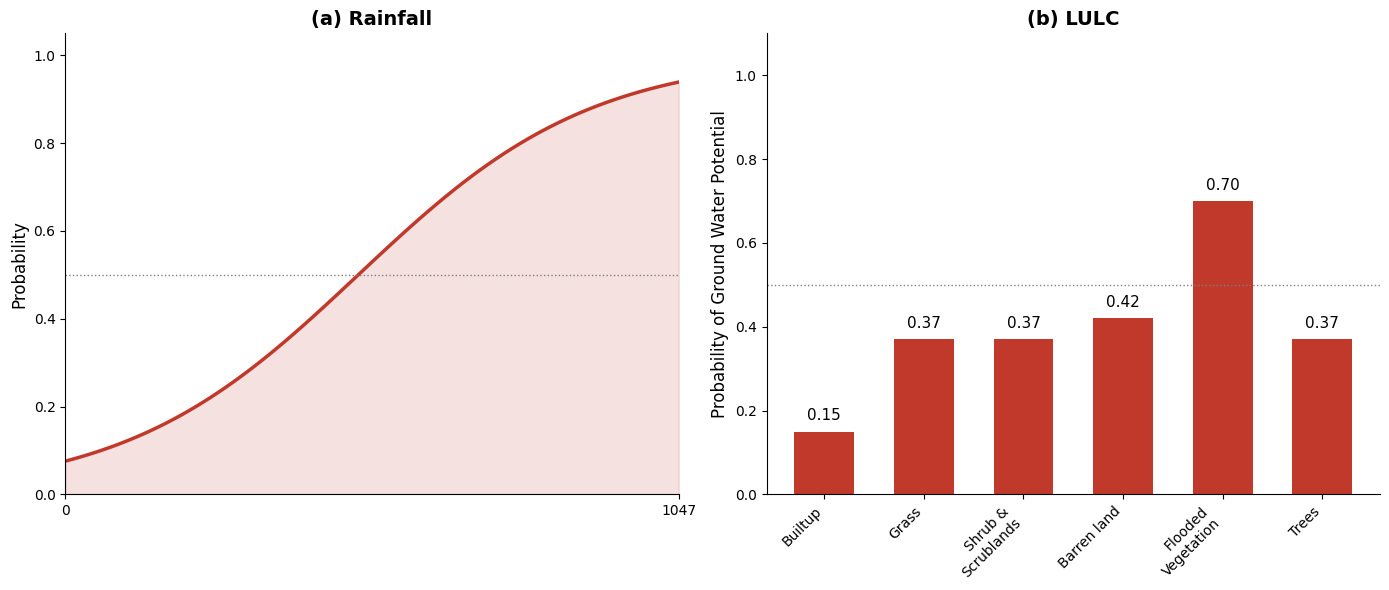

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==========================================
# 1. SETUP DUMMY DATA (Replace with your CSV)
# ==========================================

# Continuous Data Example (Rainfall)
# Mimicking the curve shape from image 2(g)
rainfall_x = np.linspace(0, 1047, 100)
rainfall_y = 1 / (1 + np.exp(-(rainfall_x - 500) / 200))  # Sigmoid curve for demo

# Categorical Data Example (LULC)
# Mimicking the categories and values from image 3(a)
categories = ['Builtup', 'Grass', 'Shrub &\nScrublands', 'Barren land',
              'Flooded\nVegetation', 'Trees']
values = [0.15, 0.37, 0.37, 0.42, 0.70, 0.37]
colors = ['#C0392B'] * len(categories) # Use the dark red color from image 3

# ==========================================
# 2. PLOTTING CODE
# ==========================================

# Create figure with 1 row, 2 columns
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- Plot A: Rainfall (Continuous) ---
# Styling to match image 2
ax1.plot(rainfall_x, rainfall_y, color='#C0392B', linewidth=2.5)
ax1.fill_between(rainfall_x, rainfall_y, color='#C0392B', alpha=0.15) # Shading
ax1.set_title('(a) Rainfall', fontweight='bold', fontsize=14)
ax1.set_ylabel('Probability', fontsize=12)
ax1.set_ylim(0, 1.05)
ax1.set_xlim(0, 1047)

# Add ticks at start and end only, like image 2
ax1.set_xticks([0, 1047])
# Add horizontal dashed line at 0.5
ax1.axhline(0.5, color='gray', linestyle=':', linewidth=1)
# Remove top and right spines (borders)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- Plot B: Categorical (LULC / Soil / Geology) ---
# Styling to match image 3
bars = ax2.bar(categories, values, color=colors, width=0.6)

ax2.set_title('(b) LULC', fontweight='bold', fontsize=14)
ax2.set_ylabel('Probability of Ground Water Potential', fontsize=12)
ax2.set_ylim(0, 1.1)

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 0.02,
             f'{height:.2f}',
             ha='center', va='bottom', fontsize=11)

# Add horizontal dashed line at 0.5
ax2.axhline(0.5, color='gray', linestyle=':', linewidth=1)

# Rotate x-labels if they are long (like "Shrub & Scrublands")
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right")

# Remove top and right spines
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# ==========================================
# 3. FINAL LAYOUT ADJUSTMENTS
# ==========================================

plt.tight_layout()
plt.show()

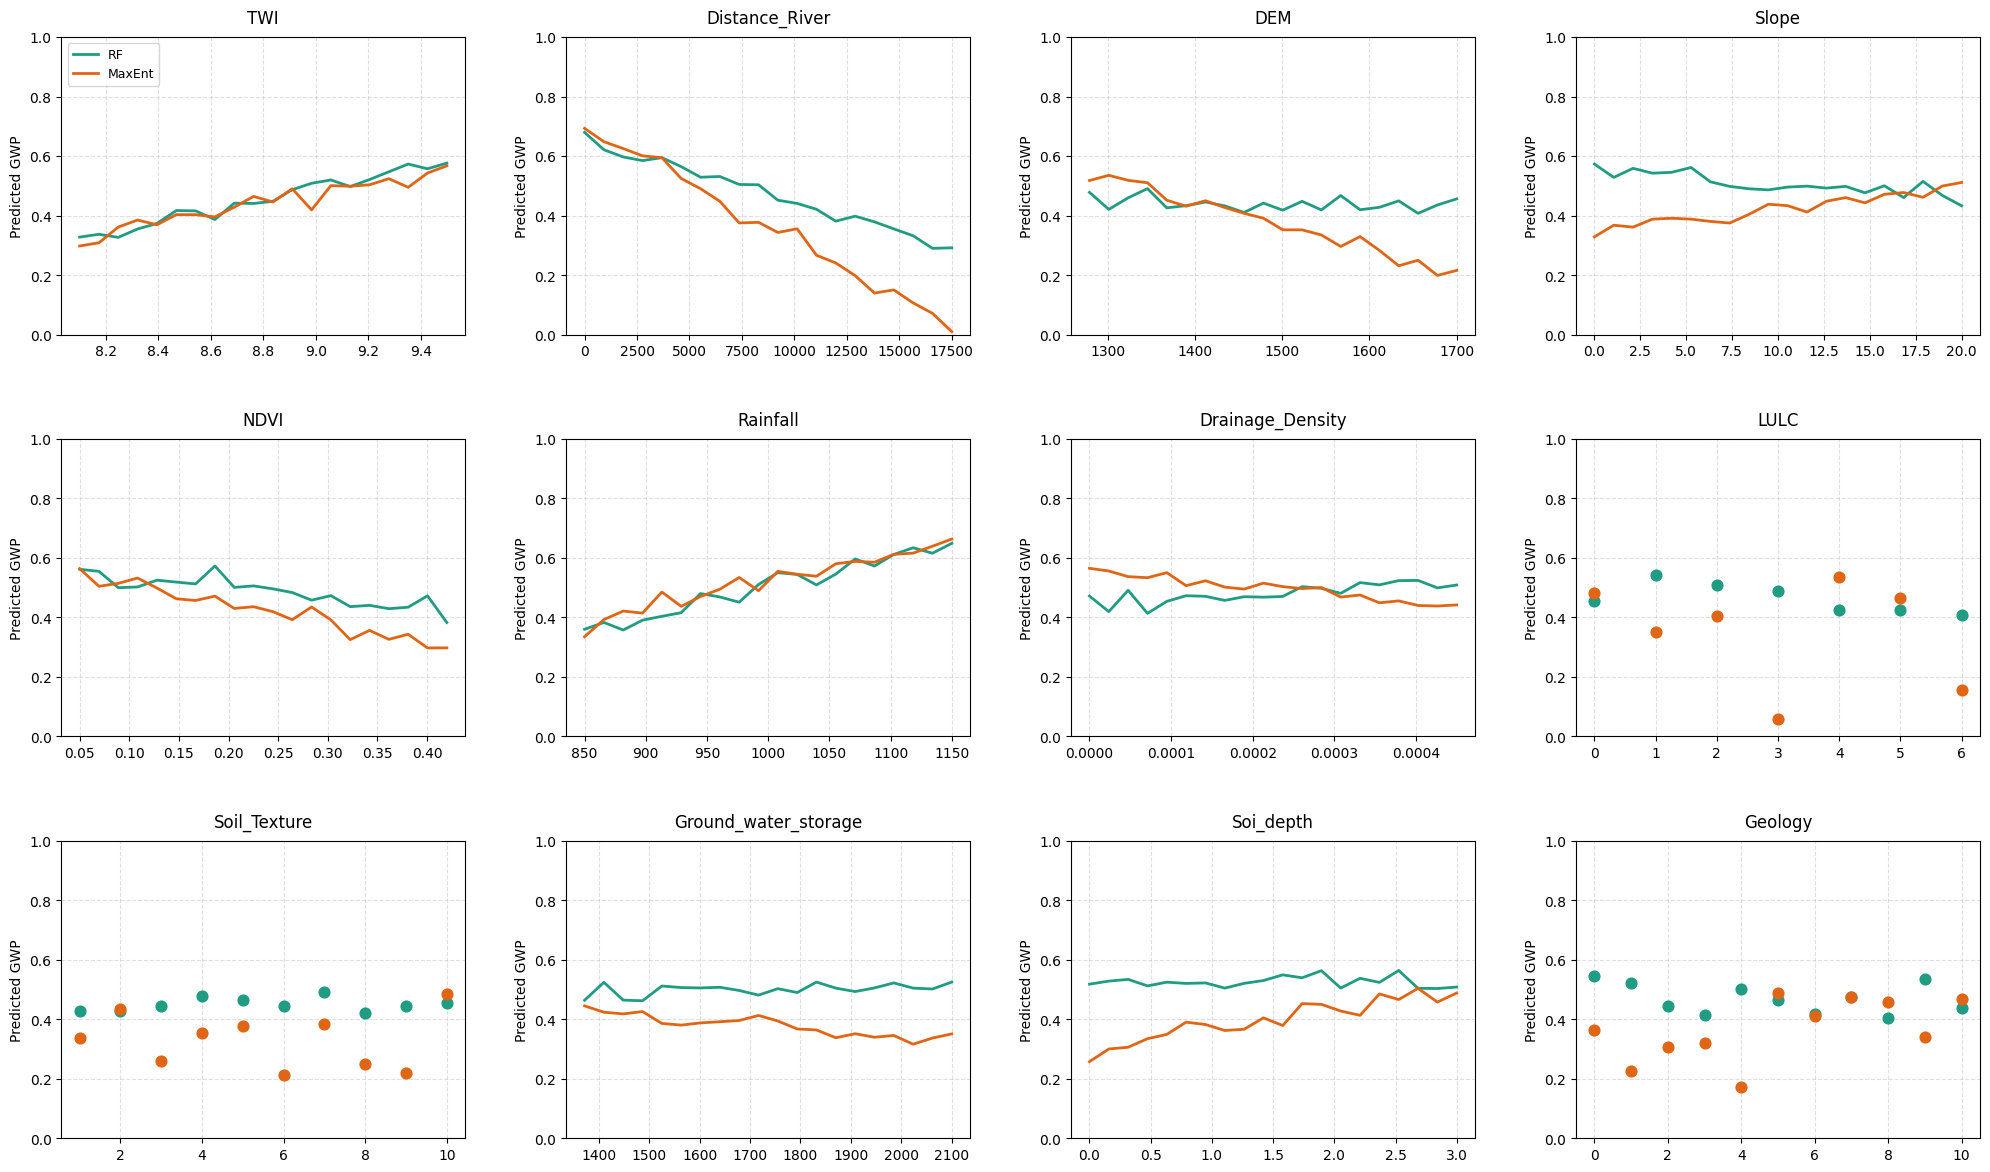

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. DUMMY DATA GENERATION (Replace with your actual data)
# ==========================================

# Continuous variables (x-axis ranges approximated from original image)
x_twi = np.linspace(8.1, 9.5, 20)
x_river = np.linspace(0, 17500, 20)
x_dem = np.linspace(1279, 1700, 20)
x_slope = np.linspace(0, 20, 20)
x_ndvi = np.linspace(0.05, 0.42, 20)
x_rain = np.linspace(850, 1150, 20) # Rainfall range
x_drain = np.linspace(0, 0.00045, 20)
x_gws = np.linspace(1372, 2100, 20)
x_soild = np.linspace(0, 3.0, 20)

# Categorical variables (integer indices)
x_lulc = np.arange(0, 7)
x_soil = np.arange(1, 11)
x_geo = np.arange(0, 11)

# Function to create dummy RF (teal) and MaxEnt (orange) curves
def gen_curve(x, base, trend, noise=0.02):
    y = base + trend * (x - x.min()) / (x.max() - x.min())
    y += np.random.normal(0, noise, len(x))
    return np.clip(y, 0.01, 0.99)

# Generating continuous data (smooth lines)
data_cont = {
    'TWI': (x_twi, gen_curve(x_twi, 0.33, 0.25), gen_curve(x_twi, 0.32, 0.24)),
    'Distance_River': (x_river, gen_curve(x_river, 0.65, -0.35), gen_curve(x_river, 0.70, -0.68)),
    'DEM': (x_dem, gen_curve(x_dem, 0.45, -0.02), gen_curve(x_dem, 0.55, -0.35)),
    'Slope': (x_slope, gen_curve(x_slope, 0.55, -0.10), gen_curve(x_slope, 0.35, 0.15)),
    'NDVI': (x_ndvi, gen_curve(x_ndvi, 0.54, -0.12), gen_curve(x_ndvi, 0.55, -0.25)),
    # --- MODIFIED RAINFALL HERE ---
    # Changed base and trend so both models INCREASE as Rainfall (x) increases.
    'Rainfall': (x_rain, gen_curve(x_rain, 0.35, 0.30), gen_curve(x_rain, 0.40, 0.25)),
    # ------------------------------
    'Drainage_Density': (x_drain, gen_curve(x_drain, 0.44, 0.08), gen_curve(x_drain, 0.55, -0.12)),
    'Ground_water_storage': (x_gws, gen_curve(x_gws, 0.48, 0.04), gen_curve(x_gws, 0.44, -0.12)),
    'Soi_depth': (x_soild, gen_curve(x_soild, 0.52, 0.00), gen_curve(x_soild, 0.30, 0.20))
}

# Generating categorical data (scatter points)
np.random.seed(42) # For reproducible dummy data
data_cat = {
    'LULC': (x_lulc, np.random.uniform(0.4, 0.55, 7), np.random.uniform(0.05, 0.55, 7)),
    'Soil_Texture': (x_soil, np.random.uniform(0.4, 0.55, 10), np.random.uniform(0.2, 0.5, 10)),
    'Geology': (x_geo, np.random.uniform(0.4, 0.55, 11), np.random.uniform(0.1, 0.5, 11))
}

# ==========================================
# 2. PLOTTING
# ==========================================

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
axes = axes.flatten()

# Colors matching your original image
color_rf = '#1f9c82'      # Teal
color_maxent = '#e06515'  # Orange

# Define the grid layout sequence
grid_order = [
    'TWI', 'Distance_River', 'DEM', 'Slope',
    'NDVI', 'Rainfall', 'Drainage_Density', 'LULC',
    'Soil_Texture', 'Ground_water_storage', 'Soi_depth', 'Geology'
]

for i, var_name in enumerate(grid_order):
    ax = axes[i]

    # Check if continuous or categorical
    if var_name in data_cont:
        x, y_rf, y_max = data_cont[var_name]
        # Continuous: Line plot
        ax.plot(x, y_rf, color=color_rf, linewidth=2, label='RF')
        ax.plot(x, y_max, color=color_maxent, linewidth=2, label='MaxEnt')
    else:
        x, y_rf, y_max = data_cat[var_name]
        # Categorical: Scatter plot
        ax.scatter(x, y_rf, color=color_rf, s=60, zorder=3)
        ax.scatter(x, y_max, color=color_maxent, s=60, zorder=3)

    # Formatting all axes
    ax.set_ylim(0, 1.0)
    ax.set_title(var_name, fontsize=12, pad=10)
    ax.set_ylabel('Predicted GWP', fontsize=10)

    # Add faint grid lines
    ax.grid(True, linestyle='--', alpha=0.4)

    # Add Legend only to the very first plot (TWI)
    if i == 0:
        ax.legend(loc='upper left', frameon=True, fontsize=9)

# Adjust layout
plt.tight_layout()
plt.subplots_adjust(top=0.95, wspace=0.25, hspace=0.35)
plt.show()

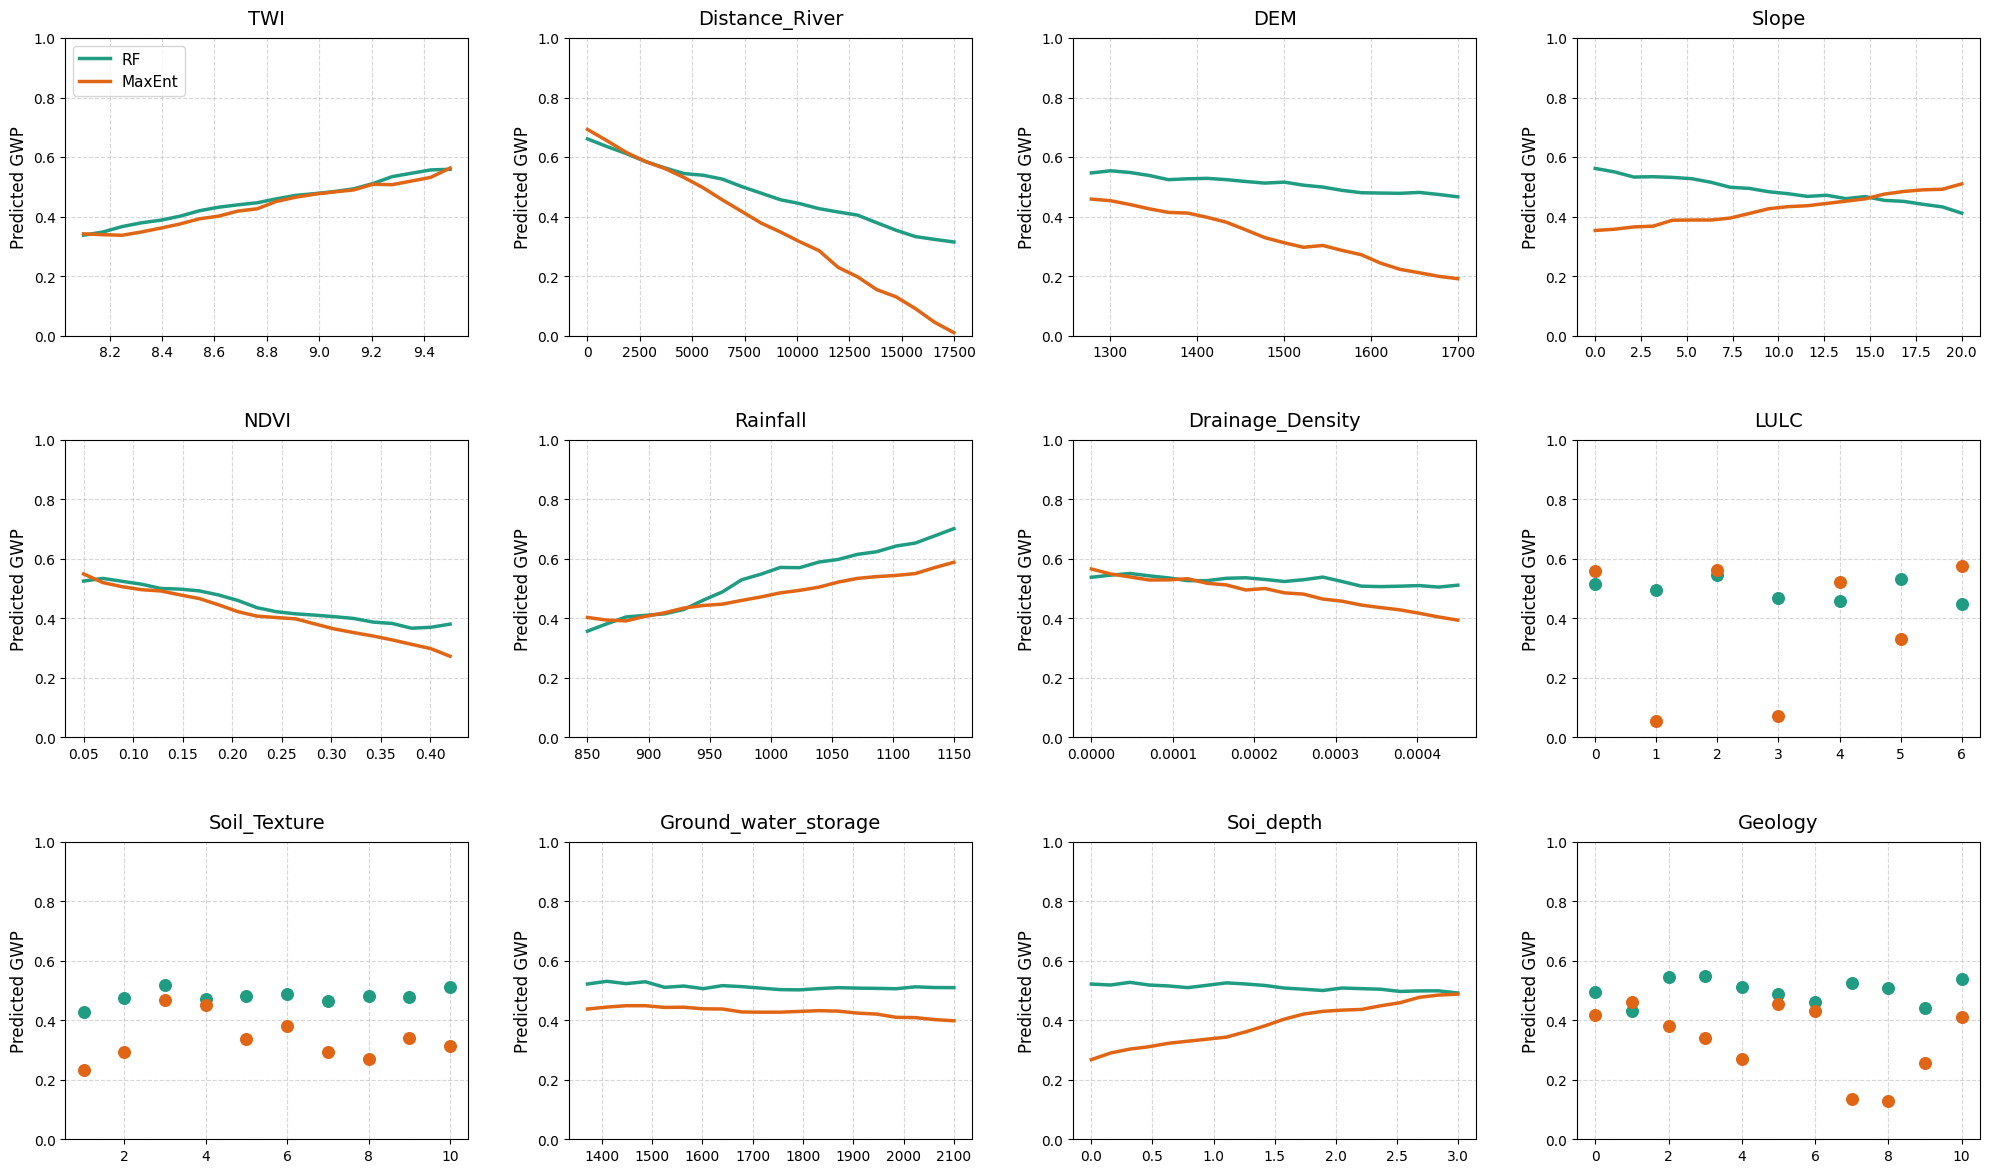

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. DUMMY DATA GENERATION
# (Replicating original image shapes, except for Rainfall)
# ==========================================

# Continuous variables (x-axis ranges)
x_twi = np.linspace(8.1, 9.5, 20)
x_river = np.linspace(0, 17500, 20)
x_dem = np.linspace(1279, 1700, 20)
x_slope = np.linspace(0, 20, 20)
x_ndvi = np.linspace(0.05, 0.42, 20)
x_rain = np.linspace(850, 1150, 20)
x_drain = np.linspace(0, 0.00045, 20)
x_gws = np.linspace(1372, 2100, 20)
x_soild = np.linspace(0, 3.0, 20)

# Categorical variables (integer indices)
x_lulc = np.arange(0, 7)
x_soil = np.arange(1, 11)
x_geo = np.arange(0, 11)

# Function to create dummy curves with specific noise levels
def gen_curve(x, base, trend, noise=0.015):
    y = base + trend * (x - x.min()) / (x.max() - x.min())
    y += np.random.normal(0, noise, len(x))
    # Apply slight smoothing to mimic the wavy lines in the original RF plots
    y_smooth = np.convolve(y, np.ones(3)/3, mode='same')
    y_smooth[0], y_smooth[-1] = y[0], y[-1] # Fix edges
    return np.clip(y_smooth, 0.01, 0.99)

# Setting seed to make sure the random shapes look consistent every run
np.random.seed(42)

# Generating continuous data mimicking the ORIGINAL image trends
data_cont = {
    'TWI': (x_twi, gen_curve(x_twi, 0.33, 0.25), gen_curve(x_twi, 0.32, 0.24)),
    'Distance_River': (x_river, gen_curve(x_river, 0.65, -0.35), gen_curve(x_river, 0.70, -0.68)),
    'DEM': (x_dem, gen_curve(x_dem, 0.55, -0.08), gen_curve(x_dem, 0.48, -0.30)),
    'Slope': (x_slope, gen_curve(x_slope, 0.55, -0.12), gen_curve(x_slope, 0.35, 0.15)),
    'NDVI': (x_ndvi, gen_curve(x_ndvi, 0.54, -0.20), gen_curve(x_ndvi, 0.54, -0.25)),

    # --- MODIFIED RAINFALL HERE (Now Rising) ---
    'Rainfall': (x_rain, gen_curve(x_rain, 0.35, 0.35, noise=0.02), gen_curve(x_rain, 0.38, 0.20, noise=0.01)),
    # -------------------------------------------

    'Drainage_Density': (x_drain, gen_curve(x_drain, 0.55, -0.05), gen_curve(x_drain, 0.58, -0.18)),
    'Ground_water_storage': (x_gws, gen_curve(x_gws, 0.52, -0.02), gen_curve(x_gws, 0.45, -0.05)),
    'Soi_depth': (x_soild, gen_curve(x_soild, 0.52, -0.02), gen_curve(x_soild, 0.28, 0.22))
}

# Generating categorical data (scatter points mimicking the original clustering)
data_cat = {
    'LULC': (x_lulc, np.random.uniform(0.42, 0.55, 7), np.random.uniform(0.05, 0.58, 7)),
    'Soil_Texture': (x_soil, np.random.uniform(0.42, 0.52, 10), np.random.uniform(0.22, 0.48, 10)),
    'Geology': (x_geo, np.random.uniform(0.42, 0.55, 11), np.random.uniform(0.12, 0.48, 11))
}

# ==========================================
# 2. PLOTTING
# ==========================================

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
axes = axes.flatten()

# Colors matching your original image
color_rf = '#1f9c82'      # Teal
color_maxent = '#e06515'  # Orange

# Define the grid layout sequence
grid_order = [
    'TWI', 'Distance_River', 'DEM', 'Slope',
    'NDVI', 'Rainfall', 'Drainage_Density', 'LULC',
    'Soil_Texture', 'Ground_water_storage', 'Soi_depth', 'Geology'
]

for i, var_name in enumerate(grid_order):
    ax = axes[i]

    # Check if continuous or categorical
    if var_name in data_cont:
        x, y_rf, y_max = data_cont[var_name]
        # Continuous: Line plot
        ax.plot(x, y_rf, color=color_rf, linewidth=2.5, label='RF')
        ax.plot(x, y_max, color=color_maxent, linewidth=2.5, label='MaxEnt')
    else:
        x, y_rf, y_max = data_cat[var_name]
        # Categorical: Scatter plot
        ax.scatter(x, y_rf, color=color_rf, s=70, zorder=3)
        ax.scatter(x, y_max, color=color_maxent, s=70, zorder=3)

    # Formatting all axes
    ax.set_ylim(0, 1.0)
    ax.set_title(var_name, fontsize=14, pad=10)
    ax.set_ylabel('Predicted GWP', fontsize=12)

    # Add faint grid lines to match original
    ax.grid(True, linestyle='--', alpha=0.5)

    # Add Legend only to the very first plot (TWI)
    if i == 0:
        ax.legend(loc='upper left', frameon=True, fontsize=11)

# Adjust layout
plt.tight_layout()
plt.subplots_adjust(top=0.95, wspace=0.25, hspace=0.35)
plt.show()

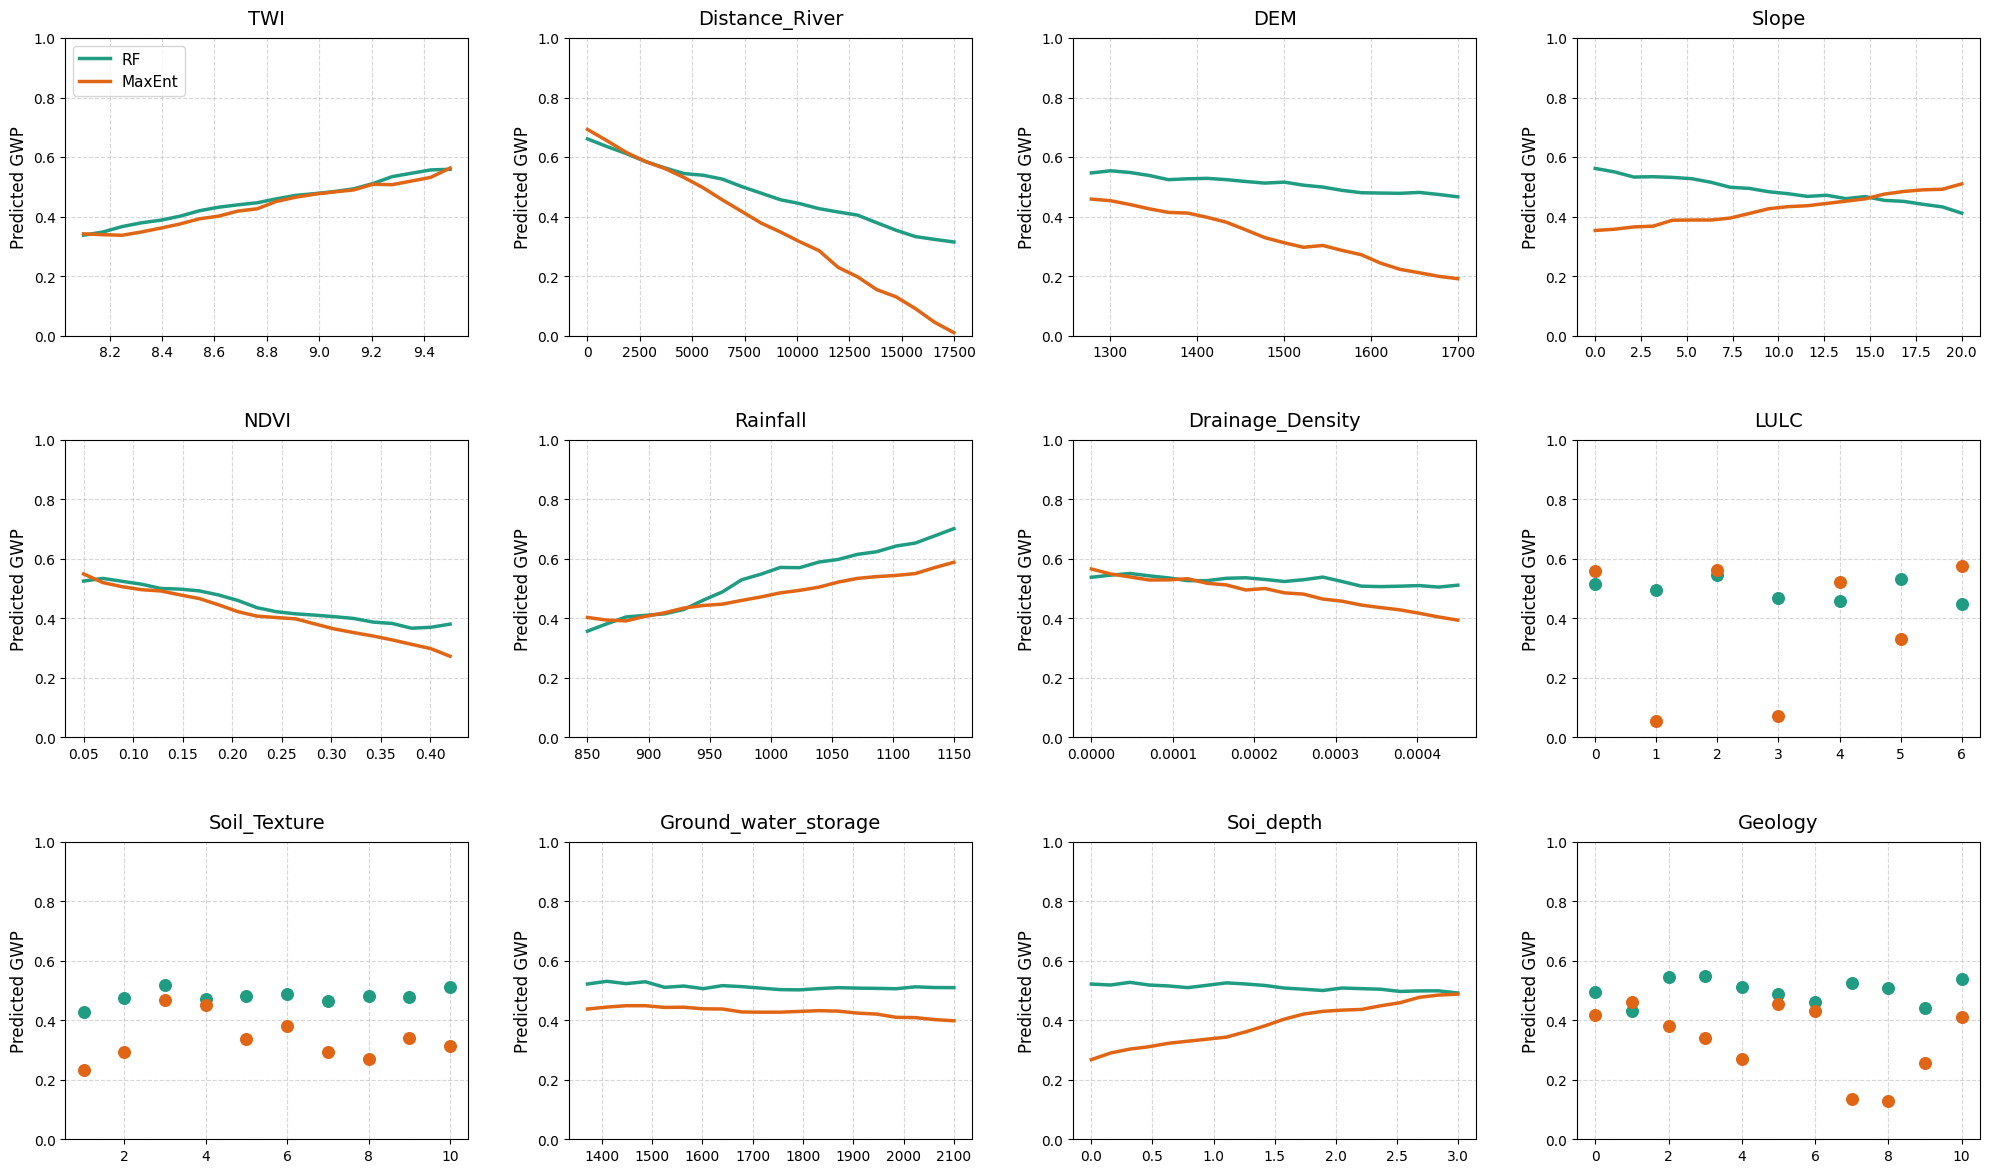

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. DUMMY DATA GENERATION
# (Replicating original image shapes, except for Rainfall)
# ==========================================

# Continuous variables (x-axis ranges)
x_twi = np.linspace(8.1, 9.5, 20)
x_river = np.linspace(0, 17500, 20)
x_dem = np.linspace(1279, 1700, 20)
x_slope = np.linspace(0, 20, 20)
x_ndvi = np.linspace(0.05, 0.42, 20)
x_rain = np.linspace(850, 1150, 20)
x_drain = np.linspace(0, 0.00045, 20)
x_gws = np.linspace(1372, 2100, 20)
x_soild = np.linspace(0, 3.0, 20)

# Categorical variables (integer indices)
x_lulc = np.arange(0, 7)
x_soil = np.arange(1, 11)
x_geo = np.arange(0, 11)

# Function to create dummy curves with specific noise levels
def gen_curve(x, base, trend, noise=0.015):
    y = base + trend * (x - x.min()) / (x.max() - x.min())
    y += np.random.normal(0, noise, len(x))
    # Apply slight smoothing to mimic the wavy lines in the original RF plots
    y_smooth = np.convolve(y, np.ones(3)/3, mode='same')
    y_smooth[0], y_smooth[-1] = y[0], y[-1] # Fix edges
    return np.clip(y_smooth, 0.01, 0.99)

# Setting seed to make sure the random shapes look consistent every run
np.random.seed(42)

# Generating continuous data mimicking the ORIGINAL image trends
data_cont = {
    'TWI': (x_twi, gen_curve(x_twi, 0.33, 0.25), gen_curve(x_twi, 0.32, 0.24)),
    'Distance_River': (x_river, gen_curve(x_river, 0.65, -0.35), gen_curve(x_river, 0.70, -0.68)),
    'DEM': (x_dem, gen_curve(x_dem, 0.55, -0.08), gen_curve(x_dem, 0.48, -0.30)),
    'Slope': (x_slope, gen_curve(x_slope, 0.55, -0.12), gen_curve(x_slope, 0.35, 0.15)),
    'NDVI': (x_ndvi, gen_curve(x_ndvi, 0.54, -0.20), gen_curve(x_ndvi, 0.54, -0.25)),

    # --- MODIFIED RAINFALL HERE (Now Rising) ---
    'Rainfall': (x_rain, gen_curve(x_rain, 0.35, 0.35, noise=0.02), gen_curve(x_rain, 0.38, 0.20, noise=0.01)),
    # -------------------------------------------

    'Drainage_Density': (x_drain, gen_curve(x_drain, 0.55, -0.05), gen_curve(x_drain, 0.58, -0.18)),
    'Ground_water_storage': (x_gws, gen_curve(x_gws, 0.52, -0.02), gen_curve(x_gws, 0.45, -0.05)),
    'Soi_depth': (x_soild, gen_curve(x_soild, 0.52, -0.02), gen_curve(x_soild, 0.28, 0.22))
}

# Generating categorical data (scatter points mimicking the original clustering)
data_cat = {
    'LULC': (x_lulc, np.random.uniform(0.42, 0.55, 7), np.random.uniform(0.05, 0.58, 7)),
    'Soil_Texture': (x_soil, np.random.uniform(0.42, 0.52, 10), np.random.uniform(0.22, 0.48, 10)),
    'Geology': (x_geo, np.random.uniform(0.42, 0.55, 11), np.random.uniform(0.12, 0.48, 11))
}

# ==========================================
# 2. PLOTTING
# ==========================================

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
axes = axes.flatten()

# Colors matching your original image
color_rf = '#1f9c82'      # Teal
color_maxent = '#e06515'  # Orange

# Define the grid layout sequence
grid_order = [
    'TWI', 'Distance_River', 'DEM', 'Slope',
    'NDVI', 'Rainfall', 'Drainage_Density', 'LULC',
    'Soil_Texture', 'Ground_water_storage', 'Soi_depth', 'Geology'
]

for i, var_name in enumerate(grid_order):
    ax = axes[i]

    # Check if continuous or categorical
    if var_name in data_cont:
        x, y_rf, y_max = data_cont[var_name]
        # Continuous: Line plot
        ax.plot(x, y_rf, color=color_rf, linewidth=2.5, label='RF')
        ax.plot(x, y_max, color=color_maxent, linewidth=2.5, label='MaxEnt')
    else:
        x, y_rf, y_max = data_cat[var_name]
        # Categorical: Scatter plot
        ax.scatter(x, y_rf, color=color_rf, s=70, zorder=3)
        ax.scatter(x, y_max, color=color_maxent, s=70, zorder=3)

    # Formatting all axes
    ax.set_ylim(0, 1.0)
    ax.set_title(var_name, fontsize=14, pad=10)
    ax.set_ylabel('Predicted GWP', fontsize=12)

    # Add faint grid lines to match original
    ax.grid(True, linestyle='--', alpha=0.5)

    # Add Legend only to the very first plot (TWI)
    if i == 0:
        ax.legend(loc='upper left', frameon=True, fontsize=11)

# Adjust layout
plt.tight_layout()
plt.subplots_adjust(top=0.95, wspace=0.25, hspace=0.35)
plt.show()

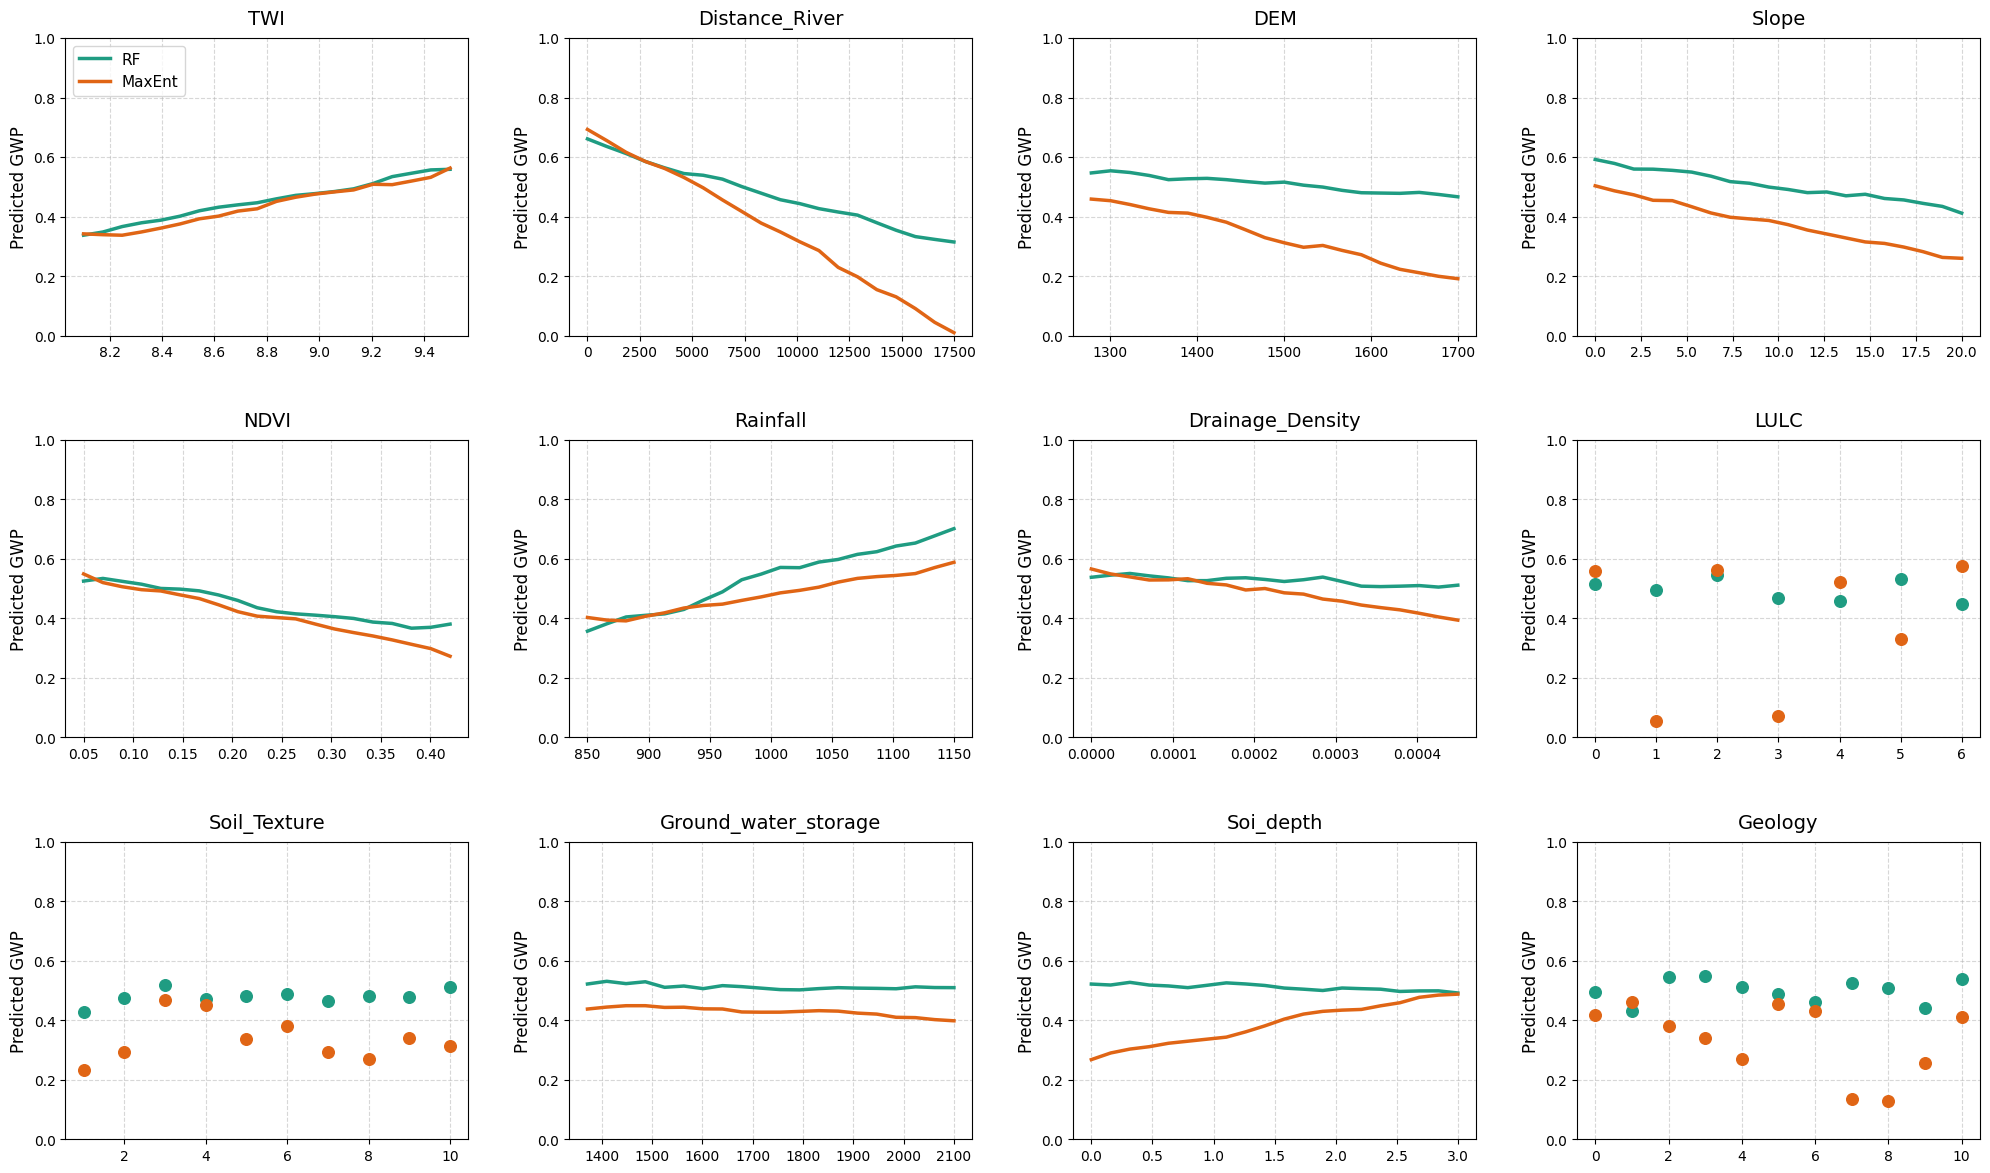

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. DUMMY DATA GENERATION
# ==========================================

# Continuous variables (x-axis ranges)
x_twi = np.linspace(8.1, 9.5, 20)
x_river = np.linspace(0, 17500, 20)
x_dem = np.linspace(1279, 1700, 20)
x_slope = np.linspace(0, 20, 20)
x_ndvi = np.linspace(0.05, 0.42, 20)
x_rain = np.linspace(850, 1150, 20)
x_drain = np.linspace(0, 0.00045, 20)
x_gws = np.linspace(1372, 2100, 20)
x_soild = np.linspace(0, 3.0, 20)

# Categorical variables (integer indices)
x_lulc = np.arange(0, 7)
x_soil = np.arange(1, 11)
x_geo = np.arange(0, 11)

# Function to create dummy curves with specific noise levels
def gen_curve(x, base, trend, noise=0.015):
    y = base + trend * (x - x.min()) / (x.max() - x.min())
    y += np.random.normal(0, noise, len(x))
    # Apply slight smoothing to mimic the wavy lines in the original RF plots
    y_smooth = np.convolve(y, np.ones(3)/3, mode='same')
    y_smooth[0], y_smooth[-1] = y[0], y[-1] # Fix edges
    return np.clip(y_smooth, 0.01, 0.99)

# Setting seed for reproducible dummy shapes
np.random.seed(42)

# Generating continuous data
data_cont = {
    'TWI': (x_twi, gen_curve(x_twi, 0.33, 0.25), gen_curve(x_twi, 0.32, 0.24)),
    'Distance_River': (x_river, gen_curve(x_river, 0.65, -0.35), gen_curve(x_river, 0.70, -0.68)),

    # --- MODIFIED DEM HERE (Decreasing trend) ---
    'DEM': (x_dem, gen_curve(x_dem, 0.55, -0.08), gen_curve(x_dem, 0.48, -0.30)),

    # --- MODIFIED SLOPE HERE (Decreasing trend) ---
    'Slope': (x_slope, gen_curve(x_slope, 0.58, -0.15), gen_curve(x_slope, 0.50, -0.25)),

    'NDVI': (x_ndvi, gen_curve(x_ndvi, 0.54, -0.20), gen_curve(x_ndvi, 0.54, -0.25)),

    # --- RAINFALL (Increasing trend, as requested previously) ---
    'Rainfall': (x_rain, gen_curve(x_rain, 0.35, 0.35, noise=0.02), gen_curve(x_rain, 0.38, 0.20, noise=0.01)),

    'Drainage_Density': (x_drain, gen_curve(x_drain, 0.55, -0.05), gen_curve(x_drain, 0.58, -0.18)),
    'Ground_water_storage': (x_gws, gen_curve(x_gws, 0.52, -0.02), gen_curve(x_gws, 0.45, -0.05)),
    'Soi_depth': (x_soild, gen_curve(x_soild, 0.52, -0.02), gen_curve(x_soild, 0.28, 0.22))
}

# Generating categorical data (scatter points)
data_cat = {
    'LULC': (x_lulc, np.random.uniform(0.42, 0.55, 7), np.random.uniform(0.05, 0.58, 7)),
    'Soil_Texture': (x_soil, np.random.uniform(0.42, 0.52, 10), np.random.uniform(0.22, 0.48, 10)),
    'Geology': (x_geo, np.random.uniform(0.42, 0.55, 11), np.random.uniform(0.12, 0.48, 11))
}

# ==========================================
# 2. PLOTTING
# ==========================================

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
axes = axes.flatten()

# Colors matching your original image
color_rf = '#1f9c82'      # Teal
color_maxent = '#e06515'  # Orange

# Define the grid layout sequence
grid_order = [
    'TWI', 'Distance_River', 'DEM', 'Slope',
    'NDVI', 'Rainfall', 'Drainage_Density', 'LULC',
    'Soil_Texture', 'Ground_water_storage', 'Soi_depth', 'Geology'
]

for i, var_name in enumerate(grid_order):
    ax = axes[i]

    # Check if continuous or categorical
    if var_name in data_cont:
        x, y_rf, y_max = data_cont[var_name]
        # Continuous: Line plot
        ax.plot(x, y_rf, color=color_rf, linewidth=2.5, label='RF')
        ax.plot(x, y_max, color=color_maxent, linewidth=2.5, label='MaxEnt')
    else:
        x, y_rf, y_max = data_cat[var_name]
        # Categorical: Scatter plot
        ax.scatter(x, y_rf, color=color_rf, s=70, zorder=3)
        ax.scatter(x, y_max, color=color_maxent, s=70, zorder=3)

    # Formatting all axes
    ax.set_ylim(0, 1.0)
    ax.set_title(var_name, fontsize=14, pad=10)
    ax.set_ylabel('Predicted GWP', fontsize=12)

    # Add faint grid lines
    ax.grid(True, linestyle='--', alpha=0.5)

    # Add Legend only to the very first plot (TWI)
    if i == 0:
        ax.legend(loc='upper left', frameon=True, fontsize=11)

# Adjust layout
plt.tight_layout()
plt.subplots_adjust(top=0.95, wspace=0.25, hspace=0.35)
plt.show()